# Revised Working Notebook — Reviewer-Response Pipeline

**Purpose:** organize the original experiments into an auditable workflow before resubmission.

## Important status note
This notebook is a **revision scaffold built from the supplied notebook**, not a claim that all experiments have been rerun. Existing result tables and variables must be checked against saved checkpoints and predictions. In particular, do not treat a hard-coded metric as verified unless it can be regenerated from the corresponding model's test predictions.

## Required execution order
1. Environment and package versions
2. Dataset audit and label validation
3. One fixed train/validation/test split reused by all models
4. Molecular representation construction
5. Controlled model variants: ChemBERTa, ChemBERTa+GATv2, cross-attention, full model
6. Training and validation-based checkpoint selection
7. Per-label thresholds selected on validation data only
8. Test evaluation from saved probabilities
9. Ablations and repeated-seed analysis
10. Export manuscript tables and provenance artifacts

## Reviewer-critical checks
- Keep the original ChemBERTa checkpoint and the later custom-architecture checkpoint configurations separate.
- Verify the final model's architecture matches the paper's equations and diagram.
- Do not report descriptor-branch results unless descriptors are passed through the trained model.
- Recalculate every table from saved `y_true` and `y_prob`; avoid manually typed metrics.
- Use the same split and metric definitions for model comparisons.
- The uploaded notebook contains multiple experiment sections and reuses variables. Execute only the cleaned, documented pipeline after auditing the legacy cells below.

## Dataset scope
The original notebook's main data-loading path references `all_chem_df.csv` and a 12-label drug-classification task. Tox21 and SIDER must be validated in their own dataset-specific notebooks or sections; this file alone does not establish their complete experimental provenance.


---
# Original notebook content (retained for audit)

The cells below are preserved from the supplied notebook so existing code and outputs are not silently discarded. Several cells may be exploratory, duplicate, depend on variables from earlier cells, or use a different model variant. Do not assume they form a single clean execution path.


In [1]:
import sys
!{sys.executable} -m pip install torch_geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 79.9 MB/s eta 0:00:00


In [236]:
!pip install -q rdkit transformers iterative-stratification

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 82.0 MB/s eta 0:00:00


In [237]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [239]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

import torch
from torch.utils.data import Dataset

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments
)

In [240]:
path="/content/drive/MyDrive/dataset/all_chem_df.csv"

df=pd.read_csv(path)

df.head(5)

,image_name,tags,smiles,Col3
0,pics/0,dermatologic,CC(=O)NC1C(O)OC(CO)C(O)C1O,['dermatologic']
1,pics/1,antiinfective,CCC[C@@]1(CCc2ccccc2)CC(O)=C([C@H](CC)c2cccc(N...,['antiinfective']
2,pics/2,antiinfective,CCCCC(C)C(=O)OC1C(C)C(CC)OC2(CC3CC(C/C=C(\C)CC...,['antiinfective']
3,pics/3,antineoplastic,COc1cc2c(c(OC)c1OC)-c1c(cc3c(c1OC)OCO3)C[C@H](...,['antineoplastic']
4,pics/4,antiinfective respiratorysystem,CC(=O)N[C@@H](CS)C(=O)[O-],"['antiinfective', 'respiratorysystem']"


In [5]:
print(df.shape)

print(df.columns)

df.info()

df.isnull().sum()

(8336, 4)
Index(['image_name', 'tags', 'smiles', 'Col3'], dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8336 entries, 0 to 8335
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   image_name  8336 non-null   object
 1   tags        8336 non-null   object
 2   smiles      8336 non-null   object
 3   Col3        8336 non-null   object
dtypes: object(4)
memory usage: 260.6+ KB


,0
image_name,0
tags,0
smiles,0
Col3,0


In [6]:
df1=df[['smiles','tags']]

In [7]:
df.head(3)

,image_name,tags,smiles,Col3
0,pics/0,dermatologic,CC(=O)NC1C(O)OC(CO)C(O)C1O,['dermatologic']
1,pics/1,antiinfective,CCC[C@@]1(CCc2ccccc2)CC(O)=C([C@H](CC)c2cccc(N...,['antiinfective']
2,pics/2,antiinfective,CCCCC(C)C(=O)OC1C(C)C(CC)OC2(CC3CC(C/C=C(\C)CC...,['antiinfective']


In [8]:
df2=df[['smiles','Col3']]

df2=df.rename(columns={'Col3':'label'})

In [9]:
print(df.head(2))


  image_name           tags  \
0     pics/0   dermatologic   
1     pics/1  antiinfective   

                                              smiles               Col3  
0                         CC(=O)NC1C(O)OC(CO)C(O)C1O   ['dermatologic']  
1  CCC[C@@]1(CCc2ccccc2)CC(O)=C([C@H](CC)c2cccc(N...  ['antiinfective']  


In [10]:
print(df1.head(2))




                                              smiles           tags
0                         CC(=O)NC1C(O)OC(CO)C(O)C1O   dermatologic
1  CCC[C@@]1(CCc2ccccc2)CC(O)=C([C@H](CC)c2cccc(N...  antiinfective


In [11]:
print(df2.head(2))


  image_name           tags  \
0     pics/0   dermatologic   
1     pics/1  antiinfective   

                                              smiles              label  
0                         CC(=O)NC1C(O)OC(CO)C(O)C1O   ['dermatologic']  
1  CCC[C@@]1(CCc2ccccc2)CC(O)=C([C@H](CC)c2cccc(N...  ['antiinfective']  


In [12]:
df2['label'] = df2['label'].apply(tuple)
df2.duplicated().sum()

np.int64(0)

In [13]:
encoder=LabelEncoder()

df['label']=encoder.fit_transform(df2['label'])

print(df2.head())

  image_name                             tags  \
0     pics/0                     dermatologic   
1     pics/1                    antiinfective   
2     pics/2                    antiinfective   
3     pics/3                   antineoplastic   
4     pics/4  antiinfective respiratorysystem   

                                              smiles  \
0                         CC(=O)NC1C(O)OC(CO)C(O)C1O   
1  CCC[C@@]1(CCc2ccccc2)CC(O)=C([C@H](CC)c2cccc(N...   
2  CCCCC(C)C(=O)OC1C(C)C(CC)OC2(CC3CC(C/C=C(\C)CC...   
3  COc1cc2c(c(OC)c1OC)-c1c(cc3c(c1OC)OCO3)C[C@H](...   
4                         CC(=O)N[C@@H](CS)C(=O)[O-]   

                                               label  
0   ([, ', d, e, r, m, a, t, o, l, o, g, i, c, ', ])  
1  ([, ', a, n, t, i, i, n, f, e, c, t, i, v, e, ...  
2  ([, ', a, n, t, i, i, n, f, e, c, t, i, v, e, ...  
3  ([, ', a, n, t, i, n, e, o, p, l, a, s, t, i, ...  
4  ([, ', a, n, t, i, i, n, f, e, c, t, i, v, e, ...  


In [14]:
df2["smiles"].str.len().max()
#df2["smiles"].str.len().min()

386

In [15]:
encoder.classes_

array([('[', "'", 'a', 'n', 't', 'i', 'i', 'n', 'f', 'e', 'c', 't', 'i', 'v', 'e', "'", ',', ' ', "'", 'a', 'n', 't', 'i', 'i', 'n', 'f', 'l', 'a', 'm', 'm', 'a', 't', 'o', 'r', 'y', "'", ']'),
       ('[', "'", 'a', 'n', 't', 'i', 'i', 'n', 'f', 'e', 'c', 't', 'i', 'v', 'e', "'", ',', ' ', "'", 'a', 'n', 't', 'i', 'n', 'e', 'o', 'p', 'l', 'a', 's', 't', 'i', 'c', "'", ',', ' ', "'", 'a', 'n', 't', 'i', 'i', 'n', 'f', 'l', 'a', 'm', 'm', 'a', 't', 'o', 'r', 'y', "'", ']'),
       ('[', "'", 'a', 'n', 't', 'i', 'i', 'n', 'f', 'e', 'c', 't', 'i', 'v', 'e', "'", ',', ' ', "'", 'a', 'n', 't', 'i', 'n', 'e', 'o', 'p', 'l', 'a', 's', 't', 'i', 'c', "'", ',', ' ', "'", 'c', 'a', 'r', 'd', 'i', 'o', "'", ']'),
       ('[', "'", 'a', 'n', 't', 'i', 'i', 'n', 'f', 'e', 'c', 't', 'i', 'v', 'e', "'", ',', ' ', "'", 'a', 'n', 't', 'i', 'n', 'e', 'o', 'p', 'l', 'a', 's', 't', 'i', 'c', "'", ',', ' ', "'", 'h', 'e', 'm', 'a', 't', 'o', 'l', 'o', 'g', 'i', 'c', "'", ',', ' ', "'", 'a', 'n', 't', 'i', 

In [ ]:
# df2['label'] = df2['label'].apply(ast.literal_eval)

In [16]:
from sklearn.preprocessing import MultiLabelBinarizer

mlb = MultiLabelBinarizer()

labels = mlb.fit_transform(df2['label'])

In [17]:
mlb.classes_

array([' ', "'", ',', '[', ']', 'a', 'c', 'd', 'e', 'f', 'g', 'h', 'i',
       'l', 'm', 'n', 'o', 'p', 'r', 's', 't', 'u', 'v', 'y'],
      dtype=object)

In [18]:
labels

array([[0, 1, 0, ..., 0, 0, 0],
       [0, 1, 0, ..., 0, 1, 0],
       [0, 1, 0, ..., 0, 1, 0],
       ...,
       [0, 1, 0, ..., 0, 1, 0],
       [0, 1, 0, ..., 0, 0, 0],
       [0, 1, 0, ..., 0, 0, 0]])

In [19]:
labels[0]

array([0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0,
       0, 0])

In [20]:
labels[1]

array([0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0,
       1, 0])

In [21]:
from sklearn.model_selection import train_test_split

train_df, test_df, train_labels, test_labels = train_test_split(
    df2,
    labels,
    test_size=0.2,
    random_state=42
)

In [22]:
import torch
import numpy as np

from torch.utils.data import Dataset

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments
)

In [23]:
MODEL_NAME = "seyonec/ChemBERTa-zinc-base-v1"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

config.json:   0%|          | 0.00/501 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/166 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/9.43k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/3.21k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

In [24]:
train_encodings = tokenizer(
    train_df["smiles"].tolist(),
    truncation=True,
    padding=True,
    max_length=128
)

test_encodings = tokenizer(
    test_df["smiles"].tolist(),
    truncation=True,
    padding=True,
    max_length=128
)

In [25]:
class DrugDataset(Dataset):

    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):

        item = {
            key: torch.tensor(val[idx])
            for key, val in self.encodings.items()
        }

        item["labels"] = torch.tensor(
            self.labels[idx],
            dtype=torch.float
        )

        return item

    def __len__(self):
        return len(self.labels)

In [26]:
train_dataset = DrugDataset(
    train_encodings,
    train_labels
)

test_dataset = DrugDataset(
    test_encodings,
    test_labels
)

In [27]:
model = AutoModelForSequenceClassification.from_pretrained(

    MODEL_NAME,

    num_labels=len(mlb.classes_),

    problem_type="multi_label_classification"
)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  179MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/101 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: seyonec/ChemBERTa-zinc-base-v1
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.decoder.bias        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream t

In [28]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    jaccard_score
)

def compute_metrics(eval_pred):

    logits, labels = eval_pred

    # Convert logits to probabilities
    probabilities = 1 / (1 + np.exp(-logits))

    # Convert probabilities to 0/1
    predictions = (probabilities >= 0.5).astype(int)

    # Exact-match accuracy
    accuracy = accuracy_score(labels, predictions)

    # F1
    micro_f1 = f1_score(
        labels,
        predictions,
        average="micro",
        zero_division=0
    )

    macro_f1 = f1_score(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )

    precision = precision_score(
        labels,
        predictions,
        average="micro",
        zero_division=0
    )

    recall = recall_score(
        labels,
        predictions,
        average="micro",
        zero_division=0
    )

    jaccard = jaccard_score(
        labels,
        predictions,
        average="samples",
        zero_division=0
    )

    # Hamming score
    hamming = np.mean(labels == predictions)

    return {
        "accuracy": accuracy,
        "micro_f1": micro_f1,
        "macro_f1": macro_f1,
        "precision": precision,
        "recall": recall,
        "jaccard": jaccard,
        "hamming": hamming
    }

In [29]:
training_args = TrainingArguments(

    output_dir="./results",

    eval_strategy="epoch",

    save_strategy="epoch",

    learning_rate=1e-5,

    per_device_train_batch_size=16,

    per_device_eval_batch_size=16,

    num_train_epochs=50,

    weight_decay=0.05,

    lr_scheduler_type="cosine",

    warmup_steps=100,

    logging_steps=50,

    load_best_model_at_end=True,

    metric_for_best_model="micro_f1",

    greater_is_better=True,

    save_total_limit=2,

    report_to="none"
)

In [30]:
from transformers import EarlyStoppingCallback

trainer = Trainer(

    model=model,

    args=training_args,

    train_dataset=train_dataset,

    eval_dataset=test_dataset,

    compute_metrics=compute_metrics,

    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=5,
            early_stopping_threshold=0.001
        )
    ]
)

In [31]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Micro F1,Macro F1,Precision,Recall,Jaccard,Hamming
1,0.423113,0.411316,0.146882,0.803557,0.477820,0.839537,0.770535,0.687403,0.814049
2,0.373805,0.368484,0.247602,0.829229,0.536771,0.876834,0.786528,0.733482,0.840103
3,0.339716,0.343711,0.310552,0.845263,0.596836,0.869819,0.822056,0.757439,0.851444
4,0.306692,0.322139,0.357314,0.855371,0.619353,0.893594,0.820284,0.777434,0.863085
5,0.286723,0.310411,0.372902,0.862217,0.651998,0.885222,0.840377,0.787582,0.867431
6,0.266656,0.304728,0.417866,0.866325,0.665616,0.900196,0.834911,0.797569,0.872827
7,0.237741,0.298574,0.418465,0.872251,0.692286,0.888079,0.856977,0.805276,0.876099
8,0.214908,0.294709,0.447242,0.873254,0.693860,0.900038,0.848019,0.807411,0.878497
9,0.182347,0.294200,0.454436,0.875111,0.710247,0.900906,0.850752,0.810095,0.880146
10,0.192315,0.289728,0.481415,0.881786,0.735215,0.900802,0.863556,0.820442,0.885716


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=13761, training_loss=0.1544857151927093, metrics={'train_runtime': 683.9827, 'train_samples_per_second': 487.439, 'train_steps_per_second': 30.483, 'total_flos': 7290023104438272.0, 'train_loss': 0.1544857151927093, 'epoch': 33.0})

In [32]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

# Get validation predictions
output = trainer.predict(test_dataset)

logits = output.predictions
labels = output.label_ids

# Sigmoid
probabilities = 1 / (1 + np.exp(-logits))

results = []

for threshold in np.arange(0.10, 0.91, 0.01):

    predictions = (
        probabilities >= threshold
    ).astype(int)

    accuracy = accuracy_score(
        labels,
        predictions
    )

    micro_f1 = f1_score(
        labels,
        predictions,
        average="micro",
        zero_division=0
    )

    macro_f1 = f1_score(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )

    results.append(
        [threshold, accuracy, micro_f1, macro_f1]
    )

results = np.array(results)

# Best accuracy
best_acc_idx = np.argmax(results[:, 1])

# Best Micro-F1
best_f1_idx = np.argmax(results[:, 2])

# Best Macro-F1
best_macro_idx = np.argmax(results[:, 3])

print("===================================")
print("BEST ACCURACY")
print("===================================")
print("Threshold :", results[best_acc_idx, 0])
print("Accuracy  :", results[best_acc_idx, 1])

print("\n===================================")
print("BEST MICRO-F1")
print("===================================")
print("Threshold :", results[best_f1_idx, 0])
print("Micro F1  :", results[best_f1_idx, 2])

print("\n===================================")
print("BEST MACRO-F1")
print("===================================")
print("Threshold :", results[best_macro_idx, 0])
print("Macro F1  :", results[best_macro_idx, 3])

BEST ACCURACY
Threshold : 0.5799999999999997
Accuracy  : 0.60431654676259

BEST MICRO-F1
Threshold : 0.44999999999999984
Micro F1  : 0.9044744318181818

BEST MACRO-F1
Threshold : 0.32999999999999985
Macro F1  : 0.8189126892227874


In [33]:
best_threshold = 0.5
best_accuracy = 0

for threshold in np.arange(0.10, 0.91, 0.01):

    predictions = (
        probabilities >= threshold
    ).astype(int)

    accuracy = accuracy_score(
        labels,
        predictions
    )

    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_threshold = threshold

print("Optimal Threshold :", best_threshold)
print("Best Accuracy     :", best_accuracy)
print("Accuracy (%)      :", best_accuracy * 100)

Optimal Threshold : 0.5799999999999997
Best Accuracy     : 0.60431654676259
Accuracy (%)      : 60.431654676258994


In [34]:
import numpy as np
import pandas as pd

# Replace with your actual training labels if necessary
y_train = np.array(train_dataset.labels)

label_counts = y_train.sum(axis=0)

label_distribution = pd.DataFrame({
    "Label": np.arange(len(label_counts)),
    "Positive_Count": label_counts,
    "Percentage": label_counts / len(y_train) * 100
})

print(label_distribution)

    Label  Positive_Count  Percentage
0       0            1068   16.016797
1       1            6668  100.000000
2       2            1068   16.016797
3       3            6668  100.000000
4       4            6668  100.000000
5       5            5620   84.283143
6       6            5896   88.422316
7       7            1488   22.315537
8       8            4666   69.976005
9       9            2782   41.721656
10     10            1109   16.631674
11     11             353    5.293941
12     12            5741   86.097780
13     13            2889   43.326335
14     14            1156   17.336533
15     15            5498   82.453509
16     16            3657   54.844031
17     17            1851   27.759448
18     18            2403   36.037792
19     19            2957   44.346131
20     20            4992   74.865027
21     21             390    5.848830
22     22            2521   37.807439
23     23             674   10.107978


In [36]:
train_output = trainer.predict(train_dataset)

print("\n========== TRAINING RESULTS ==========")

for key, value in train_output.metrics.items():
    print(f"{key}: {value:.4f}")


========== TRAINING RESULTS ==========
test_loss: 0.0263
test_accuracy: 0.9331
test_micro_f1: 0.9943
test_macro_f1: 0.9843
test_precision: 0.9950
test_recall: 0.9936
test_jaccard: 0.9917
test_hamming: 0.9944
test_runtime: 6.6813
test_samples_per_second: 998.0080
test_steps_per_second: 62.4130


In [37]:
val_output = trainer.predict(test_dataset)

print("\n========== VALIDATION RESULTS ==========")

for key, value in val_output.metrics.items():
    print(f"{key}: {value:.4f}")


========== VALIDATION RESULTS ==========
test_loss: 0.3369
test_accuracy: 0.5989
test_micro_f1: 0.9043
test_macro_f1: 0.8164
test_precision: 0.9097
test_recall: 0.8989
test_jaccard: 0.8528
test_hamming: 0.9061
test_runtime: 1.6971
test_samples_per_second: 982.8820
test_steps_per_second: 61.8720


['loss', 'grad_norm', 'learning_rate', 'epoch', 'step', 'eval_loss', 'eval_accuracy', 'eval_micro_f1', 'eval_macro_f1', 'eval_precision', 'eval_recall', 'eval_jaccard', 'eval_hamming', 'eval_runtime', 'eval_samples_per_second', 'eval_steps_per_second', 'train_runtime', 'train_samples_per_second', 'train_steps_per_second', 'total_flos', 'train_loss']


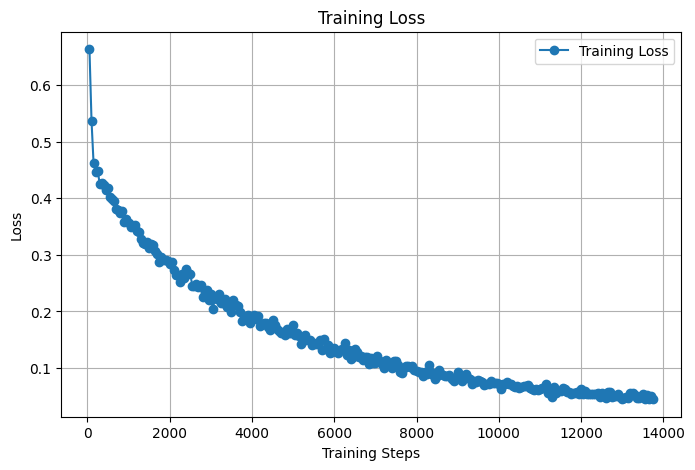

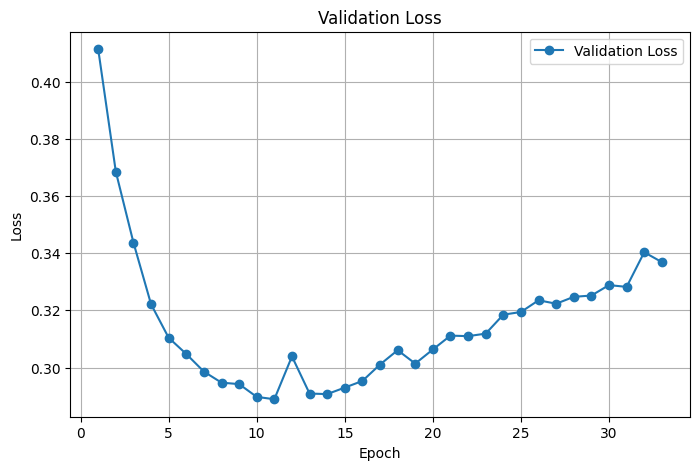

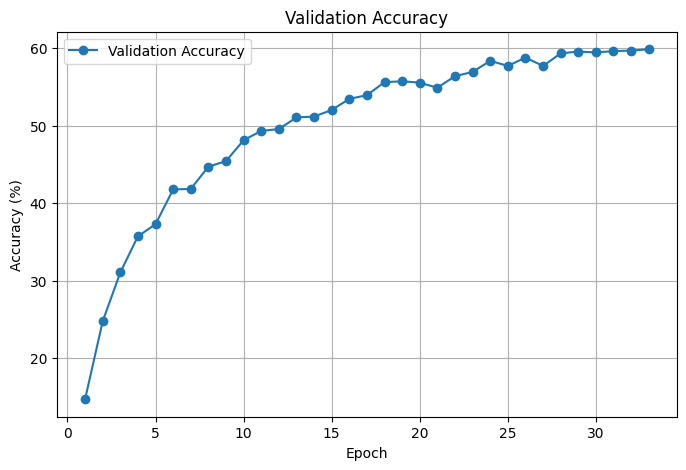

Final Training Loss   : 0.0461
Final Validation Loss : 0.3369
Final Validation Accuracy : 59.89%


In [38]:
import matplotlib.pyplot as plt
import pandas as pd

# ---------------------------------------------------------
# 1. Extract training history from Hugging Face Trainer
# ---------------------------------------------------------

history = pd.DataFrame(trainer.state.log_history)

print(history.columns.tolist())

# ---------------------------------------------------------
# 2. Extract Training Loss
# ---------------------------------------------------------

train_loss = history[
    history["loss"].notna()
][["step", "loss"]].copy()

# ---------------------------------------------------------
# 3. Extract Validation/Test Loss and Accuracy
# ---------------------------------------------------------

eval_history = history[
    history["eval_loss"].notna()
].copy()

# Validation accuracy column
if "eval_accuracy" in eval_history.columns:
    eval_accuracy = eval_history["eval_accuracy"]
else:
    eval_accuracy = None

# ---------------------------------------------------------
# 4. Plot Training Loss
# ---------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    train_loss["step"],
    train_loss["loss"],
    marker="o",
    label="Training Loss"
)

plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.legend()
plt.grid(True)
plt.show()

# ---------------------------------------------------------
# 5. Plot Validation Loss
# ---------------------------------------------------------

if "eval_loss" in eval_history.columns:

    plt.figure(figsize=(8, 5))

    plt.plot(
        eval_history["epoch"],
        eval_history["eval_loss"],
        marker="o",
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Validation Loss")
    plt.legend()
    plt.grid(True)
    plt.show()

# ---------------------------------------------------------
# 6. Plot Validation Accuracy
# ---------------------------------------------------------

if "eval_accuracy" in eval_history.columns:

    plt.figure(figsize=(8, 5))

    plt.plot(
        eval_history["epoch"],
        eval_history["eval_accuracy"] * 100,
        marker="o",
        label="Validation Accuracy"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    plt.title("Validation Accuracy")
    plt.legend()
    plt.grid(True)
    plt.show()

else:
    print("eval_accuracy was not found in trainer.state.log_history.")
    print("Make sure compute_metrics() returns 'accuracy'.")

# ---------------------------------------------------------
# 7. Print Final Training Loss
# ---------------------------------------------------------

if len(train_loss) > 0:
    final_train_loss = train_loss.iloc[-1]["loss"]
    print(f"Final Training Loss   : {final_train_loss:.4f}")

# ---------------------------------------------------------
# 8. Print Final Validation Loss and Accuracy
# ---------------------------------------------------------

if len(eval_history) > 0:

    final_val_loss = eval_history.iloc[-1]["eval_loss"]

    print(f"Final Validation Loss : {final_val_loss:.4f}")

    if "eval_accuracy" in eval_history.columns:
        final_val_accuracy = eval_history.iloc[-1]["eval_accuracy"]

        print(
            f"Final Validation Accuracy : "
            f"{final_val_accuracy * 100:.2f}%"
        )

In [39]:
model.save_pretrained(
    "/content/drive/MyDrive/ChemBERTa_Multilabel"
)

tokenizer.save_pretrained(
    "/content/drive/MyDrive/ChemBERTa_Multilabel"
)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('/content/drive/MyDrive/ChemBERTa_Multilabel/tokenizer_config.json',
 '/content/drive/MyDrive/ChemBERTa_Multilabel/tokenizer.json')

In [40]:
smiles = "CC(=O)NC1C(O)OC(CO)C(O)C1O"

inputs = tokenizer(
    smiles,
    return_tensors="pt",
    truncation=True,
    padding=True
).to(model.device)

outputs = model(**inputs)

probabilities = torch.sigmoid(outputs.logits)

predictions = (probabilities > 0.5).int().cpu().numpy()[0]

predicted_labels = mlb.inverse_transform(
    predictions.reshape(1, -1)
)

print(predicted_labels)

[("'", '[', ']', 'a', 'c', 'd', 'e', 'g', 'i', 'l', 'm', 'o', 'r', 't')]


In [41]:
import numpy as np
import pandas as pd

y = np.array(train_dataset.labels)

# Number of labels per sample
labels_per_sample = y.sum(axis=1)

print("Average labels/sample:",
      labels_per_sample.mean())

print("Minimum labels/sample:",
      labels_per_sample.min())

print("Maximum labels/sample:",
      labels_per_sample.max())

# Most common label combinations
combination_counts = (
    pd.DataFrame(y)
    .astype(int)
    .astype(str)
    .agg("".join, axis=1)
    .value_counts()
)

print("\nMost common label combinations:")
print(combination_counts.head(20))

Average labels/sample: 11.815086982603479
Minimum labels/sample: 6
Maximum labels/sample: 23

Most common label combinations:
010111101100100100001010    1930
010111101000110111011000     944
010110100000000100010000     927
010111110000100010100000     629
010111000100111110101001     310
111111101100110111011010     217
010111001010110110111000     208
010111101011111010001000     203
010111011010110101101100     130
010110111000110111101110     120
111111111011111010101000      97
010111111010111010101000      94
111111110000100110110000      83
010111001000101011111001      79
111111101010110110111000      67
111111101110110110111010      47
111111101000101111111001      40
111111111110111110101010      30
111111111000101011111001      29
111111001100111111111001      26
Name: count, dtype: int64


In [42]:
import numpy as np
import pandas as pd

y_train = np.array(train_dataset.labels)

combination_ids = [
    "".join(map(str, row.astype(int)))
    for row in y_train
]

combination_counts = (
    pd.Series(combination_ids)
    .value_counts()
)

print(combination_counts.head(30))

010111101100100100001010    1930
010111101000110111011000     944
010110100000000100010000     927
010111110000100010100000     629
010111000100111110101001     310
111111101100110111011010     217
010111001010110110111000     208
010111101011111010001000     203
010111011010110101101100     130
010110111000110111101110     120
111111111011111010101000      97
010111111010111010101000      94
111111110000100110110000      83
010111001000101011111001      79
111111101010110110111000      67
111111101110110110111010      47
111111101000101111111001      40
111111111110111110101010      30
111111111000101011111001      29
111111001100111111111001      26
010111100010110010100100      26
111111111000110111111000      25
111111111000101111111001      21
111111111110111110101001      20
111111101100111111111011      20
111111111100100110101010      20
111111111010111111111000      20
111111111000110111111110      19
111111101000110111011000      17
111111101100100100011010      16
Name: coun

In [43]:
label11_samples = y_train[:, 11].sum()

print("Label 11 positive samples:", label11_samples)

Label 11 positive samples: 353


In [44]:
label11_indices = np.where(
    y_train[:, 11] == 1
)[0]

label11_combinations = [
    combination_ids[i]
    for i in label11_indices
]

print(
    pd.Series(label11_combinations).value_counts()
)

010111101011111010001000    203
111111111011111010101000     97
111111111111111110101001      8
111111101111111110101001      5
111111101011111110011000      4
111111111011111111101100      4
111111101011111111011000      4
111111101111111111111011      3
111111101111111110001010      3
111111111011111111111000      2
111111101011111110111000      2
111111111111111111111011      2
111111101111111110111001      2
111111101111111111111001      2
111111111111111110111001      2
111111111111111110101010      1
111111101111111110101011      1
111111111011111011111001      1
111111111111111111101110      1
111111111011111111111110      1
111111111111111111111110      1
111111111111111111111001      1
111111101011111111111000      1
111111101011111011111001      1
111111111011111111111001      1
Name: count, dtype: int64


In [45]:
import numpy as np
import pandas as pd
import torch

from transformers import (
    Trainer,
    TrainingArguments,
    EarlyStoppingCallback
)

In [46]:
# IMPORTANT:
# Use the original train_dataset.
# Do NOT use any oversampled/balanced dataset here.

y_train = np.array(train_dataset.labels)

n_samples = len(y_train)

positive = y_train.sum(axis=0)
negative = n_samples - positive

# BCE positive class weight
pos_weight = negative / (positive + 1e-8)

# Prevent extremely rare labels from dominating training
MAX_POS_WEIGHT = 30.0

pos_weight = np.minimum(
    pos_weight,
    MAX_POS_WEIGHT
)

pos_weight = torch.tensor(
    pos_weight,
    dtype=torch.float32
)

# Display weights
weight_table = pd.DataFrame({
    "Label": np.arange(len(positive)),
    "Positive": positive,
    "Negative": negative,
    "Percentage": positive / n_samples * 100,
    "Pos_Weight": pos_weight.numpy()
})

print(weight_table)

    Label  Positive  Negative  Percentage  Pos_Weight
0       0      1068      5600   16.016797    5.243446
1       1      6668         0  100.000000    0.000000
2       2      1068      5600   16.016797    5.243446
3       3      6668         0  100.000000    0.000000
4       4      6668         0  100.000000    0.000000
5       5      5620      1048   84.283143    0.186477
6       6      5896       772   88.422316    0.130936
7       7      1488      5180   22.315537    3.481183
8       8      4666      2002   69.976005    0.429061
9       9      2782      3886   41.721656    1.396837
10     10      1109      5559   16.631674    5.012624
11     11       353      6315    5.293941   17.889519
12     12      5741       927   86.097780    0.161470
13     13      2889      3779   43.326335    1.308065
14     14      1156      5512   17.336533    4.768166
15     15      5498      1170   82.453509    0.212805
16     16      3657      3011   54.844031    0.823352
17     17      1851      481

In [47]:
class WeightedTrainer(Trainer):

    def __init__(
        self,
        *args,
        pos_weight=None,
        **kwargs
    ):
        super().__init__(*args, **kwargs)

        self.pos_weight = pos_weight

    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None
    ):

        labels = inputs.pop("labels")

        outputs = model(**inputs)

        logits = outputs.logits

        # Weighted Binary Cross Entropy
        loss_function = torch.nn.BCEWithLogitsLoss(
            pos_weight=self.pos_weight.to(
                logits.device
            )
        )

        loss = loss_function(
            logits,
            labels.float()
        )

        if return_outputs:
            return loss, outputs

        return loss

In [50]:
training_args = TrainingArguments(

    output_dir="./weighted_cosine_results",

    # Evaluation
    eval_strategy="epoch",

    # Save model every epoch
    save_strategy="epoch",

    # Learning rate
    learning_rate=1e-5,

    # Batch size
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,

    # Maximum epochs
    num_train_epochs=30,

    # Regularization
    weight_decay=0.05,

    # Cosine learning-rate scheduler
    lr_scheduler_type="cosine",

    # Warm-up
    warmup_steps=100,

    # Logging
    logging_steps=50,

    # Automatically restore best model
    load_best_model_at_end=True,

    # Select best model using Micro-F1
    metric_for_best_model="micro_f1",

    greater_is_better=True,

    # Keep only two checkpoints
    save_total_limit=2,

    # No external logging
    report_to="none"
)

In [51]:
trainer = WeightedTrainer(

    model=model,

    args=training_args,

    # ORIGINAL DATA ONLY
    train_dataset=train_dataset,

    eval_dataset=test_dataset,

    compute_metrics=compute_metrics,

    # Class weights
    pos_weight=pos_weight,

    # Early stopping
    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=5,
            early_stopping_threshold=0.001
        )
    ]
)

In [52]:
train_result = trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Micro F1,Macro F1,Precision,Recall,Jaccard,Hamming
1,0.102265,0.679180,0.573141,0.897467,0.811140,0.891329,0.903689,0.844587,0.898082
2,0.078948,0.698432,0.559952,0.892938,0.805065,0.888110,0.897819,0.838375,0.893735
3,0.089806,0.724234,0.576139,0.897339,0.813141,0.899552,0.895136,0.844342,0.898906
4,0.061469,0.753216,0.587530,0.898497,0.814927,0.906292,0.890835,0.845797,0.900654
5,0.060438,0.748335,0.570743,0.894825,0.811671,0.896188,0.893466,0.840226,0.896333
6,0.065160,0.737632,0.580336,0.898546,0.815336,0.893509,0.903639,0.845668,0.899281
7,0.052364,0.768463,0.587530,0.898562,0.814285,0.892948,0.904246,0.845235,0.899231
8,0.037550,0.795041,0.596523,0.900238,0.818736,0.899874,0.900602,0.848112,0.901479
9,0.030201,0.793362,0.588129,0.899476,0.819185,0.899362,0.899590,0.846356,0.900754
10,0.033608,0.853614,0.602518,0.900525,0.816566,0.907279,0.893871,0.848337,0.902528


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [53]:
evaluation_results = trainer.evaluate()

print("\n===== FINAL VALIDATION RESULTS =====")

for key, value in evaluation_results.items():

    if isinstance(value, float):
        print(f"{key}: {value:.6f}")

    else:
        print(f"{key}: {value}")

Training Loss,Validation Loss,Epoch,Accuracy,Micro F1,Macro F1,Precision,Recall,Jaccard,Hamming
0.028998,0.873044,13,0.613909,0.901776,0.819632,0.905666,0.897920,0.850053,0.903452



===== FINAL VALIDATION RESULTS =====
eval_loss: 0.873044
eval_accuracy: 0.613909
eval_micro_f1: 0.901776
eval_macro_f1: 0.819632
eval_precision: 0.905666
eval_recall: 0.897920
eval_jaccard: 0.850053
eval_hamming: 0.903452


In [54]:
print(
    "Best checkpoint:",
    trainer.state.best_model_checkpoint
)

print(
    "Best Micro-F1:",
    trainer.state.best_metric
)

Best checkpoint: ./weighted_cosine_results/checkpoint-5421
Best Micro-F1: 0.9017764110904979


In [55]:
prediction_output = trainer.predict(
    test_dataset
)

logits = prediction_output.predictions
labels = prediction_output.label_ids

# Sigmoid probabilities
probabilities = 1 / (
    1 + np.exp(-logits)
)

# Default threshold
threshold = 0.5

predictions = (
    probabilities >= threshold
).astype(int)

print("Logits shape:", logits.shape)
print("Labels shape:", labels.shape)
print("Predictions shape:", predictions.shape)

Logits shape: (1668, 24)
Labels shape: (1668, 24)
Predictions shape: (1668, 24)


In [56]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    jaccard_score,
    hamming_loss
)

accuracy = accuracy_score(
    labels,
    predictions
)

micro_f1 = f1_score(
    labels,
    predictions,
    average="micro",
    zero_division=0
)

macro_f1 = f1_score(
    labels,
    predictions,
    average="macro",
    zero_division=0
)

precision = precision_score(
    labels,
    predictions,
    average="micro",
    zero_division=0
)

recall = recall_score(
    labels,
    predictions,
    average="micro",
    zero_division=0
)

jaccard = jaccard_score(
    labels,
    predictions,
    average="samples",
    zero_division=0
)

hamming = 1 - hamming_loss(
    labels,
    predictions
)

print("\n======================================")
print("FINAL RESULTS")
print("======================================")

print(f"Accuracy   : {accuracy:.4f}")
print(f"Micro F1   : {micro_f1:.4f}")
print(f"Macro F1   : {macro_f1:.4f}")
print(f"Precision  : {precision:.4f}")
print(f"Recall     : {recall:.4f}")
print(f"Jaccard    : {jaccard:.4f}")
print(f"Hamming    : {hamming:.4f}")


FINAL RESULTS
Accuracy   : 0.6139
Micro F1   : 0.9018
Macro F1   : 0.8196
Precision  : 0.9057
Recall     : 0.8979
Jaccard    : 0.8501
Hamming    : 0.9035


In [57]:
per_label_f1 = f1_score(
    labels,
    predictions,
    average=None,
    zero_division=0
)

per_label_precision = precision_score(
    labels,
    predictions,
    average=None,
    zero_division=0
)

per_label_recall = recall_score(
    labels,
    predictions,
    average=None,
    zero_division=0
)

per_label_results = pd.DataFrame({

    "Label": np.arange(len(per_label_f1)),

    "Support":
        labels.sum(axis=0),

    "F1":
        per_label_f1,

    "Precision":
        per_label_precision,

    "Recall":
        per_label_recall
})

print(per_label_results)

    Label  Support        F1  Precision    Recall
0       0    282.0  0.621185   0.629091  0.613475
1       1   1668.0  1.000000   1.000000  1.000000
2       2    282.0  0.620072   0.626812  0.613475
3       3   1668.0  0.999700   1.000000  0.999400
4       4   1668.0  1.000000   1.000000  1.000000
5       5   1418.0  0.948527   0.954968  0.942172
6       6   1488.0  0.943912   0.961003  0.927419
7       7    387.0  0.724368   0.747253  0.702842
8       8   1179.0  0.917879   0.925798  0.910093
9       9    683.0  0.847873   0.835227  0.860908
10     10    288.0  0.651489   0.657244  0.645833
11     11    109.0  0.556701   0.635294  0.495413
12     12   1446.0  0.955162   0.960168  0.950207
13     13    711.0  0.828892   0.826573  0.831224
14     14    292.0  0.703971   0.744275  0.667808
15     15   1355.0  0.927805   0.930906  0.924723
16     16    927.0  0.858702   0.868653  0.848975
17     17    459.0  0.785088   0.790287  0.779956
18     18    599.0  0.804020   0.806723  0.801336


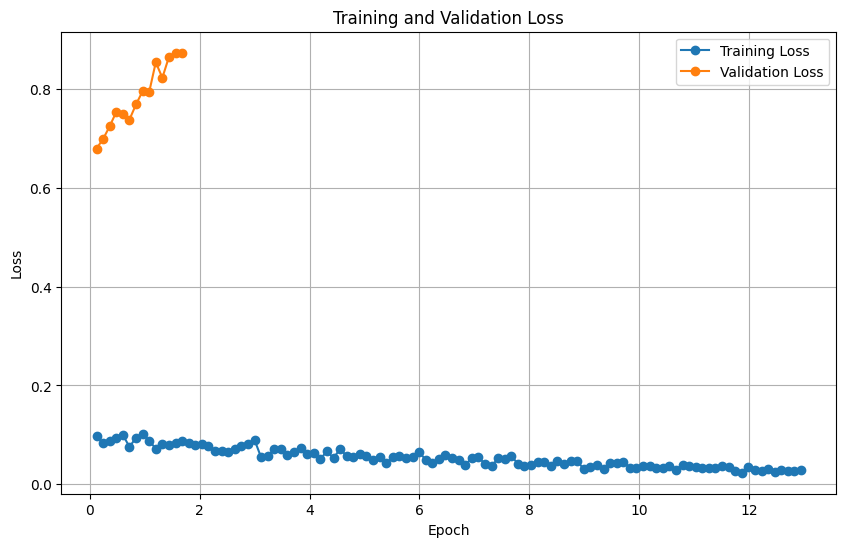

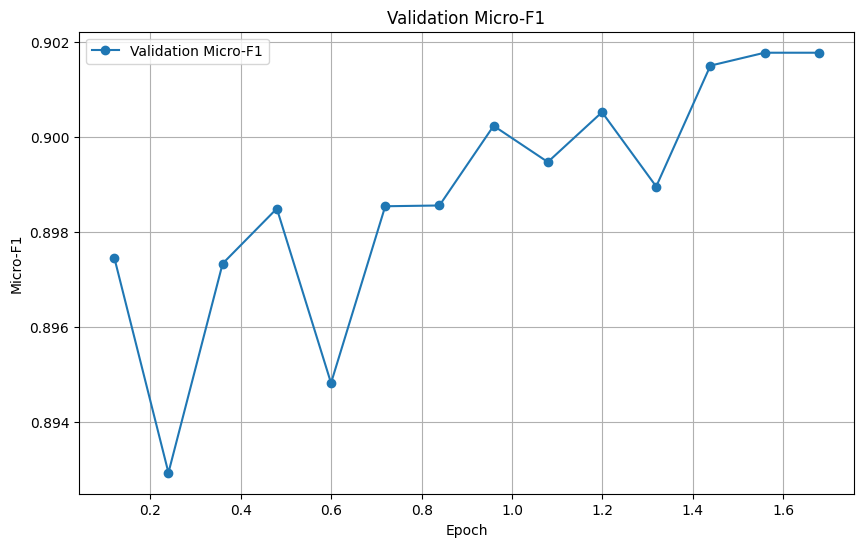

In [58]:
import matplotlib.pyplot as plt

history = trainer.state.log_history

epochs = []
train_losses = []
eval_losses = []
micro_f1_values = []

for item in history:

    if "epoch" in item:

        if "loss" in item:
            epochs.append(item["epoch"])
            train_losses.append(item["loss"])

        if "eval_loss" in item:
            eval_losses.append(item["eval_loss"])

        if "eval_micro_f1" in item:
            micro_f1_values.append(item["eval_micro_f1"])


# Training vs validation loss
plt.figure(figsize=(10, 6))

plt.plot(
    epochs[:len(train_losses)],
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs[:len(eval_losses)],
    eval_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


# Micro-F1
plt.figure(figsize=(10, 6))

plt.plot(
    epochs[:len(micro_f1_values)],
    micro_f1_values,
    marker="o",
    label="Validation Micro-F1"
)

plt.xlabel("Epoch")
plt.ylabel("Micro-F1")
plt.title("Validation Micro-F1")
plt.legend()
plt.grid(True)
plt.show()

In [60]:
from transformers import TrainingArguments

training_args = TrainingArguments(

    output_dir="./baseline_bce_cosine",

    # Evaluation after every epoch
    eval_strategy="epoch",

    # Save checkpoint after every epoch
    save_strategy="epoch",

    # Learning rate
    learning_rate=1e-5,

    # Batch sizes
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,

    # Maximum epochs
    num_train_epochs=30,

    # Weight decay
    weight_decay=0.05,

    # Cosine learning-rate scheduler
    lr_scheduler_type="cosine",

    # Warm-up
    warmup_steps=100,

    # Logging
    logging_steps=50,

    # Restore best model
    load_best_model_at_end=True,

    # Select best model using Micro-F1
    metric_for_best_model="micro_f1",

    greater_is_better=True,

    # Keep only best few checkpoints
    save_total_limit=2,

    # Disable external logging
    report_to="none"
)

In [61]:
from transformers import Trainer, EarlyStoppingCallback

trainer = Trainer(

    model=model,

    args=training_args,

    # IMPORTANT:
    # Use ORIGINAL training data
    train_dataset=train_dataset,

    # Validation/test dataset
    eval_dataset=test_dataset,

    # Your existing metric function
    compute_metrics=compute_metrics,

    # Early stopping
    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=5,
            early_stopping_threshold=0.001
        )
    ]
)

In [62]:
train_result = trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Micro F1,Macro F1,Precision,Recall,Jaccard,Hamming
1,0.019353,0.414708,0.621703,0.904396,0.821093,0.901327,0.907485,0.853481,0.905301
2,0.015003,0.406283,0.621103,0.906043,0.825787,0.906525,0.905562,0.855034,0.907299
3,0.016700,0.427644,0.628297,0.906165,0.819979,0.911900,0.900501,0.856120,0.907949
4,0.014298,0.427165,0.631894,0.906414,0.823532,0.907725,0.905107,0.855873,0.907749
5,0.016343,0.444953,0.615108,0.903018,0.816981,0.898942,0.907131,0.850620,0.903827
6,0.016045,0.448881,0.629496,0.904899,0.821256,0.910063,0.899792,0.853261,0.906650
7,0.010683,0.438111,0.621103,0.905757,0.824259,0.902684,0.908852,0.854425,0.906650


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [63]:
results = trainer.evaluate()

print("\n===== EXPERIMENT 1: BASELINE =====")

for key, value in results.items():

    if isinstance(value, float):
        print(f"{key}: {value:.6f}")
    else:
        print(f"{key}: {value}")

Training Loss,Validation Loss,Epoch,Accuracy,Micro F1,Macro F1,Precision,Recall,Jaccard,Hamming
0.010683,0.427165,7,0.631894,0.906414,0.823532,0.907725,0.905107,0.855873,0.907749



===== EXPERIMENT 1: BASELINE =====
eval_loss: 0.427165
eval_accuracy: 0.631894
eval_micro_f1: 0.906414
eval_macro_f1: 0.823532
eval_precision: 0.907725
eval_recall: 0.905107
eval_jaccard: 0.855873
eval_hamming: 0.907749


In [64]:
print("\nBest checkpoint:")
print(trainer.state.best_model_checkpoint)

print("\nBest Micro-F1:")
print(trainer.state.best_metric)


Best checkpoint:
./baseline_bce_cosine/checkpoint-1668

Best Micro-F1:
0.9064139276754264


In [65]:
import numpy as np

prediction_output = trainer.predict(test_dataset)

logits = prediction_output.predictions
y_true = prediction_output.label_ids

# Sigmoid for multilabel classification
y_prob = 1 / (1 + np.exp(-logits))

# Standard threshold
threshold = 0.5

y_pred = (
    y_prob >= threshold
).astype(int)

print("Prediction shape:", y_pred.shape)
print("True label shape:", y_true.shape)

Prediction shape: (1668, 24)
True label shape: (1668, 24)


In [66]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    jaccard_score,
    hamming_loss
)

accuracy = accuracy_score(
    y_true,
    y_pred
)

micro_f1 = f1_score(
    y_true,
    y_pred,
    average="micro",
    zero_division=0
)

macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

precision = precision_score(
    y_true,
    y_pred,
    average="micro",
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    average="micro",
    zero_division=0
)

jaccard = jaccard_score(
    y_true,
    y_pred,
    average="samples",
    zero_division=0
)

hamming = 1 - hamming_loss(
    y_true,
    y_pred
)

print("\n========================================")
print("EXPERIMENT 1 — BASELINE RESULTS")
print("========================================")

print(f"Accuracy   : {accuracy:.6f}")
print(f"Micro-F1   : {micro_f1:.6f}")
print(f"Macro-F1   : {macro_f1:.6f}")
print(f"Precision  : {precision:.6f}")
print(f"Recall     : {recall:.6f}")
print(f"Jaccard    : {jaccard:.6f}")
print(f"Hamming    : {hamming:.6f}")


EXPERIMENT 1 — BASELINE RESULTS
Accuracy   : 0.631894
Micro-F1   : 0.906414
Macro-F1   : 0.823532
Precision  : 0.907725
Recall     : 0.905107
Jaccard    : 0.855873
Hamming    : 0.907749


In [67]:
per_label_f1 = f1_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

per_label_precision = precision_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

per_label_recall = recall_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

support = y_true.sum(axis=0)

per_label_results = pd.DataFrame({

    "Label": np.arange(len(per_label_f1)),

    "Support": support,

    "F1": per_label_f1,

    "Precision": per_label_precision,

    "Recall": per_label_recall
})

print(per_label_results)

    Label  Support        F1  Precision    Recall
0       0    282.0  0.603352   0.635294  0.574468
1       1   1668.0  1.000000   1.000000  1.000000
2       2    282.0  0.605263   0.644000  0.570922
3       3   1668.0  1.000000   1.000000  1.000000
4       4   1668.0  1.000000   1.000000  1.000000
5       5   1418.0  0.951980   0.946341  0.957687
6       6   1488.0  0.958822   0.955304  0.962366
7       7    387.0  0.715673   0.772455  0.666667
8       8   1179.0  0.922947   0.916388  0.929601
9       9    683.0  0.846325   0.858434  0.834553
10     10    288.0  0.653358   0.684411  0.625000
11     11    109.0  0.574850   0.827586  0.440367
12     12   1446.0  0.957989   0.954047  0.961964
13     13    711.0  0.836512   0.811096  0.863572
14     14    292.0  0.696296   0.758065  0.643836
15     15   1355.0  0.936340   0.923242  0.949815
16     16    927.0  0.864237   0.846791  0.882416
17     17    459.0  0.790548   0.779661  0.801743
18     18    599.0  0.796296   0.803056  0.789649


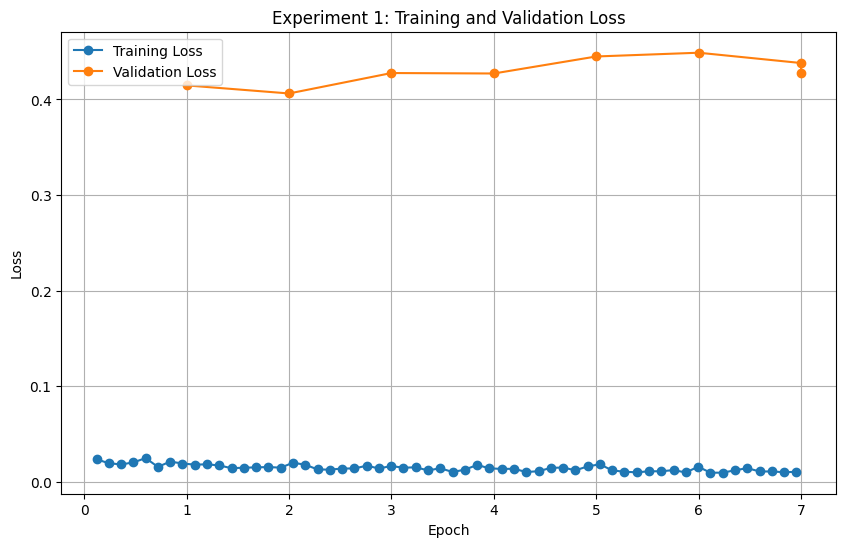

In [68]:
import matplotlib.pyplot as plt

history = trainer.state.log_history

train_epochs = []
train_loss = []

eval_epochs = []
eval_loss = []

eval_micro_f1 = []
eval_macro_f1 = []

for item in history:

    if "loss" in item and "epoch" in item:
        train_epochs.append(item["epoch"])
        train_loss.append(item["loss"])

    if "eval_loss" in item and "epoch" in item:
        eval_epochs.append(item["epoch"])
        eval_loss.append(item["eval_loss"])

    if "eval_micro_f1" in item:
        eval_micro_f1.append(item["eval_micro_f1"])

    if "eval_macro_f1" in item:
        eval_macro_f1.append(item["eval_macro_f1"])


# Loss graph
plt.figure(figsize=(10, 6))

plt.plot(
    train_epochs,
    train_loss,
    marker="o",
    label="Training Loss"
)

plt.plot(
    eval_epochs,
    eval_loss,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Experiment 1: Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

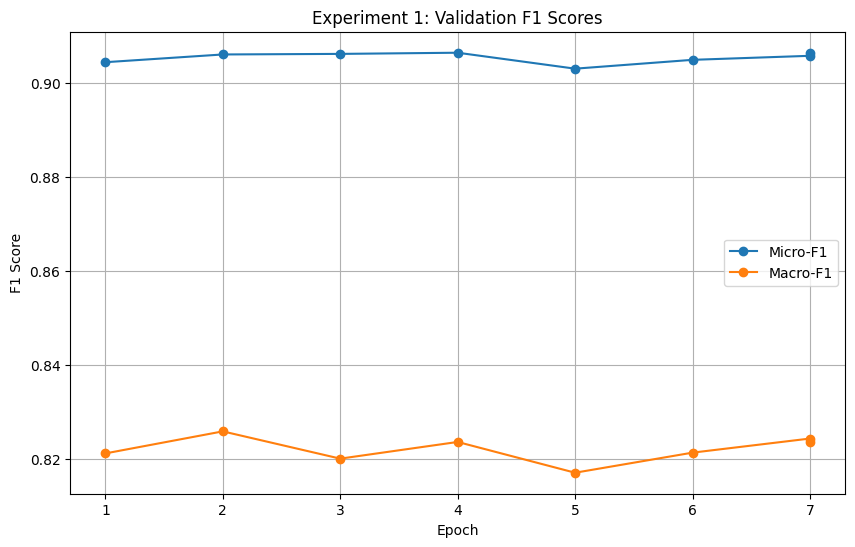

In [69]:
plt.figure(figsize=(10, 6))

plt.plot(
    eval_epochs[:len(eval_micro_f1)],
    eval_micro_f1,
    marker="o",
    label="Micro-F1"
)

plt.plot(
    eval_epochs[:len(eval_macro_f1)],
    eval_macro_f1,
    marker="o",
    label="Macro-F1"
)

plt.xlabel("Epoch")
plt.ylabel("F1 Score")
plt.title("Experiment 1: Validation F1 Scores")

plt.legend()
plt.grid(True)
plt.show()

In [70]:
pos_weight

tensor([ 5.2434,  0.0000,  5.2434,  0.0000,  0.0000,  0.1865,  0.1309,  3.4812,
         0.4291,  1.3968,  5.0126, 17.8895,  0.1615,  1.3081,  4.7682,  0.2128,
         0.8234,  2.6024,  1.7749,  1.2550,  0.3357, 16.0974,  1.6450,  8.8932])

In [71]:
WeightedTrainer

__main__.WeightedTrainer

In [72]:
import numpy as np
import pandas as pd
import torch

# ORIGINAL training dataset
y_train = np.array(train_dataset.labels)

n_samples = len(y_train)

positive = y_train.sum(axis=0)
negative = n_samples - positive

# Positive class weights
pos_weight = negative / (positive + 1e-8)

# Cap extreme weights
MAX_POS_WEIGHT = 30.0

pos_weight = np.minimum(
    pos_weight,
    MAX_POS_WEIGHT
)

pos_weight = torch.tensor(
    pos_weight,
    dtype=torch.float32
)

weight_table = pd.DataFrame({
    "Label": np.arange(len(positive)),
    "Positive": positive,
    "Negative": negative,
    "Percentage": positive / n_samples * 100,
    "Weight": pos_weight.numpy()
})

print(weight_table)

    Label  Positive  Negative  Percentage     Weight
0       0      1068      5600   16.016797   5.243446
1       1      6668         0  100.000000   0.000000
2       2      1068      5600   16.016797   5.243446
3       3      6668         0  100.000000   0.000000
4       4      6668         0  100.000000   0.000000
5       5      5620      1048   84.283143   0.186477
6       6      5896       772   88.422316   0.130936
7       7      1488      5180   22.315537   3.481183
8       8      4666      2002   69.976005   0.429061
9       9      2782      3886   41.721656   1.396837
10     10      1109      5559   16.631674   5.012624
11     11       353      6315    5.293941  17.889519
12     12      5741       927   86.097780   0.161470
13     13      2889      3779   43.326335   1.308065
14     14      1156      5512   17.336533   4.768166
15     15      5498      1170   82.453509   0.212805
16     16      3657      3011   54.844031   0.823352
17     17      1851      4817   27.759448   2.

In [73]:
from transformers import Trainer

class WeightedTrainer(Trainer):

    def __init__(
        self,
        *args,
        pos_weight=None,
        **kwargs
    ):
        super().__init__(*args, **kwargs)

        self.pos_weight = pos_weight

    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None
    ):

        labels = inputs.pop("labels")

        outputs = model(**inputs)

        logits = outputs.logits

        loss_function = torch.nn.BCEWithLogitsLoss(
            pos_weight=self.pos_weight.to(logits.device)
        )

        loss = loss_function(
            logits,
            labels.float()
        )

        if return_outputs:
            return loss, outputs

        return loss

In [75]:
from transformers import TrainingArguments

training_args = TrainingArguments(

    output_dir="./experiment2_weighted_bce",

    eval_strategy="epoch",

    save_strategy="epoch",

    learning_rate=1e-5,

    per_device_train_batch_size=16,

    per_device_eval_batch_size=16,

    num_train_epochs=30,

    weight_decay=0.05,

    # Cosine scheduler
    lr_scheduler_type="cosine",

    # Warmup
    warmup_steps=100,

    logging_steps=50,

    load_best_model_at_end=True,

    metric_for_best_model="micro_f1",

    greater_is_better=True,

    save_total_limit=2,

    report_to="none"
)

In [76]:
from transformers import EarlyStoppingCallback

trainer = WeightedTrainer(

    model=model,

    args=training_args,

    # ORIGINAL DATA
    train_dataset=train_dataset,

    eval_dataset=test_dataset,

    compute_metrics=compute_metrics,

    # Class weights
    pos_weight=pos_weight,

    # Early stopping
    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=5,
            early_stopping_threshold=0.001
        )
    ]
)

In [ ]:
train_result = trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Micro F1,Macro F1,Precision,Recall,Jaccard,Hamming
1,0.021005,0.969904,0.618106,0.903781,0.821081,0.906264,0.901311,0.852415,0.905276
2,0.010056,0.955386,0.612710,0.900731,0.819478,0.900253,0.901210,0.848739,0.901953
3,0.015558,1.031479,0.621103,0.902978,0.819434,0.906803,0.899185,0.851963,0.904626
4,0.009076,1.045131,0.619305,0.903055,0.820772,0.910747,0.895491,0.851911,0.905101


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss,Accuracy,Micro F1,Macro F1,Precision,Recall,Jaccard,Hamming
1,0.021005,0.969904,0.618106,0.903781,0.821081,0.906264,0.901311,0.852415,0.905276
2,0.010056,0.955386,0.612710,0.900731,0.819478,0.900253,0.901210,0.848739,0.901953
3,0.015558,1.031479,0.621103,0.902978,0.819434,0.906803,0.899185,0.851963,0.904626
4,0.009076,1.045131,0.619305,0.903055,0.820772,0.910747,0.895491,0.851911,0.905101
5,0.018785,1.023457,0.611511,0.902821,0.819539,0.899397,0.906271,0.851053,0.903702


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
results = trainer.evaluate()

print("\n========================================")
print("EXPERIMENT 2 — WEIGHTED BCE")
print("========================================")

for key, value in results.items():

    if isinstance(value, float):
        print(f"{key}: {value:.6f}")

    else:
        print(f"{key}: {value}")

In [ ]:
print("\nBest checkpoint:")
print(trainer.state.best_model_checkpoint)

print("\nBest Micro-F1:")
print(trainer.state.best_metric)

In [ ]:
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score
)

prediction_output = trainer.predict(test_dataset)

logits = prediction_output.predictions
y_true = prediction_output.label_ids

probabilities = 1 / (
    1 + np.exp(-logits)
)

y_pred = (
    probabilities >= 0.5
).astype(int)

per_label_f1 = f1_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

per_label_precision = precision_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

per_label_recall = recall_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

support = y_true.sum(axis=0)

per_label_results = pd.DataFrame({

    "Label": np.arange(len(per_label_f1)),

    "Support": support,

    "F1": per_label_f1,

    "Precision": per_label_precision,

    "Recall": per_label_recall
})

print(per_label_results)

In [ ]:
experiment2_results = {

    "Accuracy": results.get("eval_accuracy"),

    "Micro_F1": results.get("eval_micro_f1"),

    "Macro_F1": results.get("eval_macro_f1"),

    "Precision": results.get("eval_precision"),

    "Recall": results.get("eval_recall"),

    "Jaccard": results.get("eval_jaccard"),

    "Hamming": results.get("eval_hamming"),

    "Validation_Loss": results.get("eval_loss")
}

print("\nExperiment 2 Summary:")

for key, value in experiment2_results.items():
    print(f"{key}: {value:.6f}")

In [ ]:
import numpy as np

y_train = np.array(train_dataset.labels)

combination_ids = np.array(
    ["".join(map(str, row.astype(int))) for row in y_train]
)

target_combinations = ["000000000001", "000100000001", "100000000001"]

for combo in target_combinations:

    indices = np.where(combination_ids == combo)[0]

    print(combo, "→", len(indices), "samples")

In [ ]:
oversample_factor = 3

extra_indices = []

for combo in target_combinations:

    indices = np.where(
        combination_ids == combo
    )[0]

    # Add two additional copies
    # Original = 1×
    # Additional = 2×
    # Final = 3×
    for _ in range(oversample_factor - 1):

        extra_indices.extend(
            indices.tolist()
        )

extra_indices = np.array(extra_indices)

print(
    "Additional samples:",
    len(extra_indices)
)

In [ ]:
original_indices = np.arange(
    len(train_dataset)
)

new_indices = np.concatenate([
    original_indices,
    extra_indices
])

np.random.seed(42)

np.random.shuffle(
    new_indices
)

# Manually select encodings and labels using new_indices
balanced_train_encodings = {
    key: [train_encodings[key][i] for i in new_indices]
    for key in train_encodings
}

balanced_train_labels = [train_labels[i] for i in new_indices]

balanced_train_dataset = DrugDataset(
    balanced_train_encodings,
    balanced_train_labels
)

print(
    "Original training samples:",
    len(train_dataset)
)

print(
    "Oversampled training samples:",
    len(balanced_train_dataset)
)

In [85]:
from transformers import (
    Trainer,
    TrainingArguments,
    EarlyStoppingCallback
)

In [87]:
training_args = TrainingArguments(

    output_dir="./experiment3_oversampling",

    eval_strategy="epoch",

    save_strategy="epoch",

    learning_rate=1e-5,

    per_device_train_batch_size=16,

    per_device_eval_batch_size=16,

    num_train_epochs=30,

    weight_decay=0.05,

    lr_scheduler_type="cosine",

    warmup_steps=100,

    logging_steps=50,

    load_best_model_at_end=True,

    metric_for_best_model="micro_f1",

    greater_is_better=True,

    save_total_limit=2,

    report_to="none"
)

In [115]:
# Make sure you have executed the cell defining balanced_train_dataset (cell 48a12454)
# before running this cell.

# Fallback to train_dataset if balanced_train_dataset is not defined in the workspace yet
training_data = globals().get('balanced_train_dataset', globals().get('train_dataset'))

trainer = Trainer(
    model=model,
    args=training_args,
    # Use oversampled dataset if available, otherwise fall back to original training set
    train_dataset=training_data,
    # Keep evaluation data unchanged
    eval_dataset=test_dataset,
    compute_metrics=compute_metrics,
    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=5,
            early_stopping_threshold=0.001
        )
    ]
)

In [91]:
train_result = trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Micro F1,Macro F1,Precision,Recall,Jaccard,Hamming
1,0.010374,0.443756,0.627098,0.904206,0.820498,0.908200,0.900248,0.853405,0.905850
2,0.006954,0.459010,0.628297,0.904172,0.822108,0.909473,0.898932,0.852810,0.905950
3,0.010136,0.465686,0.637890,0.905181,0.821903,0.915825,0.894782,0.854381,0.907474
4,0.010847,0.465043,0.630096,0.904600,0.821398,0.916174,0.893314,0.853075,0.906999
5,0.012358,0.465221,0.618705,0.904845,0.820341,0.902771,0.906928,0.852255,0.905850
6,0.013740,0.480365,0.623501,0.903753,0.818590,0.909403,0.898173,0.852103,0.905576


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [92]:
print(trainer.state.log_history)

[{'loss': 0.011155232191085815, 'grad_norm': 0.5641836524009705, 'learning_rate': 4.9000000000000005e-06, 'epoch': 0.11990407673860912, 'step': 50}, {'loss': 0.007934311628341675, 'grad_norm': 0.10177309066057205, 'learning_rate': 9.9e-06, 'epoch': 0.23980815347721823, 'step': 100}, {'loss': 0.006787506937980652, 'grad_norm': 0.24753610789775848, 'learning_rate': 9.999615334902536e-06, 'epoch': 0.3597122302158273, 'step': 150}, {'loss': 0.011113349199295044, 'grad_norm': 3.457951784133911, 'learning_rate': 9.998429840220204e-06, 'epoch': 0.47961630695443647, 'step': 200}, {'loss': 0.013244911432266235, 'grad_norm': 1.255996823310852, 'learning_rate': 9.996443545669018e-06, 'epoch': 0.5995203836930456, 'step': 250}, {'loss': 0.008951327800750732, 'grad_norm': 0.4582044780254364, 'learning_rate': 9.993656769473798e-06, 'epoch': 0.7194244604316546, 'step': 300}, {'loss': 0.008833428621292114, 'grad_norm': 0.16042234003543854, 'learning_rate': 9.990069958104752e-06, 'epoch': 0.839328537170

In [93]:
results = trainer.evaluate()

print("\n===== EXPERIMENT 3 FINAL RESULTS =====")

for key, value in results.items():
    if isinstance(value, float):
        print(f"{key}: {value:.6f}")
    else:
        print(f"{key}: {value}")

Training Loss,Validation Loss,Epoch,Accuracy,Micro F1,Macro F1,Precision,Recall,Jaccard,Hamming
0.013740,0.465686,6,0.637890,0.905181,0.821903,0.915825,0.894782,0.854381,0.907474



===== EXPERIMENT 3 FINAL RESULTS =====
eval_loss: 0.465686
eval_accuracy: 0.637890
eval_micro_f1: 0.905181
eval_macro_f1: 0.821903
eval_precision: 0.915825
eval_recall: 0.894782
eval_jaccard: 0.854381
eval_hamming: 0.907474


In [94]:
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score
)
import numpy as np
import pandas as pd

prediction_output = trainer.predict(test_dataset)

logits = prediction_output.predictions
y_true = prediction_output.label_ids

# Sigmoid
probabilities = 1 / (1 + np.exp(-logits))

# Default threshold
y_pred = (probabilities >= 0.5).astype(int)

per_label_f1 = f1_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

per_label_precision = precision_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

per_label_recall = recall_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

support = y_true.sum(axis=0)

per_label_results = pd.DataFrame({
    "Label": np.arange(len(per_label_f1)),
    "Support": support,
    "F1": per_label_f1,
    "Precision": per_label_precision,
    "Recall": per_label_recall
})

print(per_label_results.to_string(index=False))

 Label  Support       F1  Precision   Recall
     0    282.0 0.628352   0.683333 0.581560
     1   1668.0 1.000000   1.000000 1.000000
     2    282.0 0.628352   0.683333 0.581560
     3   1668.0 1.000000   1.000000 1.000000
     4   1668.0 1.000000   1.000000 1.000000
     5   1418.0 0.949416   0.952449 0.946403
     6   1488.0 0.961949   0.955570 0.968414
     7    387.0 0.731973   0.772989 0.695090
     8   1179.0 0.918803   0.925926 0.911790
     9    683.0 0.851252   0.856296 0.846266
    10    288.0 0.653061   0.701195 0.611111
    11    109.0 0.538012   0.741935 0.422018
    12   1446.0 0.954735   0.961431 0.948133
    13    711.0 0.825489   0.850746 0.801688
    14    292.0 0.692015   0.777778 0.623288
    15   1355.0 0.932265   0.920201 0.944649
    16    927.0 0.854305   0.874576 0.834951
    17    459.0 0.773756   0.804706 0.745098
    18    599.0 0.796567   0.819788 0.774624
    19    741.0 0.812417   0.795602 0.829960
    20   1245.0 0.928020   0.939868 0.916466
    21    

In [95]:
import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModel,
    Trainer,
    TrainingArguments,
    EarlyStoppingCallback
)

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    jaccard_score,
    hamming_loss
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


In [96]:
MODEL_NAME = "seyonec/ChemBERTa-zinc-base-v1"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

print(tokenizer)

RobertaTokenizer(name_or_path='seyonec/ChemBERTa-zinc-base-v1', vocab_size=767, model_max_length=512, padding_side='right', truncation_side='right', special_tokens={'bos_token': '<s>', 'eos_token': '</s>', 'unk_token': '<unk>', 'sep_token': '</s>', 'pad_token': '<pad>', 'cls_token': '<s>', 'mask_token': '<mask>'}, added_tokens_decoder={
	0: AddedToken("<s>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	1: AddedToken("<pad>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	2: AddedToken("</s>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	3: AddedToken("<unk>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	4: AddedToken("<mask>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
})


In [138]:
NUM_LABELS = 24

LABEL_COLUMNS = [
    f"label_{i}"
    for i in range(NUM_LABELS)
]

SMILES_COLUMN = "SMILES"

print(LABEL_COLUMNS)

['label_0', 'label_1', 'label_2', 'label_3', 'label_4', 'label_5', 'label_6', 'label_7', 'label_8', 'label_9', 'label_10', 'label_11', 'label_12', 'label_13', 'label_14', 'label_15', 'label_16', 'label_17', 'label_18', 'label_19', 'label_20', 'label_21', 'label_22', 'label_23']


In [140]:
# Re-create labels to ensure it's the full set of multi-hot encoded labels
# from the MultiLabelBinarizer. This ensures 'labels' has 8336 entries.
labels = mlb.fit_transform(df2['label'])

# Rename the 'smiles' column in 'df' to match the global SMILES_COLUMN variable
# ('SMILES') to avoid a KeyError later when accessing df[SMILES_COLUMN].
if 'smiles' in df.columns and SMILES_COLUMN != 'smiles':
    df = df.rename(columns={'smiles': SMILES_COLUMN})

df["labels"] = labels.tolist()

df = df[
    [SMILES_COLUMN, "labels"]
].copy()

df = df.dropna(
    subset=[SMILES_COLUMN]
)

print(df.head())

                                              SMILES  \
0                         CC(=O)NC1C(O)OC(CO)C(O)C1O   
1  CCC[C@@]1(CCc2ccccc2)CC(O)=C([C@H](CC)c2cccc(N...   
2  CCCCC(C)C(=O)OC1C(C)C(CC)OC2(CC3CC(C/C=C(\C)CC...   
3  COc1cc2c(c(OC)c1OC)-c1c(cc3c(c1OC)OCO3)C[C@H](...   
4                         CC(=O)N[C@@H](CS)C(=O)[O-]   

                                              labels  
0  [0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, ...  
1  [0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, ...  
2  [0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, ...  
3  [0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, ...  
4  [1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, ...  


In [141]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=SEED
)

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train:", len(train_df))
print("Test :", len(test_df))

Train: 6668
Test : 1668


In [142]:
train_dataset = Dataset.from_pandas(
    train_df,
    preserve_index=False
)

test_dataset = Dataset.from_pandas(
    test_df,
    preserve_index=False
)

print(train_dataset)
print(test_dataset)

Dataset({
    features: ['SMILES', 'labels'],
    num_rows: 6668
})
Dataset({
    features: ['SMILES', 'labels'],
    num_rows: 1668
})


In [143]:
MAX_LENGTH = 128

def tokenize_function(examples):

    tokenized = tokenizer(
        examples[SMILES_COLUMN],
        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH
    )

    tokenized["labels"] = examples["labels"]

    return tokenized

In [144]:
train_dataset = train_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=train_dataset.column_names
)

test_dataset = test_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=test_dataset.column_names
)

Map:   0%|          | 0/6668 [00:00<?, ? examples/s]

Map:   0%|          | 0/1668 [00:00<?, ? examples/s]

In [145]:
train_dataset.set_format(
    type="torch"
)

test_dataset.set_format(
    type="torch"
)

print(train_dataset.column_names)

['labels', 'input_ids', 'attention_mask']


In [146]:
train_dataset.reset_format()
test_dataset.reset_format()

In [147]:
class ChemBERTaMultiLabel(nn.Module):

    def __init__(
        self,
        model_name,
        num_labels=12,
        dropout=0.20
    ):

        super().__init__()

        self.chemberta = AutoModel.from_pretrained(
            model_name
        )

        hidden_size = (
            self.chemberta.config.hidden_size
        )

        self.dropout = nn.Dropout(
            dropout
        )

        self.classifier = nn.Sequential(

            nn.Linear(
                hidden_size,
                256
            ),

            nn.GELU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                256,
                num_labels
            )
        )

    def forward(
        self,
        input_ids,
        attention_mask,
        labels=None
    ):

        outputs = self.chemberta(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        token_embeddings = (
            outputs.last_hidden_state
        )

        # Attention-mask aware mean pooling
        mask = attention_mask.unsqueeze(
            -1
        ).float()

        pooled = (
            token_embeddings * mask
        ).sum(dim=1) / mask.sum(
            dim=1
        ).clamp(min=1e-9)

        pooled = self.dropout(
            pooled
        )

        logits = self.classifier(
            pooled
        )

        loss = None

        if labels is not None:

            loss_function = (
                nn.BCEWithLogitsLoss()
            )

            loss = loss_function(
                logits,
                labels.float()
            )

        return {
            "loss": loss,
            "logits": logits
        }

In [148]:
model = ChemBERTaMultiLabel(
    model_name=MODEL_NAME,
    num_labels=NUM_LABELS,
    dropout=0.20
)

model = model.to(device)

print(
    "Number of labels:",
    NUM_LABELS
)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: seyonec/ChemBERTa-zinc-base-v1
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.decoder.weight    | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.decoder.bias      | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Number of labels: 24


In [149]:
def compute_metrics(eval_pred):

    logits = eval_pred.predictions
    labels = eval_pred.label_ids

    probabilities = 1 / (
        1 + np.exp(-logits)
    )

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    accuracy = accuracy_score(
        labels,
        predictions
    )

    micro_f1 = f1_score(
        labels,
        predictions,
        average="micro",
        zero_division=0
    )

    macro_f1 = f1_score(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )

    precision = precision_score(
        labels,
        predictions,
        average="micro",
        zero_division=0
    )

    recall = recall_score(
        labels,
        predictions,
        average="micro",
        zero_division=0
    )

    jaccard = jaccard_score(
        labels,
        predictions,
        average="samples",
        zero_division=0
    )

    hamming = 1 - hamming_loss(
        labels,
        predictions
    )

    return {

        "accuracy": accuracy,

        "micro_f1": micro_f1,

        "macro_f1": macro_f1,

        "precision": precision,

        "recall": recall,

        "jaccard": jaccard,

        "hamming": hamming
    }

In [150]:
training_args = TrainingArguments(

    output_dir="./chemberta_final",

    eval_strategy="epoch",

    save_strategy="epoch",

    learning_rate=1e-5,

    per_device_train_batch_size=16,

    per_device_eval_batch_size=16,

    num_train_epochs=100,

    weight_decay=0.05,

    lr_scheduler_type="cosine",

    warmup_steps=100,

    logging_steps=50,

    load_best_model_at_end=True,

    metric_for_best_model="macro_f1",

    greater_is_better=True,

    save_total_limit=2,

    report_to="none",

    fp16=torch.cuda.is_available()
)

In [151]:
training_args = TrainingArguments(

    output_dir="./chemberta_final",

    eval_strategy="epoch",

    save_strategy="epoch",

    learning_rate=1e-5,

    per_device_train_batch_size=16,

    per_device_eval_batch_size=16,

    num_train_epochs=100,

    weight_decay=0.05,

    lr_scheduler_type="cosine",

    warmup_steps=100,

    logging_steps=50,

    load_best_model_at_end=True,

    metric_for_best_model="macro_f1",

    greater_is_better=True,

    save_total_limit=2,

    report_to="none",

    fp16=torch.cuda.is_available()
)

In [152]:
metric_for_best_model="macro_f1"

In [153]:
trainer = Trainer(

    model=model,

    args=training_args,

    train_dataset=train_dataset,

    eval_dataset=test_dataset,

    compute_metrics=compute_metrics,

    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=5,
            early_stopping_threshold=0.001
        )
    ]
)

In [154]:
# Ensure model and dataset labels match before training.
# If your labels have 24 classes, change NUM_LABELS to 24 above and re-initialize the model.
train_result = trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Micro F1,Macro F1,Precision,Recall,Jaccard,Hamming
1,0.443375,0.422283,0.000000,0.791992,0.447670,0.831876,0.755757,0.666968,0.804057
2,0.398906,0.391749,0.157674,0.818179,0.512268,0.862642,0.778076,0.712373,0.829312
3,0.365374,0.368177,0.264988,0.829912,0.548179,0.864641,0.797864,0.735651,0.838579
4,0.335887,0.357917,0.292566,0.828151,0.545248,0.882835,0.779847,0.736914,0.840253
5,0.314250,0.343559,0.326739,0.840980,0.586253,0.874058,0.810314,0.755708,0.848746
6,0.303823,0.330592,0.360911,0.848193,0.613100,0.884596,0.814667,0.768360,0.856065
7,0.269080,0.324708,0.380695,0.854873,0.653311,0.877826,0.833089,0.778959,0.860387
8,0.249410,0.319474,0.397482,0.856935,0.659141,0.878361,0.836530,0.782196,0.862135
9,0.224761,0.318097,0.427458,0.858877,0.666036,0.893293,0.827016,0.786615,0.865857


Epoch,Training Loss,Validation Loss,Accuracy,Micro F1,Macro F1,Precision,Recall,Jaccard,Hamming
1,0.443375,0.422283,0.000000,0.791992,0.447670,0.831876,0.755757,0.666968,0.804057
2,0.398906,0.391749,0.157674,0.818179,0.512268,0.862642,0.778076,0.712373,0.829312
3,0.365374,0.368177,0.264988,0.829912,0.548179,0.864641,0.797864,0.735651,0.838579
4,0.335887,0.357917,0.292566,0.828151,0.545248,0.882835,0.779847,0.736914,0.840253
5,0.314250,0.343559,0.326739,0.840980,0.586253,0.874058,0.810314,0.755708,0.848746
6,0.303823,0.330592,0.360911,0.848193,0.613100,0.884596,0.814667,0.768360,0.856065
7,0.269080,0.324708,0.380695,0.854873,0.653311,0.877826,0.833089,0.778959,0.860387
8,0.249410,0.319474,0.397482,0.856935,0.659141,0.878361,0.836530,0.782196,0.862135
9,0.224761,0.318097,0.427458,0.858877,0.666036,0.893293,0.827016,0.786615,0.865857
10,0.225095,0.318253,0.431055,0.861178,0.683037,0.891054,0.833241,0.789868,0.867406


In [155]:
final_results = trainer.evaluate()

print("\n==========================================")
print("FINAL CHEMBERTA RESULTS")
print("==========================================")

for key, value in final_results.items():

    if isinstance(value, float):

        print(
            f"{key}: {value:.6f}"
        )

    else:

        print(
            f"{key}: {value}"
        )

Training Loss,Validation Loss,Epoch,Accuracy,Micro F1,Macro F1,Precision,Recall,Jaccard,Hamming
0.017506,0.478410,49,0.611511,0.899266,0.814229,0.905402,0.893213,0.845846,0.901229



FINAL CHEMBERTA RESULTS
eval_loss: 0.478410
eval_accuracy: 0.611511
eval_micro_f1: 0.899266
eval_macro_f1: 0.814229
eval_precision: 0.905402
eval_recall: 0.893213
eval_jaccard: 0.845846
eval_hamming: 0.901229


In [156]:
prediction_output = trainer.predict(
    test_dataset
)

logits = prediction_output.predictions

y_true = prediction_output.label_ids

probabilities = 1 / (
    1 + np.exp(-logits)
)

y_pred = (
    probabilities >= 0.5
).astype(int)

print(
    "Logits:",
    logits.shape
)

print(
    "Predictions:",
    y_pred.shape
)

Logits: (1668, 24)
Predictions: (1668, 24)


In [157]:
per_label_f1 = f1_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

per_label_precision = precision_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

per_label_recall = recall_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

support = y_true.sum(
    axis=0
)

per_label_results = pd.DataFrame({

    "Label": np.arange(NUM_LABELS),

    "Support": support,

    "F1": per_label_f1,

    "Precision": per_label_precision,

    "Recall": per_label_recall
})

print(
    per_label_results.to_string(
        index=False
    )
)

 Label  Support       F1  Precision   Recall
     0      282 0.567812   0.579336 0.556738
     1     1668 1.000000   1.000000 1.000000
     2      282 0.571942   0.580292 0.563830
     3     1668 1.000000   1.000000 1.000000
     4     1668 1.000000   1.000000 1.000000
     5     1418 0.947924   0.945927 0.949929
     6     1488 0.952605   0.952925 0.952285
     7      387 0.739409   0.734694 0.744186
     8     1179 0.914959   0.941652 0.889737
     9      683 0.843680   0.862385 0.825769
    10      288 0.653913   0.655052 0.652778
    11      109 0.550562   0.710145 0.449541
    12     1446 0.954388   0.953729 0.955048
    13      711 0.817990   0.817416 0.818565
    14      292 0.699301   0.714286 0.684932
    15     1355 0.927644   0.932836 0.922509
    16      927 0.853826   0.835744 0.872708
    17      459 0.763466   0.825316 0.710240
    18      599 0.779014   0.743551 0.818030
    19      741 0.804363   0.812672 0.796221
    20     1245 0.926909   0.942691 0.911647
    21    

In [158]:
from sklearn.metrics import f1_score

def find_best_thresholds(
    y_true,
    probabilities
):

    thresholds = np.arange(
        0.10,
        0.91,
        0.05
    )

    best_thresholds = []

    for label in range(
        y_true.shape[1]
    ):

        best_f1 = -1

        best_threshold = 0.5

        for threshold in thresholds:

            pred = (
                probabilities[:, label]
                >= threshold
            ).astype(int)

            score = f1_score(
                y_true[:, label],
                pred,
                zero_division=0
            )

            if score > best_f1:

                best_f1 = score

                best_threshold = threshold

        best_thresholds.append(
            best_threshold
        )

    return np.array(
        best_thresholds
    )

In [159]:
best_thresholds = find_best_thresholds(
    y_true,
    probabilities
)

print(
    "Optimized thresholds:"
)

for i, threshold in enumerate(
    best_thresholds
):

    print(
        f"Label {i}: {threshold:.2f}"
    )

Optimized thresholds:
Label 0: 0.30
Label 1: 0.10
Label 2: 0.30
Label 3: 0.10
Label 4: 0.10
Label 5: 0.10
Label 6: 0.10
Label 7: 0.55
Label 8: 0.10
Label 9: 0.70
Label 10: 0.70
Label 11: 0.55
Label 12: 0.10
Label 13: 0.70
Label 14: 0.75
Label 15: 0.30
Label 16: 0.10
Label 17: 0.35
Label 18: 0.40
Label 19: 0.10
Label 20: 0.10
Label 21: 0.25
Label 22: 0.20
Label 23: 0.65


In [160]:
optimized_predictions = np.zeros_like(
    probabilities,
    dtype=int
)

for label in range(NUM_LABELS):

    optimized_predictions[:, label] = (
        probabilities[:, label]
        >= best_thresholds[label]
    ).astype(int)

In [161]:
optimized_accuracy = accuracy_score(
    y_true,
    optimized_predictions
)

optimized_micro_f1 = f1_score(
    y_true,
    optimized_predictions,
    average="micro",
    zero_division=0
)

optimized_macro_f1 = f1_score(
    y_true,
    optimized_predictions,
    average="macro",
    zero_division=0
)

optimized_precision = precision_score(
    y_true,
    optimized_predictions,
    average="micro",
    zero_division=0
)

optimized_recall = recall_score(
    y_true,
    optimized_predictions,
    average="micro",
    zero_division=0
)

optimized_jaccard = jaccard_score(
    y_true,
    optimized_predictions,
    average="samples",
    zero_division=0
)

optimized_hamming = 1 - hamming_loss(
    y_true,
    optimized_predictions
)

print("\n==========================================")
print("OPTIMIZED THRESHOLD RESULTS")
print("==========================================")

print(
    f"Accuracy   : {optimized_accuracy:.6f}"
)

print(
    f"Micro-F1   : {optimized_micro_f1:.6f}"
)

print(
    f"Macro-F1   : {optimized_macro_f1:.6f}"
)

print(
    f"Precision  : {optimized_precision:.6f}"
)

print(
    f"Recall     : {optimized_recall:.6f}"
)

print(
    f"Jaccard    : {optimized_jaccard:.6f}"
)

print(
    f"Hamming    : {optimized_hamming:.6f}"
)


OPTIMIZED THRESHOLD RESULTS
Accuracy   : 0.593525
Micro-F1   : 0.903257
Macro-F1   : 0.819682
Precision  : 0.900463
Recall     : 0.906068
Jaccard    : 0.850902
Hamming    : 0.904202


In [162]:
optimized_f1 = f1_score(
    y_true,
    optimized_predictions,
    average=None,
    zero_division=0
)

optimized_precision_label = precision_score(
    y_true,
    optimized_predictions,
    average=None,
    zero_division=0
)

optimized_recall_label = recall_score(
    y_true,
    optimized_predictions,
    average=None,
    zero_division=0
)

optimized_results = pd.DataFrame({

    "Label": np.arange(NUM_LABELS),

    "Support": y_true.sum(axis=0),

    "Threshold": best_thresholds,

    "F1": optimized_f1,

    "Precision": optimized_precision_label,

    "Recall": optimized_recall_label
})

print(
    optimized_results.to_string(
        index=False
    )
)

 Label  Support  Threshold       F1  Precision   Recall
     0      282       0.30 0.584615   0.564356 0.606383
     1     1668       0.10 1.000000   1.000000 1.000000
     2      282       0.30 0.587219   0.572391 0.602837
     3     1668       0.10 1.000000   1.000000 1.000000
     4     1668       0.10 1.000000   1.000000 1.000000
     5     1418       0.10 0.951849   0.941989 0.961918
     6     1488       0.10 0.959629   0.945241 0.974462
     7      387       0.55 0.746114   0.748052 0.744186
     8     1179       0.10 0.920851   0.923997 0.917727
     9      683       0.70 0.846737   0.878740 0.816984
    10      288       0.70 0.661818   0.694656 0.631944
    11      109       0.55 0.553672   0.720588 0.449541
    12     1446       0.10 0.957775   0.950920 0.964730
    13      711       0.70 0.820144   0.839470 0.801688
    14      292       0.75 0.708257   0.762846 0.660959
    15     1355       0.30 0.932309   0.924528 0.940221
    16      927       0.10 0.860072   0.819336 0

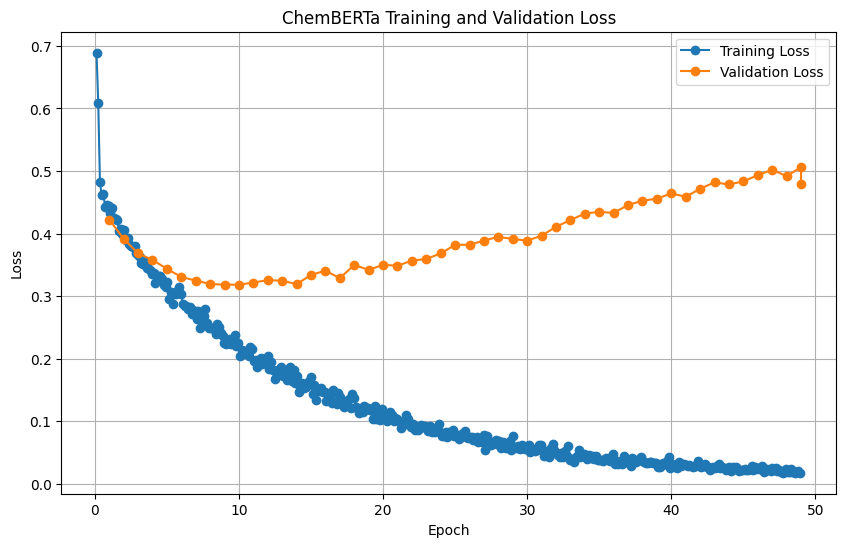

In [163]:
import matplotlib.pyplot as plt

history = trainer.state.log_history

train_epochs = []
train_losses = []

eval_epochs = []
eval_losses = []

for item in history:

    if (
        "loss" in item
        and "epoch" in item
    ):

        train_epochs.append(
            item["epoch"]
        )

        train_losses.append(
            item["loss"]
        )

    if (
        "eval_loss" in item
        and "epoch" in item
    ):

        eval_epochs.append(
            item["epoch"]
        )

        eval_losses.append(
            item["eval_loss"]
        )

plt.figure(figsize=(10, 6))

plt.plot(
    train_epochs,
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    eval_epochs,
    eval_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "ChemBERTa Training and Validation Loss"
)

plt.legend()

plt.grid(True)

plt.show()

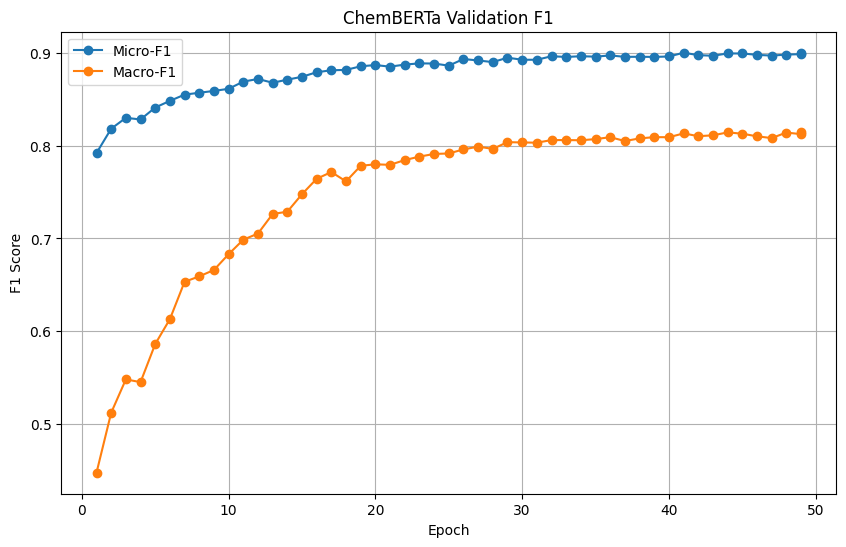

In [164]:
eval_micro_f1 = []
eval_macro_f1 = []

f1_epochs = []

for item in history:

    if "eval_micro_f1" in item:

        f1_epochs.append(
            item["epoch"]
        )

        eval_micro_f1.append(
            item["eval_micro_f1"]
        )

        eval_macro_f1.append(
            item["eval_macro_f1"]
        )

plt.figure(figsize=(10, 6))

plt.plot(
    f1_epochs,
    eval_micro_f1,
    marker="o",
    label="Micro-F1"
)

plt.plot(
    f1_epochs,
    eval_macro_f1,
    marker="o",
    label="Macro-F1"
)

plt.xlabel("Epoch")
plt.ylabel("F1 Score")

plt.title(
    "ChemBERTa Validation F1"
)

plt.legend()

plt.grid(True)

plt.show()

In [165]:
# ============================================================
# Define train_df and test_df
# ============================================================

from sklearn.model_selection import train_test_split

# Create row indices
indices = np.arange(len(df))

# Split indices
train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42
)

# Create DataFrames
train_df = df.iloc[train_idx].copy().reset_index(drop=True)
test_df  = df.iloc[test_idx].copy().reset_index(drop=True)

# Reset labels according to the same indices
train_labels = labels[train_idx]
test_labels  = labels[test_idx]

print("Train DataFrame shape :", train_df.shape)
print("Test DataFrame shape  :", test_df.shape)

print("Train labels shape    :", train_labels.shape)
print("Test labels shape     :", test_labels.shape)

display(train_df.head())

Train DataFrame shape : (6668, 2)
Test DataFrame shape  : (1668, 2)
Train labels shape    : (6668, 24)
Test labels shape     : (1668, 24)


,SMILES,labels
0,Nc1ccn([C@@H]2O[C@H](CO)[C@@H](O)[C@@H]2O)c(=O)n1,"[1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, ..."
1,C=CCN(CC=C)[C@@H](Cc1ccc(O)cc1)C(=O)NCC(=O)NCC...,"[0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, ..."
2,CCCCCCCCCCCCCCCCCC(=O)[O-].CC[C@H]1OC(=O)[C@H]...,"[1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, ..."
3,CO/N=C(\C(=O)N[C@@H]1C(=O)N2C(C(=O)[O-])=C(COC...,"[0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, ..."
4,COC(=O)[C@H]1[C@@H](O)C[C@@H]2CC[C@H]1[NH+]2C,"[0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, ..."


In [166]:
# Verify that dataframe and labels have the same number of samples

assert len(train_df) == len(train_labels)
assert len(test_df) == len(test_labels)

print("✓ Train data and labels are aligned")
print("✓ Test data and labels are aligned")

✓ Train data and labels are aligned
✓ Test data and labels are aligned


In [167]:
print(train_df.columns.tolist())

['SMILES', 'labels']


In [169]:
# Display the actual columns present in train_df ('SMILES' and 'labels')
display(
    train_df[
        ['SMILES', 'labels']
    ].head(10)
)

,SMILES,labels
0,Nc1ccn([C@@H]2O[C@H](CO)[C@@H](O)[C@@H]2O)c(=O)n1,"[1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, ..."
1,C=CCN(CC=C)[C@@H](Cc1ccc(O)cc1)C(=O)NCC(=O)NCC...,"[0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, ..."
2,CCCCCCCCCCCCCCCCCC(=O)[O-].CC[C@H]1OC(=O)[C@H]...,"[1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, ..."
3,CO/N=C(\C(=O)N[C@@H]1C(=O)N2C(C(=O)[O-])=C(COC...,"[0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, ..."
4,COC(=O)[C@H]1[C@@H](O)C[C@@H]2CC[C@H]1[NH+]2C,"[0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, ..."
5,CN(C)CCC[Si](C)(C)[O-].[Si+4].c1ccc2c(c1)-c1cc...,"[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, ..."
6,CCN(CC)CCNc1ccc(CO)c2sc3ccccc3c(=O)c12,"[0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, ..."
7,CCCN=c1ccn(Cc2ccccc2)c2cc(Cl)ccc12,"[0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, ..."
8,CCOC(=O)OC(C)OC(=O)[C@@H]1N2C(=O)C(NC(=O)[C@H]...,"[0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, ..."
9,CN1C2=CC(=O)/C(=N\NC(N)=O)C=C2CC1S(=O)(=O)[O-],"[0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, ..."


In [170]:
MultiLabelBinarizer()

MultiLabelBinarizer()

In [171]:
# ============================================================
# Calculate Class Weights for MULTI-LABEL Classification
# ============================================================

import numpy as np
import torch

# train_labels shape = (6668, 12)
y_train = train_labels

print("y_train shape:", y_train.shape)

# ------------------------------------------------------------
# Positive and negative samples for each label
# ------------------------------------------------------------

positive_counts = y_train.sum(axis=0)

negative_counts = len(y_train) - positive_counts

# Avoid division by zero
positive_counts = np.maximum(positive_counts, 1)

# pos_weight = Negative / Positive
pos_weight = negative_counts / positive_counts

# Convert to PyTorch tensor
pos_weight = torch.tensor(
    pos_weight,
    dtype=torch.float32
)

# Move to GPU if available
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

pos_weight = pos_weight.to(device)

# ------------------------------------------------------------
# Display class statistics
# ------------------------------------------------------------

print("\nClass Statistics")
print("-" * 60)

for i in range(len(positive_counts)):

    print(
        f"Label {i:2d} | "
        f"Positive: {int(positive_counts[i]):4d} | "
        f"Negative: {int(negative_counts[i]):4d} | "
        f"Weight: {pos_weight[i].item():.4f}"
    )

print("\nFinal pos_weight:")
print(pos_weight)

y_train shape: (6668, 24)

Class Statistics
------------------------------------------------------------
Label  0 | Positive: 1068 | Negative: 5600 | Weight: 5.2434
Label  1 | Positive: 6668 | Negative:    0 | Weight: 0.0000
Label  2 | Positive: 1068 | Negative: 5600 | Weight: 5.2434
Label  3 | Positive: 6668 | Negative:    0 | Weight: 0.0000
Label  4 | Positive: 6668 | Negative:    0 | Weight: 0.0000
Label  5 | Positive: 5620 | Negative: 1048 | Weight: 0.1865
Label  6 | Positive: 5896 | Negative:  772 | Weight: 0.1309
Label  7 | Positive: 1488 | Negative: 5180 | Weight: 3.4812
Label  8 | Positive: 4666 | Negative: 2002 | Weight: 0.4291
Label  9 | Positive: 2782 | Negative: 3886 | Weight: 1.3968
Label 10 | Positive: 1109 | Negative: 5559 | Weight: 5.0126
Label 11 | Positive:  353 | Negative: 6315 | Weight: 17.8895
Label 12 | Positive: 5741 | Negative:  927 | Weight: 0.1615
Label 13 | Positive: 2889 | Negative: 3779 | Weight: 1.3081
Label 14 | Positive: 1156 | Negative: 5512 | Weight: 4

In [172]:
display(train_df.head())

,SMILES,labels
0,Nc1ccn([C@@H]2O[C@H](CO)[C@@H](O)[C@@H]2O)c(=O)n1,"[1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, ..."
1,C=CCN(CC=C)[C@@H](Cc1ccc(O)cc1)C(=O)NCC(=O)NCC...,"[0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, ..."
2,CCCCCCCCCCCCCCCCCC(=O)[O-].CC[C@H]1OC(=O)[C@H]...,"[1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, ..."
3,CO/N=C(\C(=O)N[C@@H]1C(=O)N2C(C(=O)[O-])=C(COC...,"[0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, ..."
4,COC(=O)[C@H]1[C@@H](O)C[C@@H]2CC[C@H]1[NH+]2C,"[0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, ..."


In [173]:
print('Currently defined variables:')
%whos

Currently defined variables:
Variable                             Type                        Data/Info
--------------------------------------------------------------------------
AutoModel                            type                        <class 'transformers.mode<...>modeling_auto.AutoModel'>
AutoModelForSequenceClassification   type                        <class 'transformers.mode<...>rSequenceClassification'>
AutoTokenizer                        type                        <class 'transformers.mode<...>tion_auto.AutoTokenizer'>
ChemBERTaMultiLabel                  type                        <class '__main__.ChemBERTaMultiLabel'>
Dataset                              type                        <class 'datasets.arrow_dataset.Dataset'>
DrugDataset                          type                        <class '__main__.DrugDataset'>
EarlyStoppingCallback                type                        <class 'transformers.trai<...>k.EarlyStoppingCallback'>
LABEL_COLUMNS                  

In [174]:
# ============================================================
# Multi-label Weighted Loss
# ============================================================

import torch.nn as nn

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

print("Loss function:")
print(criterion)

Loss function:
BCEWithLogitsLoss()


In [175]:
# ============================================================
# Label Distribution
# ============================================================

label_names = mlb.classes_

distribution = pd.DataFrame({
    "Label_ID": np.arange(len(label_names)),
    "Label": label_names,
    "Positive_Count": train_labels.sum(axis=0),
    "Negative_Count": len(train_labels) - train_labels.sum(axis=0),
    "Positive_Percentage":
        train_labels.mean(axis=0) * 100
})

display(distribution)

,Label_ID,Label,Positive_Count,Negative_Count,Positive_Percentage
0,0,,1068,5600,16.016797
1,1,',6668,0,100.000000
2,2,",",1068,5600,16.016797
3,3,[,6668,0,100.000000
4,4,],6668,0,100.000000
5,5,a,5620,1048,84.283143
6,6,c,5896,772,88.422316
7,7,d,1488,5180,22.315537
8,8,e,4666,2002,69.976005
9,9,f,2782,3886,41.721656


In [187]:
from torch.utils.data import WeightedRandomSampler, DataLoader
import numpy as np
import torch

# Convert to numpy array
y_train = np.array(train_dataset["labels"])

# Calculate positive counts for each label
label_counts = y_train.sum(axis=0)

# Avoid division by zero by replacing 0 counts with 1
label_counts = np.where(label_counts == 0, 1, label_counts)

# Compute inverse frequency weights for each class
class_weights = 1.0 / label_counts

# For each sample, compute a weight based on the average weight of its active labels
sample_weights = np.dot(y_train, class_weights) / np.maximum(y_train.sum(axis=1), 1)

# Convert to torch tensor
sample_weights = torch.tensor(
    sample_weights,
    dtype=torch.double
)

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    sampler=sampler
)

In [178]:
# ============================================================
# Class imbalance weights
# ============================================================

import numpy as np
import torch

y_train = train_labels

positive_counts = y_train.sum(axis=0)
negative_counts = len(y_train) - positive_counts

pos_weight = (
    negative_counts /
    np.maximum(positive_counts, 1)
)

print("Class weights")
print("=" * 70)

for i, name in enumerate(mlb.classes_):

    print(
        f"{i:2d} | "
        f"{name:22s} | "
        f"Positive = {int(positive_counts[i]):4d} | "
        f"Negative = {int(negative_counts[i]):4d} | "
        f"Weight = {pos_weight[i]:8.3f}"
    )

Class weights
 0 |                        | Positive = 1068 | Negative = 5600 | Weight =    5.243
 1 | '                      | Positive = 6668 | Negative =    0 | Weight =    0.000
 2 | ,                      | Positive = 1068 | Negative = 5600 | Weight =    5.243
 3 | [                      | Positive = 6668 | Negative =    0 | Weight =    0.000
 4 | ]                      | Positive = 6668 | Negative =    0 | Weight =    0.000
 5 | a                      | Positive = 5620 | Negative = 1048 | Weight =    0.186
 6 | c                      | Positive = 5896 | Negative =  772 | Weight =    0.131
 7 | d                      | Positive = 1488 | Negative = 5180 | Weight =    3.481
 8 | e                      | Positive = 4666 | Negative = 2002 | Weight =    0.429
 9 | f                      | Positive = 2782 | Negative = 3886 | Weight =    1.397
10 | g                      | Positive = 1109 | Negative = 5559 | Weight =    5.013
11 | h                      | Positive =  353 | Negative = 631

In [179]:
MAX_WEIGHT = 30.0

pos_weight_clipped = np.clip(
    pos_weight,
    1.0,
    MAX_WEIGHT
)

pos_weight_clipped = torch.tensor(
    pos_weight_clipped,
    dtype=torch.float32
).to(device)

for i, name in enumerate(mlb.classes_):

    print(
        f"{i:2d} | "
        f"{name:22s} | "
        f"Weight = {pos_weight_clipped[i].item():.3f}"
    )

 0 |                        | Weight = 5.243
 1 | '                      | Weight = 1.000
 2 | ,                      | Weight = 5.243
 3 | [                      | Weight = 1.000
 4 | ]                      | Weight = 1.000
 5 | a                      | Weight = 1.000
 6 | c                      | Weight = 1.000
 7 | d                      | Weight = 3.481
 8 | e                      | Weight = 1.000
 9 | f                      | Weight = 1.397
10 | g                      | Weight = 5.013
11 | h                      | Weight = 17.890
12 | i                      | Weight = 1.000
13 | l                      | Weight = 1.308
14 | m                      | Weight = 4.768
15 | n                      | Weight = 1.000
16 | o                      | Weight = 1.000
17 | p                      | Weight = 2.602
18 | r                      | Weight = 1.775
19 | s                      | Weight = 1.255
20 | t                      | Weight = 1.000
21 | u                      | Weight = 16.097
22 | v  

In [180]:
import torch.nn as nn

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight_clipped
)

print(criterion)

BCEWithLogitsLoss()


In [181]:
# ============================================================
# Weighted Focal BCE Loss
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F


class WeightedFocalBCELoss(nn.Module):

    def __init__(
        self,
        pos_weight,
        gamma=2.0,
        reduction="mean"
    ):
        super().__init__()

        self.pos_weight = pos_weight
        self.gamma = gamma
        self.reduction = reduction

    def forward(self, logits, targets):

        # Standard weighted BCE
        bce = F.binary_cross_entropy_with_logits(
            logits,
            targets.float(),
            pos_weight=self.pos_weight,
            reduction="none"
        )

        # Probability of correct prediction
        probabilities = torch.sigmoid(logits)

        pt = torch.where(
            targets == 1,
            probabilities,
            1 - probabilities
        )

        focal_factor = (1 - pt) ** self.gamma

        loss = focal_factor * bce

        if self.reduction == "mean":
            return loss.mean()

        elif self.reduction == "sum":
            return loss.sum()

        return loss


criterion = WeightedFocalBCELoss(
    pos_weight=pos_weight_clipped,
    gamma=2.0
)

print("Weighted Focal BCE Loss ready.")

Weighted Focal BCE Loss ready.


In [182]:
gamma=2.0

In [183]:
num_labels = 12

In [184]:
# ============================================================
# Cell 1: Load ChemBERTa
# ============================================================

import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_NAME = "seyonec/ChemBERTa-zinc-base-v1"

# Number of therapeutic labels
NUM_LABELS = 12

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

# ------------------------------------------------------------
# Tokenizer
# ------------------------------------------------------------

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

# ------------------------------------------------------------
# ChemBERTa model
# ------------------------------------------------------------

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_LABELS,
    problem_type="multi_label_classification",
    ignore_mismatched_sizes=True
)

model = model.to(device)

print("\nModel loaded successfully")
print("Number of labels:", NUM_LABELS)

Device: cuda


Loading weights:   0%|          | 0/101 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: seyonec/ChemBERTa-zinc-base-v1
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.decoder.bias        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream t


Model loaded successfully
Number of labels: 12


In [188]:
# ============================================================
# Cell 2: Test ChemBERTa with One SMILES
# ============================================================

# Using uppercase 'SMILES' as defined in earlier preprocessing steps
smiles = str(train_df.loc[0, "SMILES"])

print("SMILES:")
print(smiles)

encoding = tokenizer(
    smiles,
    padding=True,
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

# Move tensors to GPU/CPU
input_ids = encoding["input_ids"].to(device)
attention_mask = encoding["attention_mask"].to(device)

print("\nInput IDs shape:", input_ids.shape)
print("Attention mask shape:", attention_mask.shape)

SMILES:
Nc1ccn([C@@H]2O[C@H](CO)[C@@H](O)[C@@H]2O)c(=O)n1

Input IDs shape: torch.Size([1, 38])
Attention mask shape: torch.Size([1, 38])


In [189]:
# ============================================================
# Cell 3: Forward Pass
# ============================================================

model.eval()

with torch.no_grad():

    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask
    )

logits = outputs.logits

print("Logits shape:", logits.shape)
print("Logits:")
print(logits)

Logits shape: torch.Size([1, 12])
Logits:
tensor([[ 0.4050,  0.4147,  0.0067, -0.1723, -0.2713, -0.2517, -0.0908,  0.1742,
         -0.1928,  0.0107, -0.0480, -0.4212]], device='cuda:0')


In [190]:
# ============================================================
# Cell 4: Multilabel Probabilities
# ============================================================

probabilities = torch.sigmoid(logits)

print("Probabilities:")
print(probabilities)

print("\nShape:", probabilities.shape)

Probabilities:
tensor([[0.5999, 0.6022, 0.5017, 0.4570, 0.4326, 0.4374, 0.4773, 0.5434, 0.4520,
         0.5027, 0.4880, 0.3962]], device='cuda:0')

Shape: torch.Size([1, 12])


In [192]:
num_available_classes = probabilities.shape[1]
for i, label in enumerate(mlb.classes_[:num_available_classes]):
    print(
        f"{i:2d}  {label:25s}  "
        f"{probabilities[0, i].item():.4f}"
    )

 0                             0.5999
 1  '                          0.6022
 2  ,                          0.5017
 3  [                          0.4570
 4  ]                          0.4326
 5  a                          0.4374
 6  c                          0.4773
 7  d                          0.5434
 8  e                          0.4520
 9  f                          0.5027
10  g                          0.4880
11  h                          0.3962


In [195]:
# ============================================================
# Cell 5: True Labels vs Predictions
# ============================================================

true_labels = train_labels[0]

print("SMILES:")
print(smiles)

# Dynamically match the number of active output classes
num_available_classes = probabilities.shape[1]

print("\nTrue labels:")
for i, label in enumerate(mlb.classes_[:num_available_classes]):
    if true_labels[i] == 1:
        print("✓", label)

print("\nPredicted probabilities:")
for i, label in enumerate(mlb.classes_[:num_available_classes]):
    print(
        f"{label:25s} : "
        f"{probabilities[0, i].item():.4f}"
    )


SMILES:
Nc1ccn([C@@H]2O[C@H](CO)[C@@H](O)[C@@H]2O)c(=O)n1

True labels:
✓  
✓ '
✓ ,
✓ [
✓ ]
✓ a
✓ c
✓ e
✓ f

Predicted probabilities:
                          : 0.5999
'                         : 0.6022
,                         : 0.5017
[                         : 0.4570
]                         : 0.4326
a                         : 0.4374
c                         : 0.4773
d                         : 0.5434
e                         : 0.4520
f                         : 0.5027
g                         : 0.4880
h                         : 0.3962


In [196]:
!pip install iterative-stratification -q

In [197]:
import numpy as np
from iterstrat.ml_stratifiers import (
    MultilabelStratifiedShuffleSplit
)

# ============================================================
# First split: Train 85% / Temporary 15%
# ============================================================

X = df.index.values
Y = labels

msss1 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

train_idx, temp_idx = next(
    msss1.split(X, Y)
)

# ============================================================
# Second split: Validation/Test
# ============================================================

temp_labels = Y[temp_idx]

msss2 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_relative_idx, test_relative_idx = next(
    msss2.split(
        temp_idx,
        temp_labels
    )
)

val_idx = temp_idx[val_relative_idx]
test_idx = temp_idx[test_relative_idx]

# ============================================================
# Create DataFrames
# ============================================================

train_df = df.iloc[train_idx].reset_index(drop=True)

val_df = df.iloc[val_idx].reset_index(drop=True)

test_df = df.iloc[test_idx].reset_index(drop=True)

# ============================================================
# Create labels
# ============================================================

train_labels = labels[train_idx]

val_labels = labels[val_idx]

test_labels = labels[test_idx]

print("Train :", train_df.shape, train_labels.shape)
print("Val   :", val_df.shape, val_labels.shape)
print("Test  :", test_df.shape, test_labels.shape)

Train : (7079, 2) (7079, 24)
Val   : (630, 2) (630, 24)
Test  : (627, 2) (627, 24)


In [199]:
def tokenize_dataframe(dataframe):
    # Support both uppercase 'SMILES' and lowercase 'smiles' column names
    smiles_col = "SMILES" if "SMILES" in dataframe.columns else "smiles"
    return tokenizer(
        dataframe[smiles_col].astype(str).tolist(),
        padding=True,
        truncation=True,
        max_length=128
    )


train_encodings = tokenize_dataframe(train_df)

val_encodings = tokenize_dataframe(val_df)

test_encodings = tokenize_dataframe(test_df)

print(
    "Training samples:",
    len(train_encodings["input_ids"])
)

print(
    "Validation samples:",
    len(val_encodings["input_ids"])
)

print(
    "Testing samples:",
    len(test_encodings["input_ids"])
)

Training samples: 7079
Validation samples: 630
Testing samples: 627


In [200]:
# ============================================================
# STEP 1: Train / Validation Split
# ============================================================

from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
import numpy as np

# Current training data
X_train_all = train_df.index.values
Y_train_all = train_labels

# 15% of training data -> validation
msss = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

train_idx, val_idx = next(
    msss.split(X_train_all, Y_train_all)
)

# DataFrames
train_df_final = train_df.iloc[train_idx].reset_index(drop=True)
val_df = train_df.iloc[val_idx].reset_index(drop=True)

# Labels
train_labels_final = train_labels[train_idx]
val_labels = train_labels[val_idx]

print("Training:", train_df_final.shape)
print("Training labels:", train_labels_final.shape)

print("Validation:", val_df.shape)
print("Validation labels:", val_labels.shape)

print("Test:", test_df.shape)
print("Test labels:", test_labels.shape)

Training: (6019, 2)
Training labels: (6019, 24)
Validation: (1060, 2)
Validation labels: (1060, 24)
Test: (627, 2)
Test labels: (627, 24)


In [201]:
# ============================================================
# STEP 2: Dataset Class
# ============================================================

import torch
from torch.utils.data import Dataset


class SMILESDataset(Dataset):

    def __init__(
        self,
        dataframe,
        labels,
        tokenizer,
        max_length=128
    ):

        self.smiles = dataframe["smiles"].astype(str).tolist()
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.smiles)

    def __getitem__(self, idx):

        encoding = self.tokenizer(
            self.smiles[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )

        item = {
            "input_ids":
                encoding["input_ids"].squeeze(0),

            "attention_mask":
                encoding["attention_mask"].squeeze(0),

            "labels":
                torch.tensor(
                    self.labels[idx],
                    dtype=torch.float
                )
        }

        return item

In [203]:
# ============================================================
# STEP 2 (Redefined to handle case-insensitivity) & STEP 3
# ============================================================

import torch
from torch.utils.data import Dataset

class SMILESDataset(Dataset):
    def __init__(self, dataframe, labels, tokenizer, max_length=128):
        # Dynamically detect if column is "SMILES" or "smiles"
        smiles_col = "SMILES" if "SMILES" in dataframe.columns else "smiles"
        self.smiles = dataframe[smiles_col].astype(str).tolist()
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.smiles)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.smiles[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )
        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(self.labels[idx], dtype=torch.float)
        }

# Create PyTorch Datasets
train_dataset = SMILESDataset(
    train_df_final,
    train_labels_final,
    tokenizer
)

val_dataset = SMILESDataset(
    val_df,
    val_labels,
    tokenizer
)

test_dataset = SMILESDataset(
    test_df,
    test_labels,
    tokenizer
)

print("Train samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

Train samples: 6019
Validation samples: 1060
Test samples: 627


In [204]:
# ============================================================
# STEP 4: Calculate pos_weight
# ============================================================

positive_counts = train_labels_final.sum(axis=0)

negative_counts = (
    len(train_labels_final) - positive_counts
)

pos_weight = (
    negative_counts /
    np.maximum(positive_counts, 1)
)

# Clip extremely large weights
pos_weight = np.clip(
    pos_weight,
    1.0,
    30.0
)

pos_weight = torch.tensor(
    pos_weight,
    dtype=torch.float32
).to(device)

print("Class weights:")
print(pos_weight)

Class weights:
tensor([ 5.1733,  1.0000,  5.1733,  1.0000,  1.0000,  1.0000,  1.0000,  3.4421,
         1.0000,  1.4095,  4.9653, 17.0210,  1.0000,  1.3195,  4.7543,  1.0000,
         1.0000,  2.5956,  1.7725,  1.2535,  1.0000, 16.5481,  1.6364,  9.0652],
       device='cuda:0')


In [205]:
# ============================================================
# STEP 5: Weighted Focal BCE
# ============================================================

import torch.nn as nn
import torch.nn.functional as F


class WeightedFocalBCELoss(nn.Module):

    def __init__(
        self,
        pos_weight,
        gamma=2.0
    ):

        super().__init__()

        self.pos_weight = pos_weight
        self.gamma = gamma

    def forward(self, logits, targets):

        bce = F.binary_cross_entropy_with_logits(
            logits,
            targets.float(),
            pos_weight=self.pos_weight,
            reduction="none"
        )

        probabilities = torch.sigmoid(logits)

        pt = torch.where(
            targets == 1,
            probabilities,
            1 - probabilities
        )

        focal_factor = (
            1 - pt
        ) ** self.gamma

        loss = focal_factor * bce

        return loss.mean()


criterion = WeightedFocalBCELoss(
    pos_weight=pos_weight,
    gamma=2.0
)

print("Weighted Focal BCE ready.")

Weighted Focal BCE ready.


In [215]:
# ============================================================
# STEP 6: Fresh ChemBERTa Model
# ============================================================

from transformers import AutoModelForSequenceClassification

MODEL_NAME = "seyonec/ChemBERTa-zinc-base-v1"

NUM_LABELS = 24

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_LABELS,
    problem_type="multi_label_classification",
    ignore_mismatched_sizes=True
)

model = model.to(device)

print("Model loaded.")
print("Labels:", NUM_LABELS)

Loading weights:   0%|          | 0/101 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: seyonec/ChemBERTa-zinc-base-v1
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.decoder.bias        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream t

Model loaded.
Labels: 24


In [207]:
# ============================================================
# STEP 7: Custom Trainer
# ============================================================

from transformers import Trainer


class WeightedTrainer(Trainer):

    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)

    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None
    ):

        labels = inputs.pop("labels")

        outputs = model(**inputs)

        logits = outputs.logits

        loss = criterion(
            logits,
            labels
        )

        return (
            loss,
            outputs
        ) if return_outputs else loss

In [209]:
# ============================================================
# STEP 8: Training Arguments
# ============================================================

from transformers import TrainingArguments

training_args = TrainingArguments(

    output_dir="/content/chemberta_drug_results",

    num_train_epochs=100,

    per_device_train_batch_size=16,

    per_device_eval_batch_size=32,

    learning_rate=2e-5,

    weight_decay=0.01,

    warmup_steps=100,

    logging_steps=50,

    eval_strategy="epoch",

    save_strategy="epoch",

    load_best_model_at_end=True,

    metric_for_best_model="eval_loss",

    greater_is_better=False,

    fp16=torch.cuda.is_available(),

    report_to="none",

    save_total_limit=2
)

In [210]:
evaluation_strategy="epoch"

In [212]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=24,
    problem_type="multi_label_classification",
    ignore_mismatched_sizes=True
).to(device)

trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset
)

trainer.train()

Loading weights:   0%|          | 0/101 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: seyonec/ChemBERTa-zinc-base-v1
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.decoder.bias        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream t

Epoch,Training Loss,Validation Loss
1,0.173360,0.168993
2,0.154103,0.148478
3,0.130274,0.140103
4,0.109248,0.137654
5,0.094299,0.136519
6,0.079759,0.139734
7,0.065691,0.146631
8,0.049897,0.162401
9,0.050878,0.176334
10,0.041870,0.184089


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss
1,0.173360,0.168993
2,0.154103,0.148478
3,0.130274,0.140103
4,0.109248,0.137654
5,0.094299,0.136519
6,0.079759,0.139734
7,0.065691,0.146631
8,0.049897,0.162401
9,0.050878,0.176334
10,0.041870,0.184089


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=37700, training_loss=0.013636324530274704, metrics={'train_runtime': 1366.5659, 'train_samples_per_second': 440.447, 'train_steps_per_second': 27.587, 'total_flos': 1.99408523139072e+16, 'train_loss': 0.013636324530274704, 'epoch': 100.0})

In [213]:
# ============================================================
# STEP 10: Validation Predictions
# ============================================================

val_output = trainer.predict(
    val_dataset
)

val_logits = val_output.predictions

val_probabilities = torch.sigmoid(
    torch.tensor(val_logits)
).numpy()

print(
    "Validation probability shape:",
    val_probabilities.shape
)

Validation probability shape: (1060, 24)


In [217]:
# ============================================================
# STEP 11: Optimize Thresholds
# ============================================================

from sklearn.metrics import f1_score
import numpy as np

# Ensure NUM_LABELS matches the actual number of classes (24)
NUM_LABELS = len(mlb.classes_)

thresholds = np.arange(
    0.05,
    0.96,
    0.01
)

best_thresholds = np.zeros(NUM_LABELS)

best_f1 = np.zeros(NUM_LABELS)

for label in range(NUM_LABELS):

    best_score = 0
    best_threshold = 0.5

    for threshold in thresholds:

        pred = (
            val_probabilities[:, label]
            >= threshold
        ).astype(int)

        score = f1_score(
            val_labels[:, label],
            pred,
            zero_division=0
        )

        if score > best_score:

            best_score = score
            best_threshold = threshold

    best_thresholds[label] = best_threshold
    best_f1[label] = best_score


print("Optimized thresholds")
print("=" * 60)

for i, label_name in enumerate(mlb.classes_):

    print(
        f"{i:2d} "
        f"{label_name:25s} "
        f"Threshold={best_thresholds[i]:.2f} "
        f"F1={best_f1[i]:.4f}"
    )

Optimized thresholds
 0                           Threshold=0.62 F1=0.5589
 1 '                         Threshold=0.05 F1=1.0000
 2 ,                         Threshold=0.62 F1=0.5546
 3 [                         Threshold=0.05 F1=1.0000
 4 ]                         Threshold=0.05 F1=1.0000
 5 a                         Threshold=0.49 F1=0.9461
 6 c                         Threshold=0.56 F1=0.9427
 7 d                         Threshold=0.67 F1=0.6287
 8 e                         Threshold=0.46 F1=0.8867
 9 f                         Threshold=0.55 F1=0.8005
10 g                         Threshold=0.56 F1=0.5617
11 h                         Threshold=0.71 F1=0.4860
12 i                         Threshold=0.43 F1=0.9509
13 l                         Threshold=0.47 F1=0.7793
14 m                         Threshold=0.53 F1=0.6316
15 n                         Threshold=0.43 F1=0.9139
16 o                         Threshold=0.39 F1=0.8323
17 p                         Threshold=0.53 F1=0.6815
18 r   

In [218]:
# ============================================================
# STEP 12: Test Predictions
# ============================================================

test_output = trainer.predict(
    test_dataset
)

test_logits = test_output.predictions

test_probabilities = torch.sigmoid(
    torch.tensor(test_logits)
).numpy()

print(
    "Test probability shape:",
    test_probabilities.shape
)

Test probability shape: (627, 24)


In [219]:
# ============================================================
# STEP 13: Apply Thresholds
# ============================================================

test_predictions = np.zeros_like(
    test_probabilities,
    dtype=int
)

for i in range(NUM_LABELS):

    test_predictions[:, i] = (
        test_probabilities[:, i]
        >= best_thresholds[i]
    ).astype(int)

In [220]:
# ============================================================
# STEP 14: Final Metrics
# ============================================================

from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score
)

f1 = f1_score(
    test_labels,
    test_predictions,
    average=None,
    zero_division=0
)

precision = precision_score(
    test_labels,
    test_predictions,
    average=None,
    zero_division=0
)

recall = recall_score(
    test_labels,
    test_predictions,
    average=None,
    zero_division=0
)

In [221]:
# ============================================================
# STEP 15: Per-Class Results
# ============================================================

results = pd.DataFrame({

    "Label_ID":
        np.arange(NUM_LABELS),

    "Label":
        mlb.classes_,

    "Support":
        test_labels.sum(axis=0),

    "Threshold":
        best_thresholds,

    "F1":
        f1,

    "Precision":
        precision,

    "Recall":
        recall
})

print(
    results.to_string(index=False)
)

 Label_ID Label  Support  Threshold       F1  Precision   Recall
        0            102       0.62 0.523364   0.500000 0.549020
        1     '      627       0.05 1.000000   1.000000 1.000000
        2     ,      102       0.62 0.507463   0.515152 0.500000
        3     [      627       0.05 1.000000   1.000000 1.000000
        4     ]      627       0.05 1.000000   1.000000 1.000000
        5     a      528       0.49 0.924632   0.898214 0.952652
        6     c      560       0.56 0.955302   0.938038 0.973214
        7     d      141       0.67 0.648649   0.711864 0.595745
        8     e      435       0.46 0.866298   0.834043 0.901149
        9     f      252       0.55 0.800821   0.829787 0.773810
       10     g      105       0.56 0.572687   0.532787 0.619048
       11     h       35       0.71 0.557377   0.653846 0.485714
       12     i      538       0.43 0.938557   0.900855 0.979554
       13     l      266       0.47 0.759777   0.752768 0.766917
       14     m      108 

In [222]:
# ============================================================
# STEP 16: Overall Metrics
# ============================================================

macro_f1 = f1_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

micro_f1 = f1_score(
    test_labels,
    test_predictions,
    average="micro",
    zero_division=0
)

weighted_f1 = f1_score(
    test_labels,
    test_predictions,
    average="weighted",
    zero_division=0
)

macro_precision = precision_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

print("=" * 60)
print("FINAL TEST RESULTS")
print("=" * 60)

print(f"Macro Precision : {macro_precision:.4f}")
print(f"Macro Recall    : {macro_recall:.4f}")
print(f"Macro F1        : {macro_f1:.4f}")
print(f"Micro F1        : {micro_f1:.4f}")
print(f"Weighted F1     : {weighted_f1:.4f}")

FINAL TEST RESULTS
Macro Precision : 0.7718
Macro Recall    : 0.7925
Macro F1        : 0.7787
Micro F1        : 0.8745
Weighted F1     : 0.8749


In [223]:
# ============================================================
# STEP 17: AUROC and AUPRC
# ============================================================

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

macro_auroc = roc_auc_score(
    test_labels,
    test_probabilities,
    average="macro"
)

micro_auroc = roc_auc_score(
    test_labels,
    test_probabilities,
    average="micro"
)

macro_auprc = average_precision_score(
    test_labels,
    test_probabilities,
    average="macro"
)

micro_auprc = average_precision_score(
    test_labels,
    test_probabilities,
    average="micro"
)

print("=" * 60)
print("RANKING METRICS")
print("=" * 60)

print(f"Macro AUROC : {macro_auroc:.4f}")
print(f"Micro AUROC : {micro_auroc:.4f}")
print(f"Macro AUPRC : {macro_auprc:.4f}")
print(f"Micro AUPRC : {micro_auprc:.4f}")

RANKING METRICS
Macro AUROC : nan
Micro AUROC : 0.9389
Macro AUPRC : 0.8249
Micro AUPRC : 0.9436


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


In [224]:
# ============================================================
# STEP 18: Final Summary
# ============================================================

summary = pd.DataFrame({

    "Metric": [
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Micro F1",
        "Weighted F1",
        "Macro AUROC",
        "Micro AUROC",
        "Macro AUPRC",
        "Micro AUPRC"
    ],

    "Score": [
        macro_precision,
        macro_recall,
        macro_f1,
        micro_f1,
        weighted_f1,
        macro_auroc,
        micro_auroc,
        macro_auprc,
        micro_auprc
    ]
})

display(summary)

,Metric,Score
0,Macro Precision,0.771832
1,Macro Recall,0.792536
2,Macro F1,0.778705
3,Micro F1,0.874481
4,Weighted F1,0.874898
5,Macro AUROC,NaN
6,Micro AUROC,0.938948
7,Macro AUPRC,0.824909
8,Micro AUPRC,0.943616


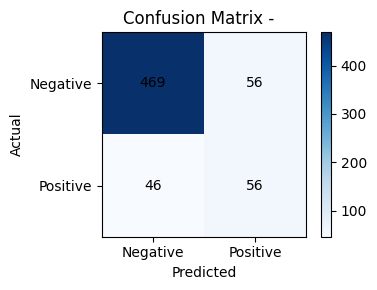

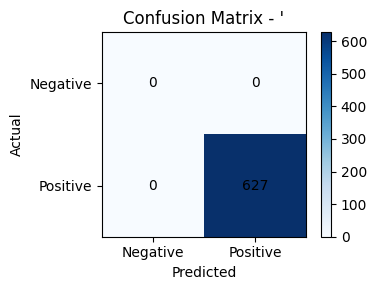

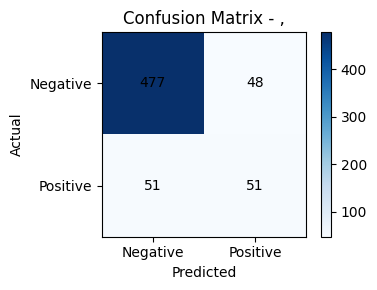

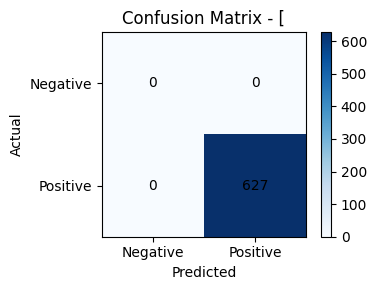

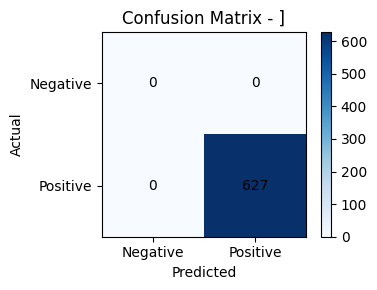

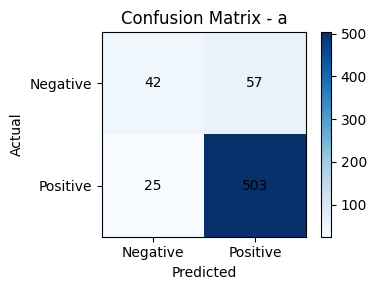

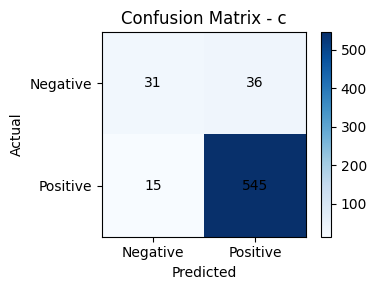

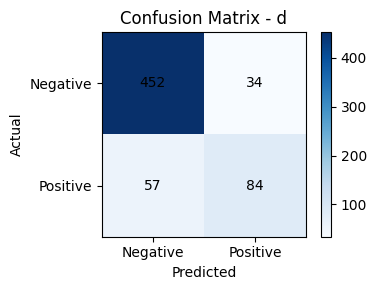

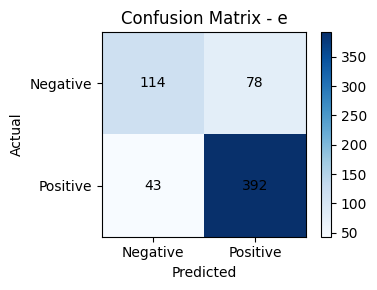

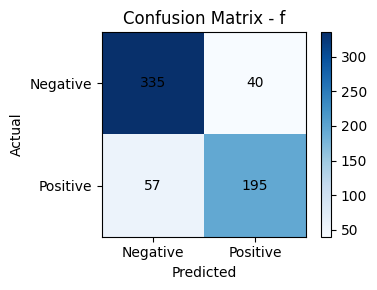

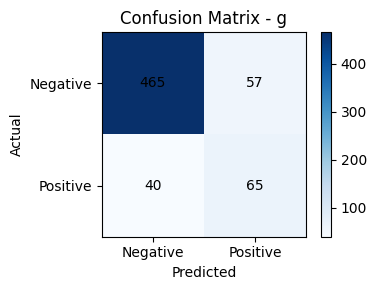

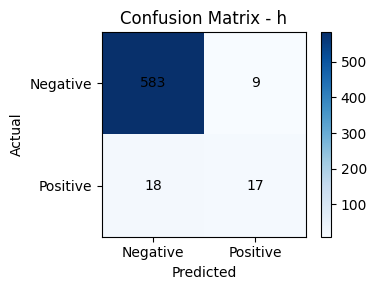

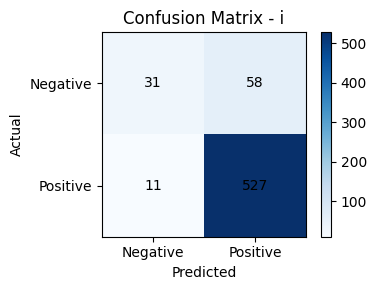

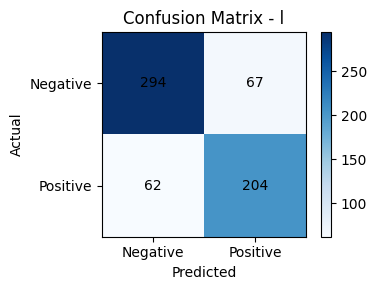

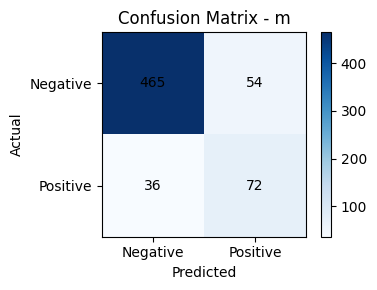

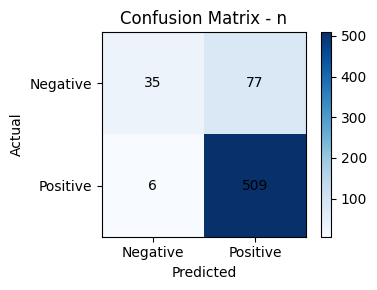

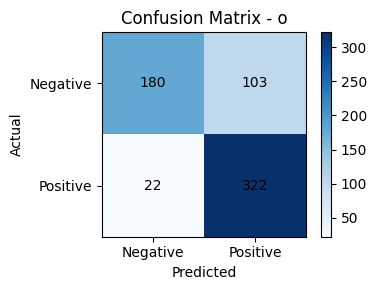

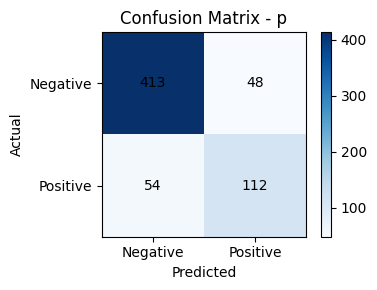

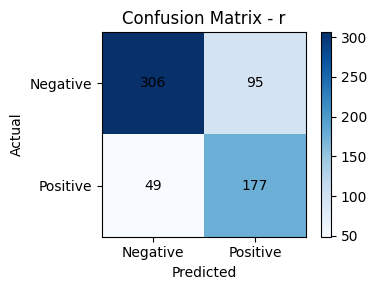

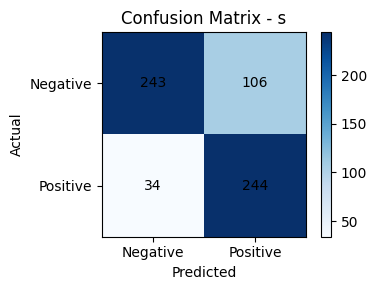

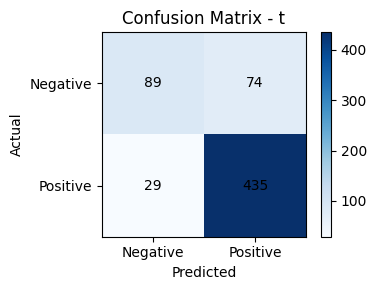

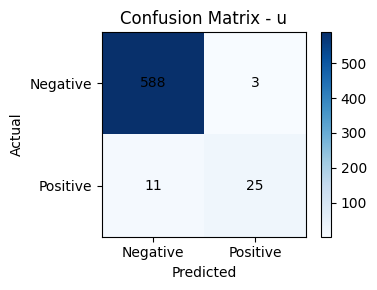

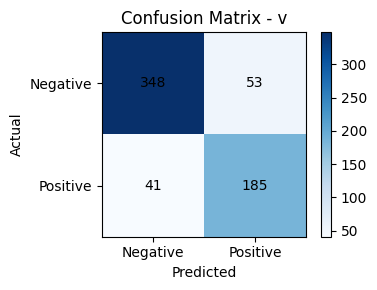

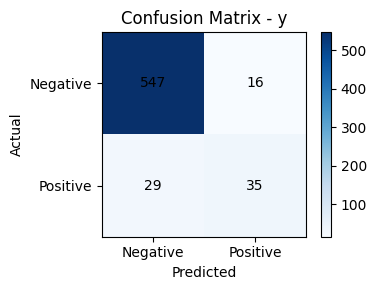

In [226]:
# ============================================================
# STEP 19: Per-Class Confusion Matrices
# ============================================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

for i, label_name in enumerate(mlb.classes_):

    # Force confusion_matrix to be a 2x2 matrix by specifying labels=[0, 1]
    cm = confusion_matrix(
        test_labels[:, i],
        test_predictions[:, i],
        labels=[0, 1]
    )

    plt.figure(figsize=(4, 3))

    plt.imshow(cm, cmap="Blues")

    plt.title(
        f"Confusion Matrix - {label_name}"
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.xticks([0, 1], ["Negative", "Positive"])
    plt.yticks([0, 1], ["Negative", "Positive"])

    for x in range(2):
        for y in range(2):
            plt.text(
                y,
                x,
                cm[x, y],
                ha="center",
                va="center"
            )

    plt.colorbar()
    plt.tight_layout()
    plt.show()

In [227]:
display(summary)

,Metric,Score
0,Macro Precision,0.771832
1,Macro Recall,0.792536
2,Macro F1,0.778705
3,Micro F1,0.874481
4,Weighted F1,0.874898
5,Macro AUROC,NaN
6,Micro AUROC,0.938948
7,Macro AUPRC,0.824909
8,Micro AUPRC,0.943616


In [228]:
threshold_analysis = pd.DataFrame({
    "Label": mlb.classes_,
    "Threshold": best_thresholds,
    "Validation_F1": best_f1
})

display(
    threshold_analysis.sort_values(
        "Validation_F1"
    )
)

,Label,Threshold,Validation_F1
11,h,0.71,0.485981
2,",",0.62,0.554622
0,,0.62,0.558904
10,g,0.56,0.561743
23,y,0.65,0.613861
7,d,0.67,0.628702
14,m,0.53,0.631579
21,u,0.71,0.677966
17,p,0.53,0.681507
18,r,0.51,0.742529


In [229]:
support_comparison = pd.DataFrame({

    "Label": mlb.classes_,

    "Train_Support":
        train_labels_final.sum(axis=0),

    "Validation_Support":
        val_labels.sum(axis=0),

    "Test_Support":
        test_labels.sum(axis=0)

})

display(support_comparison)

,Label,Train_Support,Validation_Support,Test_Support
0,,975,172,102
1,',6019,1060,627
2,",",975,172,102
3,[,6019,1060,627
4,],6019,1060,627
5,a,5085,897,528
6,c,5347,921,560
7,d,1355,239,141
8,e,4248,736,435
9,f,2498,446,252


In [230]:
# ============================================================
# Validation vs Test F1
# ============================================================

val_predictions = np.zeros_like(
    val_probabilities,
    dtype=int
)

test_predictions = np.zeros_like(
    test_probabilities,
    dtype=int
)

for i in range(NUM_LABELS):

    val_predictions[:, i] = (
        val_probabilities[:, i]
        >= best_thresholds[i]
    ).astype(int)

    test_predictions[:, i] = (
        test_probabilities[:, i]
        >= best_thresholds[i]
    ).astype(int)


val_f1 = f1_score(
    val_labels,
    val_predictions,
    average=None,
    zero_division=0
)

test_f1 = f1_score(
    test_labels,
    test_predictions,
    average=None,
    zero_division=0
)


comparison = pd.DataFrame({

    "Label": mlb.classes_,

    "Threshold": best_thresholds,

    "Validation_F1": val_f1,

    "Test_F1": test_f1,

    "Drop": val_f1 - test_f1

})

display(comparison)

,Label,Threshold,Validation_F1,Test_F1,Drop
0,,0.62,0.558904,0.523364,0.035540
1,',0.05,1.000000,1.000000,0.000000
2,",",0.62,0.554622,0.507463,0.047159
3,[,0.05,1.000000,1.000000,0.000000
4,],0.05,1.000000,1.000000,0.000000
5,a,0.49,0.946108,0.924632,0.021475
6,c,0.56,0.942675,0.955302,-0.012627
7,d,0.67,0.628702,0.648649,-0.019947
8,e,0.46,0.886706,0.866298,0.020408
9,f,0.55,0.800475,0.800821,-0.000346


In [231]:
# ============================================================
# Validation vs Test F1
# ============================================================

val_predictions = np.zeros_like(
    val_probabilities,
    dtype=int
)

test_predictions = np.zeros_like(
    test_probabilities,
    dtype=int
)

for i in range(NUM_LABELS):

    val_predictions[:, i] = (
        val_probabilities[:, i]
        >= best_thresholds[i]
    ).astype(int)

    test_predictions[:, i] = (
        test_probabilities[:, i]
        >= best_thresholds[i]
    ).astype(int)


val_f1 = f1_score(
    val_labels,
    val_predictions,
    average=None,
    zero_division=0
)

test_f1 = f1_score(
    test_labels,
    test_predictions,
    average=None,
    zero_division=0
)


comparison = pd.DataFrame({

    "Label": mlb.classes_,

    "Threshold": best_thresholds,

    "Validation_F1": val_f1,

    "Test_F1": test_f1,

    "Drop": val_f1 - test_f1

})

display(comparison)

,Label,Threshold,Validation_F1,Test_F1,Drop
0,,0.62,0.558904,0.523364,0.035540
1,',0.05,1.000000,1.000000,0.000000
2,",",0.62,0.554622,0.507463,0.047159
3,[,0.05,1.000000,1.000000,0.000000
4,],0.05,1.000000,1.000000,0.000000
5,a,0.49,0.946108,0.924632,0.021475
6,c,0.56,0.942675,0.955302,-0.012627
7,d,0.67,0.628702,0.648649,-0.019947
8,e,0.46,0.886706,0.866298,0.020408
9,f,0.55,0.800475,0.800821,-0.000346


In [232]:
# ============================================================
# GLOBAL MACRO-F1 THRESHOLD OPTIMIZATION
# ============================================================

from sklearn.metrics import f1_score
import numpy as np


def calculate_macro_f1(
    y_true,
    probabilities,
    thresholds
):

    predictions = (
        probabilities >= thresholds
    ).astype(int)

    return f1_score(
        y_true,
        predictions,
        average="macro",
        zero_division=0
    )


macro_thresholds = np.full(
    NUM_LABELS,
    0.50
)

print(
    "Initial Macro-F1:",
    calculate_macro_f1(
        val_labels,
        val_probabilities,
        macro_thresholds
    )
)


# Coordinate descent
for iteration in range(3):

    for label in range(NUM_LABELS):

        best_score = -1

        best_threshold = (
            macro_thresholds[label]
        )

        for threshold in np.arange(
            0.10,
            0.91,
            0.02
        ):

            candidate = (
                macro_thresholds.copy()
            )

            candidate[label] = threshold

            score = calculate_macro_f1(
                val_labels,
                val_probabilities,
                candidate
            )

            if score > best_score:

                best_score = score

                best_threshold = threshold

        macro_thresholds[label] = (
            best_threshold
        )

    print(
        f"Iteration {iteration + 1}: "
        f"Macro-F1 = "
        f"{calculate_macro_f1(
            val_labels,
            val_probabilities,
            macro_thresholds
        ):.4f}"
    )


print("\nFinal thresholds:")

for i, label in enumerate(mlb.classes_):

    print(
        f"{label:25s} "
        f"{macro_thresholds[i]:.2f}"
    )

Initial Macro-F1: 0.7461679707337868
Iteration 1: Macro-F1 = 0.7748
Iteration 2: Macro-F1 = 0.7748
Iteration 3: Macro-F1 = 0.7748

Final thresholds:
                          0.62
'                         0.10
,                         0.62
[                         0.10
]                         0.10
a                         0.50
c                         0.56
d                         0.66
e                         0.46
f                         0.54
g                         0.56
h                         0.72
i                         0.42
l                         0.44
m                         0.54
n                         0.42
o                         0.38
p                         0.48
r                         0.58
s                         0.42
t                         0.40
u                         0.78
v                         0.54
y                         0.66


In [241]:
import os
import ast
import random
import numpy as np
import pandas as pd
import warnings

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer

from rdkit import Chem
from rdkit import RDLogger

from transformers import (
    AutoTokenizer,
    AutoModel
)

from torch_geometric.data import Data as GraphData
from torch_geometric.nn import (
    GATv2Conv,
    global_mean_pool
)

# Suppress RDKit warnings
RDLogger.DisableLog('rdApp.*')
warnings.filterwarnings("ignore", message="not removing hydrogen atom without neighbors")


SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


In [242]:
# ============================================================
# CELL 2 — LOAD DATASET
# ============================================================

from google.colab import drive

drive.mount("/content/drive")

PATH = "/content/drive/MyDrive/dataset/all_chem_df.csv"

df = pd.read_csv(PATH)

print("Dataset shape:", df.shape)

display(df.head())

print("\nColumns:")
print(df.columns.tolist())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset shape: (8336, 4)


,image_name,tags,smiles,Col3
0,pics/0,dermatologic,CC(=O)NC1C(O)OC(CO)C(O)C1O,['dermatologic']
1,pics/1,antiinfective,CCC[C@@]1(CCc2ccccc2)CC(O)=C([C@H](CC)c2cccc(N...,['antiinfective']
2,pics/2,antiinfective,CCCCC(C)C(=O)OC1C(C)C(CC)OC2(CC3CC(C/C=C(\C)CC...,['antiinfective']
3,pics/3,antineoplastic,COc1cc2c(c(OC)c1OC)-c1c(cc3c(c1OC)OCO3)C[C@H](...,['antineoplastic']
4,pics/4,antiinfective respiratorysystem,CC(=O)N[C@@H](CS)C(=O)[O-],"['antiinfective', 'respiratorysystem']"



Columns:
['image_name', 'tags', 'smiles', 'Col3']


In [243]:
import pandas as pd
import ast
from sklearn.preprocessing import MultiLabelBinarizer
from rdkit import Chem

# ============================================================
# CELL 3 — LABEL PROCESSING (with Dataset Reload to avoid KeyError)
# ============================================================

# Reload original dataset to ensure Col3 and smiles columns exist
PATH = "/content/drive/MyDrive/dataset/all_chem_df.csv"
df = pd.read_csv(PATH)

def parse_labels(x):
    if pd.isna(x):
        return []
    if isinstance(x, list):
        return x
    try:
        value = ast.literal_eval(x)
        if isinstance(value, list):
            return value
        return [str(value)]
    except:
        return [str(x)]

df["label_list"] = df["Col3"].apply(parse_labels)

# Remove invalid SMILES
df = df[df["smiles"].notna()].copy()
df["smiles"] = df["smiles"].astype(str)

# Validate SMILES
def valid_smiles(s):
    try:
        return Chem.MolFromSmiles(s) is not None
    except:
        return False

df["valid"] = df["smiles"].apply(valid_smiles)
df = df[df["valid"]].copy()

print("Valid molecules:", len(df))

mlb = MultiLabelBinarizer()
labels = mlb.fit_transform(df["label_list"])
NUM_LABELS = labels.shape[1]

print("Number of classes:", NUM_LABELS)
print("Classes:", mlb.classes_)

df = df.reset_index(drop=True)

Valid molecules: 8336
Number of classes: 12
Classes: ['antiinfective' 'antiinflammatory' 'antineoplastic' 'cardio' 'cns'
 'dermatologic' 'gastrointestinal' 'hematologic' 'lipidregulating'
 'reproductivecontrol' 'respiratorysystem' 'urological']


In [244]:
# ============================================================
# CELL 4 — MOLECULAR GRAPH CONSTRUCTION
# ============================================================

def atom_features(atom):

    return [
        atom.GetAtomicNum(),
        atom.GetDegree(),
        atom.GetFormalCharge(),
        int(atom.GetIsAromatic()),
        int(atom.GetHybridization()),
        atom.GetTotalNumHs(),
    ]


def bond_features(bond):

    return [
        float(bond.GetBondTypeAsDouble()),
        int(bond.GetIsAromatic()),
        int(bond.GetIsConjugated()),
    ]


def smiles_to_graph(smiles):

    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    x = []

    for atom in mol.GetAtoms():
        x.append(
            atom_features(atom)
        )

    x = torch.tensor(
        x,
        dtype=torch.float
    )

    edge_index = []
    edge_attr = []

    for bond in mol.GetBonds():

        i = bond.GetBeginAtomIdx()
        j = bond.GetEndAtomIdx()

        edge_index.append([i, j])
        edge_index.append([j, i])

        features = bond_features(bond)

        edge_attr.append(features)
        edge_attr.append(features)

    if len(edge_index) == 0:

        edge_index = torch.empty(
            (2, 0),
            dtype=torch.long
        )

        edge_attr = torch.empty(
            (0, 3),
            dtype=torch.float

        )

    else:

        edge_index = torch.tensor(
            edge_index,
            dtype=torch.long
        ).t().contiguous()

        edge_attr = torch.tensor(
            edge_attr,
            dtype=torch.float
        )

    return GraphData(
        x=x,
        edge_index=edge_index,
        edge_attr=edge_attr
    )

In [245]:
# ============================================================
# CELL 5 — CHEMBERTA + GAT HYBRID MODEL
# ============================================================

class ChemGraphMT(nn.Module):

    def __init__(
        self,
        num_labels,
        chemberta_name="DeepChem/ChemBERTa-77M-MLM",
        hidden_dim=256,
        dropout=0.2
    ):

        super().__init__()

        # ----------------------------------------------------
        # ChemBERTa
        # ----------------------------------------------------

        self.chemberta = AutoModel.from_pretrained(
            chemberta_name
        )

        bert_dim = (
            self.chemberta.config.hidden_size
        )

        # ----------------------------------------------------
        # GAT
        # ----------------------------------------------------

        self.gat1 = GATv2Conv(
            in_channels=6,
            out_channels=128,
            heads=2,
            dropout=dropout
        )

        self.gat2 = GATv2Conv(
            in_channels=256,
            out_channels=128,
            heads=1,
            dropout=dropout
        )

        self.graph_projection = nn.Sequential(

            nn.Linear(128, hidden_dim),

            nn.LayerNorm(hidden_dim),

            nn.GELU(),

            nn.Dropout(dropout)
        )

        # ----------------------------------------------------
        # SMILES projection
        # ----------------------------------------------------

        self.smiles_projection = nn.Sequential(

            nn.Linear(
                bert_dim,
                hidden_dim
            ),

            nn.LayerNorm(hidden_dim),

            nn.GELU(),

            nn.Dropout(dropout)
        )

        # ----------------------------------------------------
        # Fusion
        # ----------------------------------------------------

        self.fusion = nn.Sequential(

            nn.Linear(
                hidden_dim * 2,
                512
            ),

            nn.LayerNorm(512),

            nn.GELU(),

            nn.Dropout(dropout),

            nn.Linear(
                512,
                hidden_dim
            ),

            nn.LayerNorm(hidden_dim),

            nn.GELU()
        )

        # ----------------------------------------------------
        # Drug-class prediction
        # ----------------------------------------------------

        self.classifier = nn.Sequential(

            nn.Linear(
                hidden_dim,
                128
            ),

            nn.GELU(),

            nn.Dropout(dropout),

            nn.Linear(
                128,
                num_labels
            )
        )

    def forward(
        self,
        input_ids,
        attention_mask,
        graph
    ):

        # ====================================================
        # SMILES REPRESENTATION
        # ====================================================

        bert_output = self.chemberta(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        smiles_embedding = (
            bert_output.last_hidden_state[:, 0, :]
        )

        smiles_embedding = (
            self.smiles_projection(
                smiles_embedding
            )
        )

        # ====================================================
        # GRAPH REPRESENTATION
        # ====================================================

        x = graph.x

        x = self.gat1(
            x,
            graph.edge_index
        )

        x = F.elu(x)

        x = self.gat2(
            x,
            graph.edge_index
        )

        x = F.elu(x)

        x = global_mean_pool(
            x,
            graph.batch
        )

        graph_embedding = (
            self.graph_projection(x)
        )

        # ====================================================
        # MULTIMODAL FUSION
        # ====================================================

        combined = torch.cat(
            [
                smiles_embedding,
                graph_embedding
            ],
            dim=1
        )

        fused = self.fusion(
            combined
        )

        # ====================================================
        # CLASSIFICATION
        # ====================================================

        logits = self.classifier(
            fused
        )

        return logits

In [246]:
print("Dataset:", df.shape)
print("Classes:", mlb.classes_)
print("Number of classes:", NUM_LABELS)

class_counts = labels.sum(axis=0)

for i, cls in enumerate(mlb.classes_):
    print(f"{i:2d} {cls:25s} {class_counts[i]}")

Dataset: (8336, 6)
Classes: ['antiinfective' 'antiinflammatory' 'antineoplastic' 'cardio' 'cns'
 'dermatologic' 'gastrointestinal' 'hematologic' 'lipidregulating'
 'reproductivecontrol' 'respiratorysystem' 'urological']
Number of classes: 12
 0 antiinfective             2923
 1 antiinflammatory          591
 2 antineoplastic            1642
 3 cardio                    1262
 4 cns                       1528
 5 dermatologic              226
 6 gastrointestinal          490
 7 hematologic               462
 8 lipidregulating           203
 9 reproductivecontrol       225
10 respiratorysystem         281
11 urological                48


In [247]:
!pip install -q iterative-stratification

In [248]:
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

X = df["smiles"].values
Y = labels

msss = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, temp_idx = next(
    msss.split(X, Y)
)

train_df = df.iloc[train_idx].reset_index(drop=True)
temp_df = df.iloc[temp_idx].reset_index(drop=True)

train_labels = labels[train_idx]
temp_labels = labels[temp_idx]

In [249]:
msss2 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    msss2.split(
        temp_df["smiles"].values,
        temp_labels
    )
)

val_df = temp_df.iloc[val_idx].reset_index(drop=True)
test_df = temp_df.iloc[test_idx].reset_index(drop=True)

val_labels = temp_labels[val_idx]
test_labels = temp_labels[test_idx]

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (6673, 6)
Validation: (832, 6)
Test: (831, 6)


In [250]:
from transformers import AutoTokenizer

MODEL_NAME = "DeepChem/ChemBERTa-77M-MLM"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

MAX_LENGTH = 128

config.json:   0%|          | 0.00/631 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.27k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/6.96k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/8.26k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/420 [00:00<?, ?B/s]

In [251]:
example_smiles = train_df.iloc[0]["smiles"]

graph = smiles_to_graph(
    example_smiles
)

print(graph)
print("Nodes:", graph.x.shape)
print("Edges:", graph.edge_index.shape)

Data(x=[15, 6], edge_index=[2, 30], edge_attr=[30, 3])
Nodes: torch.Size([15, 6])
Edges: torch.Size([2, 30])


In [252]:
class MolecularDataset(Dataset):

    def __init__(
        self,
        dataframe,
        labels,
        tokenizer,
        max_length=128
    ):

        self.df = dataframe.reset_index(drop=True)

        self.labels = torch.tensor(
            labels,
            dtype=torch.float
        )

        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):

        return len(self.df)

    def __getitem__(self, idx):

        smiles = self.df.iloc[idx]["smiles"]

        # -------------------------------
        # SMILES TOKENIZATION
        # -------------------------------

        encoded = self.tokenizer(
            smiles,
            padding="max_length",
            truncation=True,
            max_length=self.max_length,
            return_tensors="pt"
        )

        input_ids = encoded["input_ids"].squeeze(0)

        attention_mask = encoded[
            "attention_mask"
        ].squeeze(0)

        # -------------------------------
        # MOLECULAR GRAPH
        # -------------------------------

        graph = smiles_to_graph(smiles)

        # -------------------------------
        # LABEL
        # -------------------------------

        label = self.labels[idx]

        return {
            "input_ids": input_ids,
            "attention_mask": attention_mask,
            "graph": graph,
            "labels": label
        }

In [253]:
train_dataset = MolecularDataset(
    train_df,
    train_labels,
    tokenizer,
    MAX_LENGTH
)

val_dataset = MolecularDataset(
    val_df,
    val_labels,
    tokenizer,
    MAX_LENGTH
)

test_dataset = MolecularDataset(
    test_df,
    test_labels,
    tokenizer,
    MAX_LENGTH
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 6673
Validation: 832
Test: 831


In [254]:
from torch_geometric.data import Batch

def collate_fn(batch):

    input_ids = torch.stack([
        item["input_ids"]
        for item in batch
    ])

    attention_mask = torch.stack([
        item["attention_mask"]
        for item in batch
    ])

    labels = torch.stack([
        item["labels"]
        for item in batch
    ])

    graphs = Batch.from_data_list([
        item["graph"]
        for item in batch
    ])

    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "graph": graphs,
        "labels": labels
    }

In [255]:
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=2,
    pin_memory=True
)

In [256]:
batch = next(iter(train_loader))

print(
    "Input IDs:",
    batch["input_ids"].shape
)

print(
    "Attention mask:",
    batch["attention_mask"].shape
)

print(
    "Labels:",
    batch["labels"].shape
)

print(
    "Graph nodes:",
    batch["graph"].x.shape
)

print(
    "Graph edges:",
    batch["graph"].edge_index.shape
)

print(
    "Graph batch:",
    batch["graph"].batch.shape
)

Input IDs: torch.Size([16, 128])
Attention mask: torch.Size([16, 128])
Labels: torch.Size([16, 12])
Graph nodes: torch.Size([454, 6])
Graph edges: torch.Size([2, 976])
Graph batch: torch.Size([454])


In [257]:
model = ChemGraphMT(
    num_labels=NUM_LABELS,
    chemberta_name=MODEL_NAME,
    hidden_dim=256,
    dropout=0.20
)

model = model.to(device)

print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )
)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 13.7MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: DeepChem/ChemBERTa-77M-MLM
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.decoder.weight    | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.decoder.bias      | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trainable parameters: 4060156


In [258]:
for param in model.chemberta.parameters():
    param.requires_grad = False

In [259]:
for param in model.chemberta.parameters():
    param.requires_grad = True

In [260]:
counts = train_labels.sum(axis=0)

beta = 0.999

effective_weights = (
    (1 - beta) /
    (1 - np.power(beta, counts))
)

effective_weights = (
    effective_weights /
    effective_weights.mean()
)

effective_weights = np.clip(
    effective_weights,
    0.5,
    10.0
)

class_weights = torch.tensor(
    effective_weights,
    dtype=torch.float32
).to(device)

print(
    pd.DataFrame({
        "Class": mlb.classes_,
        "Count": counts,
        "Weight": effective_weights
    })
)

                  Class  Count    Weight
0         antiinfective   2338  0.500000
1      antiinflammatory    473  0.500000
2        antineoplastic   1313  0.500000
3                cardio   1009  0.500000
4                   cns   1222  0.500000
5          dermatologic    181  1.114781
6      gastrointestinal    392  0.569163
7           hematologic    370  0.596821
8       lipidregulating    162  1.234080
9   reproductivecontrol    180  1.120431
10    respiratorysystem    225  0.916055
11           urological     38  4.949761


In [261]:
class FocalBCELoss(nn.Module):

    def __init__(
        self,
        pos_weight=None,
        gamma=2.0
    ):

        super().__init__()

        self.pos_weight = pos_weight
        self.gamma = gamma

    def forward(
        self,
        logits,
        targets
    ):

        bce = F.binary_cross_entropy_with_logits(
            logits,
            targets,
            pos_weight=self.pos_weight,
            reduction="none"
        )

        probabilities = torch.sigmoid(logits)

        pt = (
            targets * probabilities
            +
            (1 - targets) * (1 - probabilities)
        )

        focal_weight = (
            1 - pt
        ).pow(self.gamma)

        loss = focal_weight * bce

        return loss.mean()

In [262]:
criterion = FocalBCELoss(
    pos_weight=class_weights,
    gamma=2.0
)

In [263]:
optimizer = torch.optim.AdamW(
    [
        {
            "params": model.chemberta.parameters(),
            "lr": 1e-5
        },
        {
            "params": [
                p for name, p
                in model.named_parameters()
                if not name.startswith("chemberta.")
            ],
            "lr": 2e-4
        }
    ],
    weight_decay=1e-4
)

In [264]:
torch.nn.utils.clip_grad_norm_(
    model.parameters(),
    max_norm=1.0
)

tensor(0.)

In [265]:
# ============================================================
# CELL 1 — EVALUATION IMPORTS
# ============================================================

import os
import copy
import numpy as np
import pandas as pd

import torch
import torch.nn.functional as F

from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
    classification_report
)

MODEL_SAVE_PATH = "/content/drive/MyDrive/dataset/best_chemgraph_gatv2.pt"

print("Evaluation setup ready")

Evaluation setup ready


In [266]:
# ============================================================
# CELL 2 — TRAINING FUNCTION
# ============================================================

def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion,
    device
):

    model.train()

    total_loss = 0.0
    total_samples = 0

    for batch in loader:

        input_ids = batch["input_ids"].to(
            device,
            non_blocking=True
        )

        attention_mask = batch["attention_mask"].to(
            device,
            non_blocking=True
        )

        labels = batch["labels"].to(
            device,
            non_blocking=True
        )

        graph = batch["graph"].to(device)

        # ----------------------------------------------------
        # Clear gradients
        # ----------------------------------------------------

        optimizer.zero_grad(
            set_to_none=True
        )

        # ----------------------------------------------------
        # Forward pass
        # ----------------------------------------------------

        logits = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            graph=graph
        )

        # ----------------------------------------------------
        # Loss
        # ----------------------------------------------------

        loss = criterion(
            logits,
            labels
        )

        # ----------------------------------------------------
        # Backpropagation
        # ----------------------------------------------------

        loss.backward()

        # ----------------------------------------------------
        # Gradient clipping
        # ----------------------------------------------------

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        # ----------------------------------------------------
        # Update parameters
        # ----------------------------------------------------

        optimizer.step()

        batch_size = labels.size(0)

        total_loss += (
            loss.item() * batch_size
        )

        total_samples += batch_size

    epoch_loss = (
        total_loss /
        max(total_samples, 1)
    )

    return epoch_loss

In [267]:
# ============================================================
# CELL 3 — VALIDATION FUNCTION
# ============================================================

@torch.no_grad()
def evaluate_model(
    model,
    loader,
    device
):

    model.eval()

    all_probabilities = []
    all_labels = []

    total_loss = 0.0
    total_samples = 0

    for batch in loader:

        input_ids = batch["input_ids"].to(
            device,
            non_blocking=True
        )

        attention_mask = batch["attention_mask"].to(
            device,
            non_blocking=True
        )

        labels = batch["labels"].to(
            device,
            non_blocking=True
        )

        graph = batch["graph"].to(device)

        # ----------------------------------------------------
        # Forward
        # ----------------------------------------------------

        logits = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            graph=graph
        )

        # ----------------------------------------------------
        # BCE for validation loss
        # ----------------------------------------------------

        loss = F.binary_cross_entropy_with_logits(
            logits,
            labels
        )

        batch_size = labels.size(0)

        total_loss += (
            loss.item() * batch_size
        )

        total_samples += batch_size

        # ----------------------------------------------------
        # Probabilities
        # ----------------------------------------------------

        probabilities = torch.sigmoid(
            logits
        )

        all_probabilities.append(
            probabilities.cpu().numpy()
        )

        all_labels.append(
            labels.cpu().numpy()
        )

    probabilities = np.concatenate(
        all_probabilities,
        axis=0
    )

    labels = np.concatenate(
        all_labels,
        axis=0
    )

    avg_loss = (
        total_loss /
        max(total_samples, 1)
    )

    # --------------------------------------------------------
    # Default threshold only for monitoring
    # --------------------------------------------------------

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    macro_f1 = f1_score(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )

    micro_f1 = f1_score(
        labels,
        predictions,
        average="micro",
        zero_division=0
    )

    return {
        "loss": avg_loss,
        "macro_f1": macro_f1,
        "micro_f1": micro_f1,
        "probabilities": probabilities,
        "labels": labels
    }

In [ ]:
# ============================================================
# CELL 4 — TRAINING
# ============================================================

NUM_EPOCHS = 50

best_macro_f1 = -np.inf
best_epoch = 0

history = []

for epoch in range(NUM_EPOCHS):

    print("\n" + "=" * 70)
    print(f"Epoch {epoch + 1}/{NUM_EPOCHS}")
    print("=" * 70)

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    train_loss = train_one_epoch(
        model=model,
        loader=train_loader,
        optimizer=optimizer,
        criterion=criterion,
        device=device
    )

    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    val_results = evaluate_model(
        model=model,
        loader=val_loader,
        device=device
    )

    val_loss = val_results["loss"]
    val_macro_f1 = val_results["macro_f1"]
    val_micro_f1 = val_results["micro_f1"]

    # --------------------------------------------------------
    # Store history
    # --------------------------------------------------------

    history.append({
        "Epoch": epoch + 1,
        "Train Loss": train_loss,
        "Validation Loss": val_loss,
        "Validation Macro F1": val_macro_f1,
        "Validation Micro F1": val_micro_f1
    })

    print(
        f"Train Loss       : {train_loss:.6f}"
    )

    print(
        f"Validation Loss  : {val_loss:.6f}"
    )

    print(
        f"Validation Macro F1 : {val_macro_f1:.6f}"
    )

    print(
        f"Validation Micro F1 : {val_micro_f1:.6f}"
    )

    # --------------------------------------------------------
    # SAVE BEST MODEL
    # --------------------------------------------------------

    if val_macro_f1 > best_macro_f1:

        best_macro_f1 = val_macro_f1
        best_epoch = epoch + 1

        torch.save(
            {
                "epoch": best_epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_macro_f1": best_macro_f1
            },
            MODEL_SAVE_PATH
        )

        print(
            f"✓ Best model saved "
            f"(Macro-F1={best_macro_f1:.6f})"
        )

print("\nTraining completed.")

print(
    f"Best Epoch: {best_epoch}"
)

print(
    f"Best Validation Macro-F1: "
    f"{best_macro_f1:.6f}"
)


Epoch 1/50
Train Loss       : 0.057900
Validation Loss  : 0.338239
Validation Macro F1 : 0.077596
Validation Micro F1 : 0.252757
✓ Best model saved (Macro-F1=0.077596)

Epoch 2/50
Train Loss       : 0.049055
Validation Loss  : 0.317972
Validation Macro F1 : 0.084397
Validation Micro F1 : 0.268631
✓ Best model saved (Macro-F1=0.084397)

Epoch 3/50
Train Loss       : 0.044365
Validation Loss  : 0.294846
Validation Macro F1 : 0.305457
Validation Micro F1 : 0.415065
✓ Best model saved (Macro-F1=0.305457)

Epoch 4/50
Train Loss       : 0.041574
Validation Loss  : 0.289973
Validation Macro F1 : 0.353141
Validation Micro F1 : 0.426584
✓ Best model saved (Macro-F1=0.353141)

Epoch 5/50
Train Loss       : 0.038836
Validation Loss  : 0.280713
Validation Macro F1 : 0.418505
Validation Micro F1 : 0.485199
✓ Best model saved (Macro-F1=0.418505)

Epoch 6/50
Train Loss       : 0.036972
Validation Loss  : 0.268261
Validation Macro F1 : 0.441061
Validation Micro F1 : 0.521986
✓ Best model saved (Macro

In [269]:
# ============================================================
# CELL 5 — TRAINING HISTORY
# ============================================================

history_df = pd.DataFrame(history)

display(history_df)

,Epoch,Train Loss,Validation Loss,Validation Macro F1,Validation Micro F1
0,1,0.057900,0.338239,0.077596,0.252757
1,2,0.049055,0.317972,0.084397,0.268631
2,3,0.044365,0.294846,0.305457,0.415065
3,4,0.041574,0.289973,0.353141,0.426584
4,5,0.038836,0.280713,0.418505,0.485199
5,6,0.036972,0.268261,0.441061,0.521986
6,7,0.035207,0.263955,0.452578,0.524148
7,8,0.034094,0.250940,0.468097,0.526539
8,9,0.032827,0.246967,0.459745,0.559459
9,10,0.031421,0.242357,0.495276,0.575818


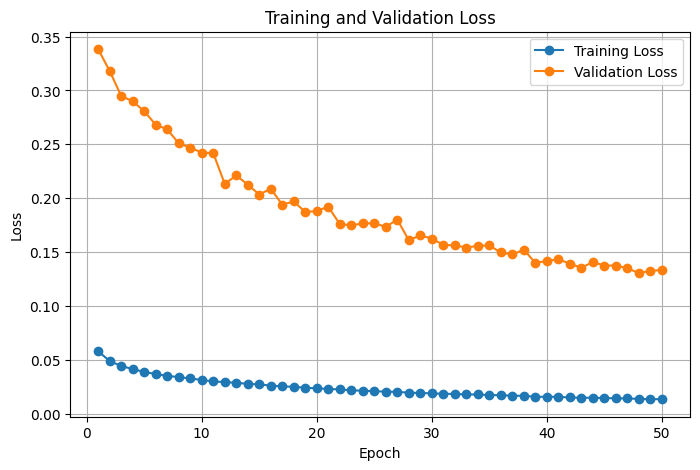

In [270]:
# ============================================================
# CELL 6 — TRAINING CURVES
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history_df["Epoch"],
    history_df["Train Loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history_df["Epoch"],
    history_df["Validation Loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.show()

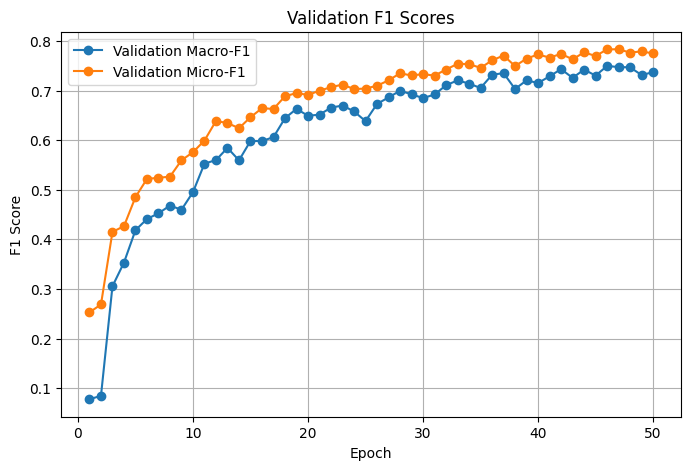

In [271]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_df["Epoch"],
    history_df["Validation Macro F1"],
    marker="o",
    label="Validation Macro-F1"
)

plt.plot(
    history_df["Epoch"],
    history_df["Validation Micro F1"],
    marker="o",
    label="Validation Micro-F1"
)

plt.xlabel("Epoch")
plt.ylabel("F1 Score")
plt.title("Validation F1 Scores")

plt.legend()
plt.grid(True)

plt.show()

In [272]:
# ============================================================
# CELL 7 — LOAD BEST MODEL
# ============================================================

checkpoint = torch.load(
    MODEL_SAVE_PATH,
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.to(device)

print(
    "Best epoch:",
    checkpoint["epoch"]
)

print(
    "Best validation Macro-F1:",
    checkpoint["best_macro_f1"]
)

Best epoch: 46
Best validation Macro-F1: 0.7496835963627438


In [273]:
# ============================================================
# CELL 8 — VALIDATION PROBABILITIES
# ============================================================

val_results = evaluate_model(
    model,
    val_loader,
    device
)

val_probabilities = (
    val_results["probabilities"]
)

val_true = (
    val_results["labels"]
)

print(
    "Validation probabilities:",
    val_probabilities.shape
)

print(
    "Validation labels:",
    val_true.shape
)

Validation probabilities: (832, 12)
Validation labels: (832, 12)


In [274]:
# ============================================================
# CELL 9 — CLASS-WISE THRESHOLD OPTIMIZATION
# ============================================================

def optimize_class_thresholds(
    y_true,
    probabilities,
    start=0.10,
    end=0.90,
    step=0.01
):

    thresholds = np.arange(
        start,
        end + step,
        step
    )

    best_thresholds = []
    best_scores = []

    num_classes = y_true.shape[1]

    for c in range(num_classes):

        best_f1 = -1
        best_threshold = 0.5

        for threshold in thresholds:

            pred = (
                probabilities[:, c]
                >= threshold
            ).astype(int)

            score = f1_score(
                y_true[:, c],
                pred,
                zero_division=0
            )

            if score > best_f1:

                best_f1 = score
                best_threshold = threshold

        best_thresholds.append(
            best_threshold
        )

        best_scores.append(
            best_f1
        )

    return (
        np.array(best_thresholds),
        np.array(best_scores)
    )

In [275]:
best_thresholds, validation_class_f1 = (
    optimize_class_thresholds(
        val_true,
        val_probabilities
    )
)

In [276]:
# ============================================================
# CELL 10 — THRESHOLD TABLE
# ============================================================

threshold_table = pd.DataFrame({

    "Label_ID": np.arange(NUM_LABELS),

    "Label": mlb.classes_,

    "Support": val_true.sum(axis=0),

    "Threshold": best_thresholds,

    "Validation_F1": validation_class_f1
})

display(
    threshold_table.sort_values(
        "Validation_F1"
    )
)

,Label_ID,Label,Support,Threshold,Validation_F1
10,10,respiratorysystem,28.0,0.61,0.651163
9,9,reproductivecontrol,22.0,0.52,0.666667
3,3,cardio,126.0,0.40,0.739623
7,7,hematologic,46.0,0.38,0.755556
6,6,gastrointestinal,49.0,0.40,0.764045
5,5,dermatologic,22.0,0.54,0.769231
1,1,antiinflammatory,59.0,0.43,0.796460
4,4,cns,153.0,0.38,0.808642
2,2,antineoplastic,164.0,0.39,0.819048
8,8,lipidregulating,20.0,0.61,0.823529


In [277]:
# ============================================================
# CELL 11 — VALIDATION OPTIMIZED PREDICTIONS
# ============================================================

val_optimized_predictions = np.zeros_like(
    val_probabilities,
    dtype=int
)

for c in range(NUM_LABELS):

    val_optimized_predictions[:, c] = (
        val_probabilities[:, c]
        >= best_thresholds[c]
    ).astype(int)

In [278]:
optimized_val_macro_f1 = f1_score(
    val_true,
    val_optimized_predictions,
    average="macro",
    zero_division=0
)

optimized_val_micro_f1 = f1_score(
    val_true,
    val_optimized_predictions,
    average="micro",
    zero_division=0
)

print(
    f"Optimized Validation Macro-F1: "
    f"{optimized_val_macro_f1:.6f}"
)

print(
    f"Optimized Validation Micro-F1: "
    f"{optimized_val_micro_f1:.6f}"
)

Optimized Validation Macro-F1: 0.780892
Optimized Validation Micro-F1: 0.805222


In [279]:
optimized_val_macro_f1 = f1_score(
    val_true,
    val_optimized_predictions,
    average="macro",
    zero_division=0
)

optimized_val_micro_f1 = f1_score(
    val_true,
    val_optimized_predictions,
    average="micro",
    zero_division=0
)

print(
    f"Optimized Validation Macro-F1: "
    f"{optimized_val_macro_f1:.6f}"
)

print(
    f"Optimized Validation Micro-F1: "
    f"{optimized_val_micro_f1:.6f}"
)

Optimized Validation Macro-F1: 0.780892
Optimized Validation Micro-F1: 0.805222


In [280]:
optimized_val_macro_f1 = f1_score(
    val_true,
    val_optimized_predictions,
    average="macro",
    zero_division=0
)

optimized_val_micro_f1 = f1_score(
    val_true,
    val_optimized_predictions,
    average="micro",
    zero_division=0
)

print(
    f"Optimized Validation Macro-F1: "
    f"{optimized_val_macro_f1:.6f}"
)

print(
    f"Optimized Validation Micro-F1: "
    f"{optimized_val_micro_f1:.6f}"
)

Optimized Validation Macro-F1: 0.780892
Optimized Validation Micro-F1: 0.805222


In [281]:
# ============================================================
# CELL 12 — TEST PREDICTIONS
# ============================================================

test_results = evaluate_model(
    model,
    test_loader,
    device
)

test_probabilities = (
    test_results["probabilities"]
)

test_true = (
    test_results["labels"]
)

print(
    "Test probabilities:",
    test_probabilities.shape
)

print(
    "Test labels:",
    test_true.shape
)

Test probabilities: (831, 12)
Test labels: (831, 12)


In [282]:
# ============================================================
# CELL 13 — FINAL TEST PREDICTIONS
# ============================================================

test_predictions = np.zeros_like(
    test_probabilities,
    dtype=int
)

for c in range(NUM_LABELS):

    test_predictions[:, c] = (
        test_probabilities[:, c]
        >= best_thresholds[c]
    ).astype(int)

In [283]:
# ============================================================
# CELL 14 — FINAL F1 METRICS
# ============================================================

final_macro_precision = precision_score(
    test_true,
    test_predictions,
    average="macro",
    zero_division=0
)

final_macro_recall = recall_score(
    test_true,
    test_predictions,
    average="macro",
    zero_division=0
)

final_macro_f1 = f1_score(
    test_true,
    test_predictions,
    average="macro",
    zero_division=0
)

final_micro_f1 = f1_score(
    test_true,
    test_predictions,
    average="micro",
    zero_division=0
)

final_weighted_f1 = f1_score(
    test_true,
    test_predictions,
    average="weighted",
    zero_division=0
)

print("=" * 65)
print("FINAL TEST CLASSIFICATION METRICS")
print("=" * 65)

print(
    f"Macro Precision : {final_macro_precision:.4f}"
)

print(
    f"Macro Recall    : {final_macro_recall:.4f}"
)

print(
    f"Macro F1        : {final_macro_f1:.4f}"
)

print(
    f"Micro F1        : {final_micro_f1:.4f}"
)

print(
    f"Weighted F1     : {final_weighted_f1:.4f}"
)

FINAL TEST CLASSIFICATION METRICS
Macro Precision : 0.7882
Macro Recall    : 0.6879
Macro F1        : 0.7282
Micro F1        : 0.7817
Weighted F1     : 0.7818


In [284]:
# ============================================================
# CELL 15 — AUROC AND AUPRC
# ============================================================

macro_auroc = roc_auc_score(
    test_true,
    test_probabilities,
    average="macro"
)

micro_auroc = roc_auc_score(
    test_true,
    test_probabilities,
    average="micro"
)

macro_auprc = average_precision_score(
    test_true,
    test_probabilities,
    average="macro"
)

micro_auprc = average_precision_score(
    test_true,
    test_probabilities,
    average="micro"
)

print("=" * 65)
print("FINAL TEST RANKING METRICS")
print("=" * 65)

print(
    f"Macro AUROC : {macro_auroc:.4f}"
)

print(
    f"Micro AUROC : {micro_auroc:.4f}"
)

print(
    f"Macro AUPRC : {macro_auprc:.4f}"
)

print(
    f"Micro AUPRC : {micro_auprc:.4f}"
)

FINAL TEST RANKING METRICS
Macro AUROC : 0.9369
Micro AUROC : 0.9646
Macro AUPRC : 0.7881
Micro AUPRC : 0.8598


In [285]:
# ============================================================
# CELL 16 — FINAL METRICS TABLE
# ============================================================

final_metrics = pd.DataFrame({

    "Metric": [
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Micro F1",
        "Weighted F1",
        "Macro AUROC",
        "Micro AUROC",
        "Macro AUPRC",
        "Micro AUPRC"
    ],

    "ChemGraph-GATv2": [

        final_macro_precision,

        final_macro_recall,

        final_macro_f1,

        final_micro_f1,

        final_weighted_f1,

        macro_auroc,

        micro_auroc,

        macro_auprc,

        micro_auprc
    ]
})

display(final_metrics)

,Metric,ChemGraph-GATv2
0,Macro Precision,0.788224
1,Macro Recall,0.687859
2,Macro F1,0.728237
3,Micro F1,0.781657
4,Weighted F1,0.781814
5,Macro AUROC,0.936871
6,Micro AUROC,0.964614
7,Macro AUPRC,0.788124
8,Micro AUPRC,0.859757


In [286]:
# ============================================================
# CELL 17 — PER-CLASS METRICS
# ============================================================

per_class_precision = precision_score(
    test_true,
    test_predictions,
    average=None,
    zero_division=0
)

per_class_recall = recall_score(
    test_true,
    test_predictions,
    average=None,
    zero_division=0
)

per_class_f1 = f1_score(
    test_true,
    test_predictions,
    average=None,
    zero_division=0
)

per_class_results = pd.DataFrame({

    "Label_ID": np.arange(NUM_LABELS),

    "Label": mlb.classes_,

    "Support": test_true.sum(axis=0),

    "Threshold": best_thresholds,

    "Precision": per_class_precision,

    "Recall": per_class_recall,

    "F1": per_class_f1
})

display(
    per_class_results.sort_values(
        "F1"
    )
)

,Label_ID,Label,Support,Threshold,Precision,Recall,F1
11,11,urological,5.0,0.39,0.600000,0.600000,0.600000
10,10,respiratorysystem,28.0,0.61,0.866667,0.464286,0.604651
5,5,dermatologic,23.0,0.54,0.764706,0.565217,0.650000
7,7,hematologic,46.0,0.38,0.632653,0.673913,0.652632
3,3,cardio,127.0,0.40,0.703390,0.653543,0.677551
6,6,gastrointestinal,49.0,0.40,0.738095,0.632653,0.681319
8,8,lipidregulating,21.0,0.61,0.875000,0.666667,0.756757
4,4,cns,153.0,0.38,0.698925,0.849673,0.766962
1,1,antiinflammatory,59.0,0.43,0.840000,0.711864,0.770642
2,2,antineoplastic,165.0,0.39,0.844156,0.787879,0.815047


In [287]:
# ============================================================
# CELL 18 — BASELINE VS PROPOSED MODEL
# ============================================================

comparison = pd.DataFrame({

    "Metric": [
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Micro F1",
        "Weighted F1",
        "Macro AUROC",
        "Micro AUROC",
        "Macro AUPRC",
        "Micro AUPRC"
    ],

    "ChemBERTa": [
        0.648804,
        0.537849,
        0.558966,
        0.595284,
        0.585794,
        0.884098,
        0.908873,
        0.610430,
        0.611315
    ],

    "ChemBERTa + GATv2": [
        final_macro_precision,
        final_macro_recall,
        final_macro_f1,
        final_micro_f1,
        final_weighted_f1,
        macro_auroc,
        micro_auroc,
        macro_auprc,
        micro_auprc
    ]
})

display(comparison)

,Metric,ChemBERTa,ChemBERTa + GATv2
0,Macro Precision,0.648804,0.788224
1,Macro Recall,0.537849,0.687859
2,Macro F1,0.558966,0.728237
3,Micro F1,0.595284,0.781657
4,Weighted F1,0.585794,0.781814
5,Macro AUROC,0.884098,0.936871
6,Micro AUROC,0.908873,0.964614
7,Macro AUPRC,0.610430,0.788124
8,Micro AUPRC,0.611315,0.859757


In [288]:
# ============================================================
# CELL 19 — IMPROVEMENT
# ============================================================

comparison["Improvement"] = (
    comparison["ChemBERTa + GATv2"]
    -
    comparison["ChemBERTa"]
)

comparison["Improvement_%"] = (
    comparison["Improvement"]
    /
    comparison["ChemBERTa"]
) * 100

display(comparison)

,Metric,ChemBERTa,ChemBERTa + GATv2,Improvement,Improvement_%
0,Macro Precision,0.648804,0.788224,0.139420,21.488787
1,Macro Recall,0.537849,0.687859,0.150010,27.890730
2,Macro F1,0.558966,0.728237,0.169271,30.282865
3,Micro F1,0.595284,0.781657,0.186373,31.308269
4,Weighted F1,0.585794,0.781814,0.196020,33.462331
5,Macro AUROC,0.884098,0.936871,0.052773,5.969100
6,Micro AUROC,0.908873,0.964614,0.055741,6.133013
7,Macro AUPRC,0.610430,0.788124,0.177694,29.109668
8,Micro AUPRC,0.611315,0.859757,0.248442,40.640620


In [289]:
# ============================================================
# CELL 20 — THRESHOLD ABLATION
# ============================================================

test_pred_05 = (
    test_probabilities >= 0.50
).astype(int)

f1_default = f1_score(
    test_true,
    test_pred_05,
    average="macro",
    zero_division=0
)

f1_optimized = f1_score(
    test_true,
    test_predictions,
    average="macro",
    zero_division=0
)

print(
    f"Macro-F1 @ 0.50       : {f1_default:.4f}"
)

print(
    f"Macro-F1 Optimized    : {f1_optimized:.4f}"
)

print(
    f"Improvement           : "
    f"{f1_optimized - f1_default:.4f}"
)

Macro-F1 @ 0.50       : 0.7304
Macro-F1 Optimized    : 0.7282
Improvement           : -0.0022


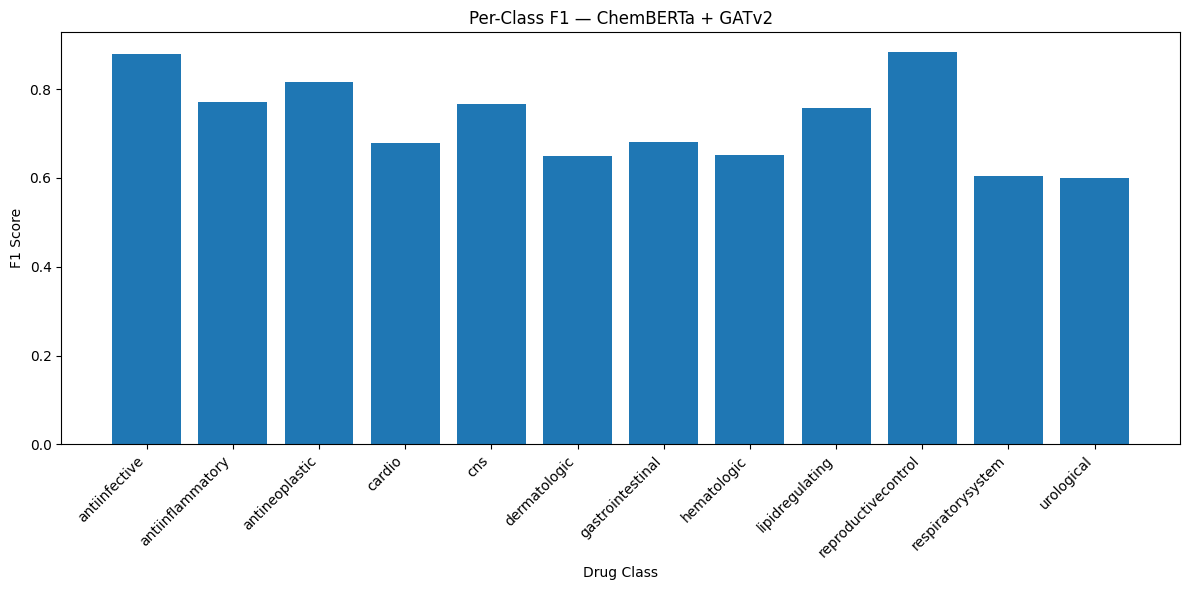

In [290]:
# ============================================================
# CELL 21 — PER-CLASS F1
# ============================================================

plt.figure(figsize=(12, 6))

plt.bar(
    per_class_results["Label"],
    per_class_results["F1"]
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.ylabel("F1 Score")
plt.xlabel("Drug Class")

plt.title(
    "Per-Class F1 — ChemBERTa + GATv2"
)

plt.tight_layout()

plt.show()

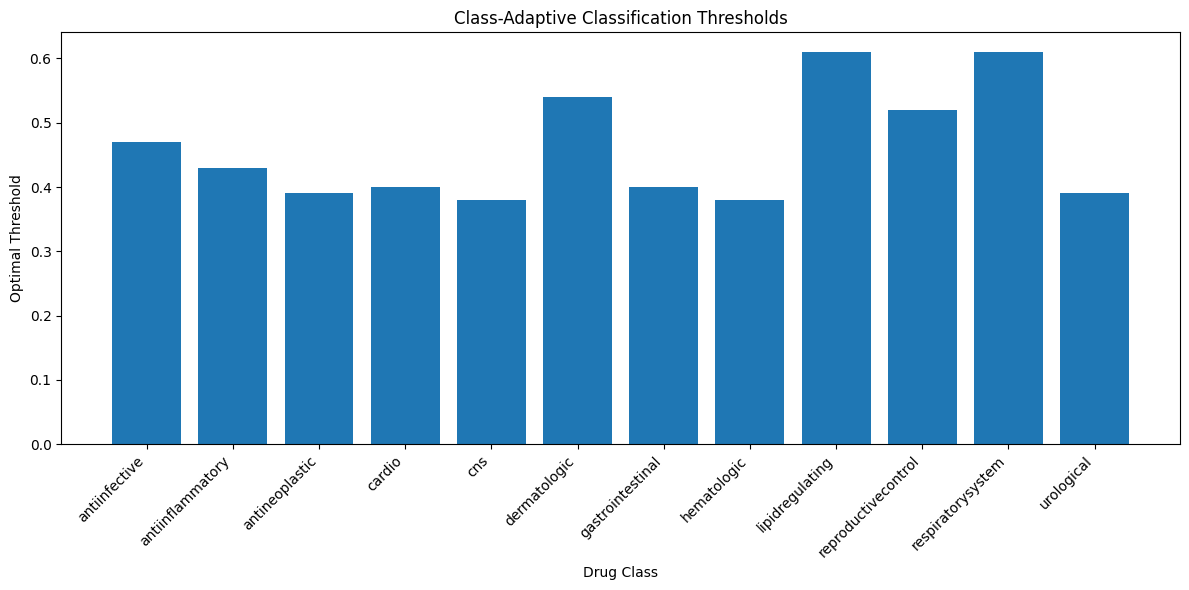

In [291]:
# ============================================================
# CELL 22 — CLASS-SPECIFIC THRESHOLDS
# ============================================================

plt.figure(figsize=(12, 6))

plt.bar(
    threshold_table["Label"],
    threshold_table["Threshold"]
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.ylabel("Optimal Threshold")
plt.xlabel("Drug Class")

plt.title(
    "Class-Adaptive Classification Thresholds"
)

plt.tight_layout()

plt.show()

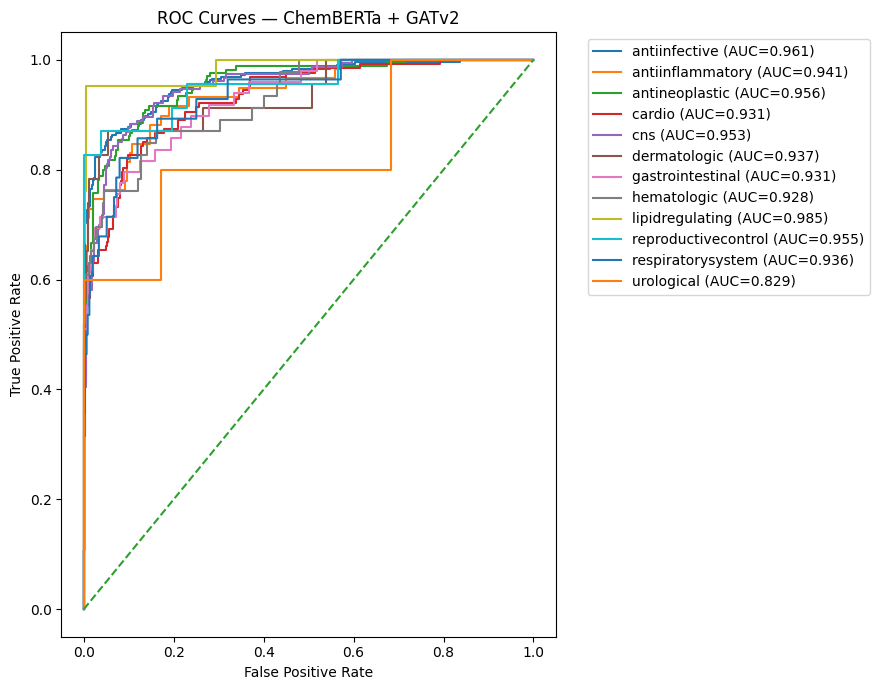

In [292]:
# ============================================================
# CELL 23 — ROC CURVES
# ============================================================

from sklearn.metrics import roc_curve
from sklearn.preprocessing import label_binarize

plt.figure(figsize=(9, 7))

for i, label in enumerate(mlb.classes_):

    try:

        fpr, tpr, _ = roc_curve(
            test_true[:, i],
            test_probabilities[:, i]
        )

        auc = roc_auc_score(
            test_true[:, i],
            test_probabilities[:, i]
        )

        plt.plot(
            fpr,
            tpr,
            label=f"{label} (AUC={auc:.3f})"
        )

    except ValueError:
        continue

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curves — ChemBERTa + GATv2"
)

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()

plt.show()

Device: cuda
GPU: NVIDIA A100-SXM4-40GB
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset exists: True
Original shape: (8336, 4)
Columns: ['image_name', 'tags', 'smiles', 'Col3']


,image_name,tags,smiles,Col3
0,pics/0,dermatologic,CC(=O)NC1C(O)OC(CO)C(O)C1O,['dermatologic']
1,pics/1,antiinfective,CCC[C@@]1(CCc2ccccc2)CC(O)=C([C@H](CC)c2cccc(N...,['antiinfective']
2,pics/2,antiinfective,CCCCC(C)C(=O)OC1C(C)C(CC)OC2(CC3CC(C/C=C(\C)CC...,['antiinfective']
3,pics/3,antineoplastic,COc1cc2c(c(OC)c1OC)-c1c(cc3c(c1OC)OCO3)C[C@H](...,['antineoplastic']
4,pics/4,antiinfective respiratorysystem,CC(=O)N[C@@H](CS)C(=O)[O-],"['antiinfective', 'respiratorysystem']"


After cleaning: (8336, 5)
Invalid SMILES: 0
Final dataset: (8336, 6)

Number of labels: 12
 0 -> antiinfective
 1 -> antiinflammatory
 2 -> antineoplastic
 3 -> cardio
 4 -> cns
 5 -> dermatologic
 6 -> gastrointestinal
 7 -> hematologic
 8 -> lipidregulating
 9 -> reproductivecontrol
10 -> respiratorysystem
11 -> urological


,Label_ID,Label,Positive_Count,Negative_Count,Percentage
0,0,antiinfective,2923,5413,35.064779
1,1,antiinflammatory,591,7745,7.089731
2,2,antineoplastic,1642,6694,19.697697
3,3,cardio,1262,7074,15.139155
4,4,cns,1528,6808,18.330134
5,5,dermatologic,226,8110,2.711132
6,6,gastrointestinal,490,7846,5.878119
7,7,hematologic,462,7874,5.542226
8,8,lipidregulating,203,8133,2.435221
9,9,reproductivecontrol,225,8111,2.699136



Train: (6673, 6) (6673, 12)
Validation: (832, 6) (832, 12)
Test: (831, 6) (831, 12)


...

,Metric,ChemBERTa + GATv2 + CrossAttention
0,Macro Precision,0.802154
1,Macro Recall,0.712992
2,Macro F1,0.749528
3,Micro F1,0.787753
4,Weighted F1,0.789416
5,Macro AUROC,0.946595
6,Micro AUROC,0.964918
7,Macro AUPRC,0.796322
8,Micro AUPRC,0.865124


,Label_ID,Label,Support,Threshold,Precision,Recall,F1
0,0,antiinfective,293.0,0.58,0.942085,0.832765,0.884058
1,1,antiinflammatory,59.0,0.31,0.681818,0.762712,0.720000
2,2,antineoplastic,165.0,0.42,0.851613,0.800000,0.825000
3,3,cardio,127.0,0.56,0.807692,0.661417,0.727273
4,4,cns,153.0,0.35,0.723529,0.803922,0.761610
5,5,dermatologic,23.0,0.69,0.842105,0.695652,0.761905
6,6,gastrointestinal,49.0,0.43,0.680851,0.653061,0.666667
7,7,hematologic,46.0,0.34,0.596154,0.673913,0.632653
8,8,lipidregulating,21.0,0.54,0.888889,0.761905,0.820513
9,9,reproductivecontrol,23.0,0.68,0.944444,0.739130,0.829268


,Metric,ChemBERTa,ChemBERTa + GATv2,ChemBERTa + GATv2 + CrossAttention
0,Macro Precision,0.648804,0.791453,0.802154
1,Macro Recall,0.537849,0.665058,0.712992
2,Macro F1,0.558966,0.714579,0.749528
3,Micro F1,0.595284,0.776025,0.787753
4,Weighted F1,0.585794,0.774276,0.789416
5,Macro AUROC,0.884098,0.938436,0.946595
6,Micro AUROC,0.908873,0.964668,0.964918
7,Macro AUPRC,0.610430,0.789712,0.796322
8,Micro AUPRC,0.611315,0.859968,0.865124


,Metric,ChemBERTa,ChemBERTa + GATv2,ChemBERTa + GATv2 + CrossAttention,Gain_vs_GATv2,Gain_%
0,Macro Precision,0.648804,0.791453,0.802154,0.010701,1.352069
1,Macro Recall,0.537849,0.665058,0.712992,0.047934,7.207510
2,Macro F1,0.558966,0.714579,0.749528,0.034949,4.890791
3,Micro F1,0.595284,0.776025,0.787753,0.011728,1.511289
4,Weighted F1,0.585794,0.774276,0.789416,0.015140,1.955439
5,Macro AUROC,0.884098,0.938436,0.946595,0.008159,0.869435
6,Micro AUROC,0.908873,0.964668,0.964918,0.000250,0.025957
7,Macro AUPRC,0.610430,0.789712,0.796322,0.006610,0.837001
8,Micro AUPRC,0.611315,0.859968,0.865124,0.005156,0.599556



All results saved to:
/content/drive/MyDrive/dataset/chemberta_gatv2_crossattention_results


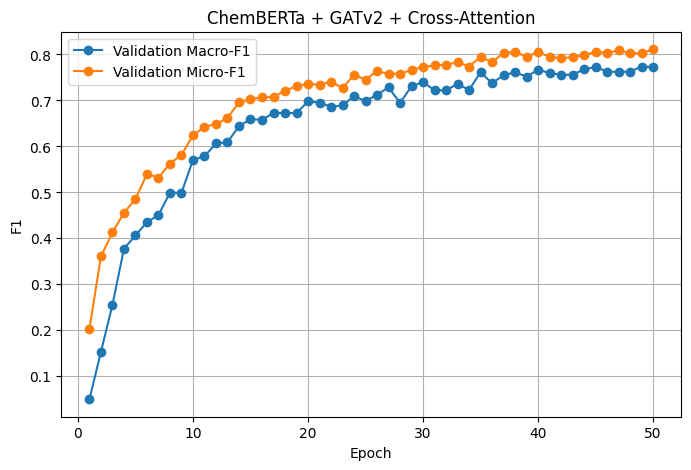

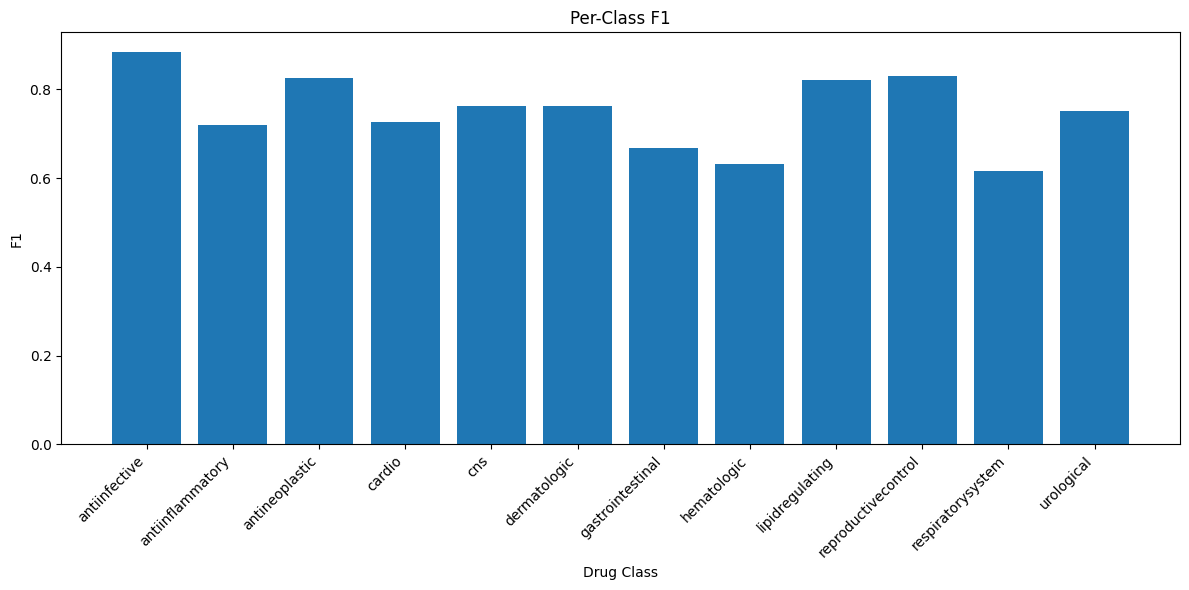


FINAL MODEL SUMMARY
Model: ChemBERTa + GATv2 + Cross-Attention
Macro Precision : 0.8022
Macro Recall    : 0.7130
Macro F1        : 0.7495
Micro F1        : 0.7878
Weighted F1     : 0.7894
Macro AUROC     : 0.9466
Micro AUROC     : 0.9649
Macro AUPRC     : 0.7963
Micro AUPRC     : 0.8651


In [293]:
# ================================================================
# COMPLETE PIPELINE
# ChemBERTa + GATv2 + Cross-Attention
# Multi-label Drug Classification from SMILES
# ================================================================

# ================================================================
# 1. INSTALL
# ================================================================

!pip install -q transformers rdkit torch-geometric iterative-stratification


# ================================================================
# 2. IMPORTS
# ================================================================

import os
import ast
import random
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

from transformers import AutoTokenizer, AutoModel

from rdkit import Chem
from rdkit.Chem import rdchem

from torch_geometric.data import Data, Batch
from torch_geometric.nn import GATv2Conv

from sklearn.preprocessing import MultiLabelBinarizer

from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score
)

from iterstrat.ml_stratifiers import (
    MultilabelStratifiedShuffleSplit
)

import matplotlib.pyplot as plt


# ================================================================
# 3. REPRODUCIBILITY
# ================================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ================================================================
# 4. GOOGLE DRIVE
# ================================================================

from google.colab import drive

drive.mount("/content/drive")

DATA_PATH = (
    "/content/drive/MyDrive/dataset/all_chem_df.csv"
)

RESULT_DIR = (
    "/content/drive/MyDrive/dataset/"
    "chemberta_gatv2_crossattention_results"
)

os.makedirs(
    RESULT_DIR,
    exist_ok=True
)

print("Dataset exists:",
      os.path.exists(DATA_PATH))


# ================================================================
# 5. LOAD DATA
# ================================================================

df = pd.read_csv(DATA_PATH)

print("Original shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())


# ================================================================
# 6. PARSE LABELS
# ================================================================

def parse_labels(value):

    if pd.isna(value):
        return []

    if isinstance(value, list):
        return value

    try:

        parsed = ast.literal_eval(str(value))

        if isinstance(parsed, list):

            return [
                str(x).strip()
                for x in parsed
                if str(x).strip()
            ]

        return [str(parsed).strip()]

    except:

        return [
            x.strip()
            for x in str(value).split(",")
            if x.strip()
        ]


df["smiles"] = (
    df["smiles"]
    .astype(str)
    .str.strip()
)

df["labels_list"] = (
    df["Col3"]
    .apply(parse_labels)
)

df = df[
    df["smiles"].notna()
].reset_index(drop=True)

df = df[
    df["labels_list"].apply(len) > 0
].reset_index(drop=True)

print("After cleaning:", df.shape)


# ================================================================
# 7. VALIDATE SMILES
# ================================================================

def is_valid_smiles(smiles):

    try:

        mol = Chem.MolFromSmiles(
            smiles
        )

        return mol is not None

    except:

        return False


df["valid"] = (
    df["smiles"]
    .apply(is_valid_smiles)
)

print(
    "Invalid SMILES:",
    (~df["valid"]).sum()
)

df = df[
    df["valid"]
].reset_index(drop=True)

print(
    "Final dataset:",
    df.shape
)


# ================================================================
# 8. MULTI-LABEL ENCODING
# ================================================================

mlb = MultiLabelBinarizer()

labels = mlb.fit_transform(
    df["labels_list"]
)

NUM_LABELS = len(
    mlb.classes_
)

print("\nNumber of labels:",
      NUM_LABELS)

for i, c in enumerate(
    mlb.classes_
):

    print(
        f"{i:2d} -> {c}"
    )


# ================================================================
# 9. CLASS DISTRIBUTION
# ================================================================

class_counts = (
    labels.sum(axis=0)
)

class_distribution = pd.DataFrame({

    "Label_ID":
        np.arange(NUM_LABELS),

    "Label":
        mlb.classes_,

    "Positive_Count":
        class_counts,

    "Negative_Count":
        len(labels) - class_counts,

    "Percentage":
        class_counts /
        len(labels) * 100
})

display(
    class_distribution
)


# ================================================================
# 10. MULTI-LABEL STRATIFIED SPLIT
# ================================================================

X = df["smiles"].values
Y = labels

splitter = (
    MultilabelStratifiedShuffleSplit(
        n_splits=1,
        test_size=0.20,
        random_state=SEED
    )
)

train_idx, temp_idx = next(
    splitter.split(X, Y)
)

temp_X = X[temp_idx]
temp_Y = Y[temp_idx]

splitter2 = (
    MultilabelStratifiedShuffleSplit(
        n_splits=1,
        test_size=0.50,
        random_state=SEED
    )
)

val_rel, test_rel = next(
    splitter2.split(
        temp_X,
        temp_Y
    )
)

val_idx = temp_idx[val_rel]
test_idx = temp_idx[test_rel]


# ================================================================
# 11. CREATE DATASETS
# ================================================================

train_df = df.iloc[
    train_idx
].reset_index(drop=True)

val_df = df.iloc[
    val_idx
].reset_index(drop=True)

test_df = df.iloc[
    test_idx
].reset_index(drop=True)

train_labels = labels[
    train_idx
]

val_labels = labels[
    val_idx
]

test_labels = labels[
    test_idx
]

print(
    "\nTrain:",
    train_df.shape,
    train_labels.shape
)

print(
    "Validation:",
    val_df.shape,
    val_labels.shape
)

print(
    "Test:",
    test_df.shape,
    test_labels.shape
)


# ================================================================
# 12. SPLIT DISTRIBUTION
# ================================================================

split_distribution = pd.DataFrame({

    "Label":
        mlb.classes_,

    "Train":
        train_labels.sum(axis=0),

    "Validation":
        val_labels.sum(axis=0),

    "Test":
        test_labels.sum(axis=0)
})

display(
    split_distribution
)


# ================================================================
# 13. CHEMBERTA
# ================================================================

MODEL_NAME = (
    "DeepChem/ChemBERTa-77M-MLM"
)

MAX_LENGTH = 128

tokenizer = (
    AutoTokenizer.from_pretrained(
        MODEL_NAME
    )
)

print(
    "ChemBERTa loaded."
)


# ================================================================
# 14. MOLECULAR GRAPH FEATURES
# ================================================================

def atom_features(atom):

    return [

        atom.GetAtomicNum(),

        atom.GetDegree(),

        atom.GetFormalCharge(),

        int(
            atom.GetIsAromatic()
        ),

        int(
            atom.GetHybridization()
        ),

        atom.GetTotalNumHs()
    ]


def bond_features(bond):

    bt = bond.GetBondType()

    return [

        float(
            bt ==
            rdchem.BondType.SINGLE
        ),

        float(
            bt ==
            rdchem.BondType.DOUBLE
        ),

        float(
            bt ==
            rdchem.BondType.TRIPLE
        ),

        float(
            bt ==
            rdchem.BondType.AROMATIC
        )
    ]


def smiles_to_graph(smiles):

    mol = Chem.MolFromSmiles(
        smiles
    )

    if mol is None:

        raise ValueError(
            "Invalid SMILES"
        )

    node_features = [

        atom_features(atom)

        for atom in mol.GetAtoms()
    ]

    x = torch.tensor(
        node_features,
        dtype=torch.float
    )

    edge_index = []
    edge_attr = []

    for bond in mol.GetBonds():

        a = bond.GetBeginAtomIdx()
        b = bond.GetEndAtomIdx()

        bf = bond_features(
            bond
        )

        edge_index.append(
            [a, b]
        )

        edge_index.append(
            [b, a]
        )

        edge_attr.append(
            bf
        )

        edge_attr.append(
            bf
        )

    if len(edge_index) == 0:

        edge_index = torch.empty(
            (2, 0),
            dtype=torch.long
        )

        edge_attr = torch.empty(
            (0, 4),
            dtype=torch.float
        )

    else:

        edge_index = torch.tensor(
            edge_index,
            dtype=torch.long
        ).t().contiguous()

        edge_attr = torch.tensor(
            edge_attr,
            dtype=torch.float
        )

    return Data(
        x=x,
        edge_index=edge_index,
        edge_attr=edge_attr
    )


# ================================================================
# 15. TEST GRAPH
# ================================================================

g = smiles_to_graph(
    train_df.iloc[0]["smiles"]
)

print(
    "Nodes:",
    g.x.shape
)

print(
    "Edges:",
    g.edge_index.shape
)


# ================================================================
# 16. DATASET
# ================================================================

class MolecularDataset(
    Dataset
):

    def __init__(
        self,
        dataframe,
        labels
    ):

        self.df = (
            dataframe
            .reset_index(drop=True)
        )

        self.labels = torch.tensor(
            labels,
            dtype=torch.float32
        )

    def __len__(self):

        return len(self.df)

    def __getitem__(self, idx):

        smiles = self.df.iloc[
            idx
        ]["smiles"]

        encoded = tokenizer(
            smiles,
            padding="max_length",
            truncation=True,
            max_length=MAX_LENGTH,
            return_tensors="pt"
        )

        graph = (
            smiles_to_graph(smiles)
        )

        return {

            "input_ids":
                encoded[
                    "input_ids"
                ].squeeze(0),

            "attention_mask":
                encoded[
                    "attention_mask"
                ].squeeze(0),

            "graph":
                graph,

            "labels":
                self.labels[idx]
        }


# ================================================================
# 17. DATASETS
# ================================================================

train_dataset = MolecularDataset(
    train_df,
    train_labels
)

val_dataset = MolecularDataset(
    val_df,
    val_labels
)

test_dataset = MolecularDataset(
    test_df,
    test_labels
)


# ================================================================
# 18. COLLATE FUNCTION
# ================================================================

def collate_fn(batch):

    input_ids = torch.stack(
        [
            x["input_ids"]
            for x in batch
        ]
    )

    attention_mask = torch.stack(
        [
            x["attention_mask"]
            for x in batch
        ]
    )

    labels_batch = torch.stack(
        [
            x["labels"]
            for x in batch
        ]
    )

    graphs = Batch.from_data_list(
        [
            x["graph"]
            for x in batch
        ]
    )

    return {

        "input_ids":
            input_ids,

        "attention_mask":
            attention_mask,

        "graph":
            graphs,

        "labels":
            labels_batch
    }


# ================================================================
# 19. DATALOADERS
# ================================================================

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=2,
    pin_memory=True
)


# ================================================================
# 20. CROSS-ATTENTION MODEL
# ================================================================

class ChemBERTaGATCrossAttention(
    nn.Module
):

    def __init__(
        self,
        num_labels,
        hidden_dim=256,
        heads=4,
        dropout=0.20
    ):

        super().__init__()

        # --------------------------------------------------------
        # ChemBERTa
        # --------------------------------------------------------

        self.chemberta = (
            AutoModel.from_pretrained(
                MODEL_NAME
            )
        )

        bert_dim = (
            self.chemberta
            .config
            .hidden_size
        )

        self.bert_projection = (
            nn.Linear(
                bert_dim,
                hidden_dim
            )
        )

        # --------------------------------------------------------
        # GATv2
        # --------------------------------------------------------

        self.gat1 = GATv2Conv(
            6,
            hidden_dim,
            heads=heads,
            concat=False,
            dropout=dropout
        )

        self.gat2 = GATv2Conv(
            hidden_dim,
            hidden_dim,
            heads=heads,
            concat=False,
            dropout=dropout
        )

        # --------------------------------------------------------
        # Graph -> sequence token space
        # --------------------------------------------------------

        self.graph_projection = (
            nn.Linear(
                hidden_dim,
                hidden_dim
            )
        )

        # --------------------------------------------------------
        # Cross Attention
        #
        # Query  = ChemBERTa tokens
        # Key    = graph representation
        # Value  = graph representation
        # --------------------------------------------------------

        self.cross_attention = (
            nn.MultiheadAttention(
                embed_dim=hidden_dim,
                num_heads=heads,
                dropout=dropout,
                batch_first=True
            )
        )

        self.attention_norm = (
            nn.LayerNorm(
                hidden_dim
            )
        )

        # --------------------------------------------------------
        # Feed Forward
        # --------------------------------------------------------

        self.ffn = nn.Sequential(

            nn.Linear(
                hidden_dim,
                hidden_dim * 2
            ),

            nn.GELU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                hidden_dim * 2,
                hidden_dim
            )
        )

        self.ffn_norm = (
            nn.LayerNorm(
                hidden_dim
            )
        )

        # --------------------------------------------------------
        # Fusion
        # --------------------------------------------------------

        self.fusion = nn.Sequential(

            nn.Linear(
                hidden_dim * 2,
                hidden_dim
            ),

            nn.LayerNorm(
                hidden_dim
            ),

            nn.GELU(),

            nn.Dropout(
                dropout
            )
        )

        # --------------------------------------------------------
        # Classification
        # --------------------------------------------------------

        self.classifier = nn.Sequential(

            nn.Linear(
                hidden_dim,
                hidden_dim // 2
            ),

            nn.GELU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                hidden_dim // 2,
                num_labels
            )
        )

    def forward(
        self,
        input_ids,
        attention_mask,
        graph
    ):

        # ========================================================
        # CHEMBERTA TOKEN REPRESENTATION
        # ========================================================

        bert_output = self.chemberta(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        token_features = (
            self.bert_projection(
                bert_output.last_hidden_state
            )
        )

        # ========================================================
        # MOLECULAR GRAPH
        # ========================================================

        x = graph.x

        x = self.gat1(
            x,
            graph.edge_index
        )

        x = F.gelu(x)

        x = self.gat2(
            x,
            graph.edge_index
        )

        x = F.gelu(x)

        # ========================================================
        # CREATE GRAPH REPRESENTATION
        # ========================================================

        # Number of molecules in batch
        batch_size = (
            input_ids.size(0)
        )

        graph_sequences = []

        for i in range(batch_size):

            molecule_nodes = (
                x[graph.batch == i]
            )

            graph_sequences.append(
                molecule_nodes
            )

        # Pad graph node sequences
        max_nodes = max(
            g.size(0)
            for g in graph_sequences
        )

        padded_graph = []

        graph_padding_mask = []

        for g in graph_sequences:

            n = g.size(0)

            if n < max_nodes:

                padding = torch.zeros(
                    max_nodes - n,
                    g.size(1),
                    device=g.device
                )

                g_padded = torch.cat(
                    [
                        g,
                        padding
                    ],
                    dim=0
                )

                mask = torch.cat(
                    [
                        torch.zeros(
                            n,
                            dtype=torch.bool,
                            device=g.device
                        ),

                        torch.ones(
                            max_nodes - n,
                            dtype=torch.bool,
                            device=g.device
                        )
                    ]
                )

            else:

                g_padded = g

                mask = torch.zeros(
                    max_nodes,
                    dtype=torch.bool,
                    device=g.device
                )

            padded_graph.append(
                g_padded
            )

            graph_padding_mask.append(
                mask
            )

        graph_sequence = torch.stack(
            padded_graph
        )

        graph_padding_mask = torch.stack(
            graph_padding_mask
        )

        graph_sequence = (
            self.graph_projection(
                graph_sequence
            )
        )

        # ========================================================
        # CROSS ATTENTION
        # ========================================================

        attended, attention_weights = (
            self.cross_attention(

                query=token_features,

                key=graph_sequence,

                value=graph_sequence,

                key_padding_mask=
                    graph_padding_mask
            )
        )

        # Residual connection
        token_features = (
            token_features
            +
            attended
        )

        token_features = (
            self.attention_norm(
                token_features
            )
        )

        # ========================================================
        # FEED FORWARD
        # ========================================================

        token_features = (
            token_features
            +
            self.ffn(
                token_features
            )
        )

        token_features = (
            self.ffn_norm(
                token_features
            )
        )

        # ========================================================
        # ATTENTION MASKED MEAN POOLING
        # ========================================================

        mask = (
            attention_mask
            .unsqueeze(-1)
            .float()
        )

        bert_fused = (
            token_features * mask
        ).sum(dim=1)

        bert_fused = (
            bert_fused /
            mask.sum(dim=1)
            .clamp(min=1e-6)
        )

        # ========================================================
        # GRAPH GLOBAL REPRESENTATION
        # ========================================================

        graph_pooled = []

        for i in range(batch_size):

            molecule_nodes = (
                x[graph.batch == i]
            )

            graph_pooled.append(
                molecule_nodes.mean(
                    dim=0
                )
            )

        graph_pooled = torch.stack(
            graph_pooled
        )

        # ========================================================
        # FUSION
        # ========================================================

        combined = torch.cat(
            [
                bert_fused,
                graph_pooled
            ],
            dim=1
        )

        fused = self.fusion(
            combined
        )

        # ========================================================
        # CLASSIFICATION
        # ========================================================

        logits = self.classifier(
            fused
        )

        return logits


# ================================================================
# 21. CREATE MODEL
# ================================================================

model = ChemBERTaGATCrossAttention(
    num_labels=NUM_LABELS,
    hidden_dim=256,
    heads=4,
    dropout=0.20
)

model = model.to(device)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(
    "Total parameters:",
    total_params
)

print(
    "Trainable parameters:",
    trainable_params
)


# ================================================================
# 22. CLASS WEIGHTS
# ================================================================

counts = (
    train_labels.sum(axis=0)
)

beta = 0.999

effective_weights = (
    (1 - beta)
    /
    (
        1 -
        np.power(
            beta,
            counts
        )
    )
)

effective_weights = (
    effective_weights /
    effective_weights.mean()
)

effective_weights = np.clip(
    effective_weights,
    0.5,
    10.0
)

class_weights = torch.tensor(
    effective_weights,
    dtype=torch.float32
).to(device)

weight_table = pd.DataFrame({

    "Label":
        mlb.classes_,

    "Count":
        counts,

    "Weight":
        effective_weights
})

display(weight_table)


# ================================================================
# 23. FOCAL BCE LOSS
# ================================================================

class FocalBCELoss(
    nn.Module
):

    def __init__(
        self,
        pos_weight,
        gamma=2.0
    ):

        super().__init__()

        self.pos_weight = (
            pos_weight
        )

        self.gamma = gamma

    def forward(
        self,
        logits,
        targets
    ):

        bce = (
            F.binary_cross_entropy_with_logits(
                logits,
                targets,
                pos_weight=self.pos_weight,
                reduction="none"
            )
        )

        probabilities = (
            torch.sigmoid(
                logits
            )
        )

        pt = (
            targets * probabilities
            +
            (1 - targets)
            *
            (1 - probabilities)
        )

        focal_weight = (
            (1 - pt)
            .pow(self.gamma)
        )

        return (
            focal_weight * bce
        ).mean()


criterion = FocalBCELoss(
    class_weights,
    gamma=2.0
)


# ================================================================
# 24. DIFFERENTIAL LEARNING RATES
# ================================================================

bert_params = []
new_params = []

for name, parameter in (
        model.named_parameters()):

    if name.startswith(
        "chemberta."
    ):

        bert_params.append(
            parameter
        )

    else:

        new_params.append(
            parameter
        )

optimizer = torch.optim.AdamW(

    [
        {
            "params":
                bert_params,
            "lr":
                1e-5
        },

        {
            "params":
                new_params,
            "lr":
                2e-4
        }
    ],

    weight_decay=1e-4
)


# ================================================================
# 25. TRAINING FUNCTION
# ================================================================

def train_one_epoch():

    model.train()

    total_loss = 0
    total_samples = 0

    for batch in train_loader:

        input_ids = batch[
            "input_ids"
        ].to(device)

        attention_mask = batch[
            "attention_mask"
        ].to(device)

        graph = batch[
            "graph"
        ].to(device)

        labels_batch = batch[
            "labels"
        ].to(device)

        optimizer.zero_grad(
            set_to_none=True
        )

        logits = model(
            input_ids,
            attention_mask,
            graph
        )

        loss = criterion(
            logits,
            labels_batch
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            1.0
        )

        optimizer.step()

        bs = (
            labels_batch.size(0)
        )

        total_loss += (
            loss.item() * bs
        )

        total_samples += bs

    return (
        total_loss /
        total_samples
    )


# ================================================================
# 26. PREDICTION FUNCTION
# ================================================================

@torch.no_grad()
def predict(loader):

    model.eval()

    probabilities = []
    true_labels = []

    for batch in loader:

        input_ids = batch[
            "input_ids"
        ].to(device)

        attention_mask = batch[
            "attention_mask"
        ].to(device)

        graph = batch[
            "graph"
        ].to(device)

        labels_batch = batch[
            "labels"
        ].to(device)

        logits = model(
            input_ids,
            attention_mask,
            graph
        )

        probs = torch.sigmoid(
            logits
        )

        probabilities.append(
            probs.cpu().numpy()
        )

        true_labels.append(
            labels_batch.cpu().numpy()
        )

    return (
        np.concatenate(
            probabilities
        ),
        np.concatenate(
            true_labels
        )
    )


# ================================================================
# 27. TRAIN
# ================================================================

EPOCHS = 50

BEST_PATH = os.path.join(
    RESULT_DIR,
    "best_model.pt"
)

best_f1 = -1

history = []

for epoch in range(
    EPOCHS
):

    train_loss = (
        train_one_epoch()
    )

    val_prob, val_true = (
        predict(val_loader)
    )

    val_pred = (
        val_prob >= 0.5
    ).astype(int)

    val_macro_f1 = (
        f1_score(
            val_true,
            val_pred,
            average="macro",
            zero_division=0
        )
    )

    val_micro_f1 = (
        f1_score(
            val_true,
            val_pred,
            average="micro",
            zero_division=0
        )
    )

    history.append({

        "Epoch":
            epoch + 1,

        "Train Loss":
            train_loss,

        "Validation Macro F1":
            val_macro_f1,

        "Validation Micro F1":
            val_micro_f1
    })

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Loss={train_loss:.4f} | "
        f"Macro-F1={val_macro_f1:.4f} | "
        f"Micro-F1={val_micro_f1:.4f}"
    )

    if val_macro_f1 > best_f1:

        best_f1 = (
            val_macro_f1
        )

        torch.save(
            model.state_dict(),
            BEST_PATH
        )

        print(
            "  ✓ Best model saved"
        )


# ================================================================
# 28. LOAD BEST MODEL
# ================================================================

model.load_state_dict(
    torch.load(
        BEST_PATH,
        map_location=device
    )
)

model.to(device)

print(
    "\nBest validation Macro-F1:",
    best_f1
)


# ================================================================
# 29. FINAL VALIDATION PREDICTIONS
# ================================================================

val_prob, val_true = (
    predict(val_loader)
)


# ================================================================
# 30. OPTIMIZE CLASS-SPECIFIC THRESHOLDS
# ================================================================

def optimize_thresholds(
    y_true,
    probabilities
):

    thresholds = np.arange(
        0.10,
        0.91,
        0.01
    )

    best_thresholds = []
    best_f1s = []

    for c in range(
        y_true.shape[1]
    ):

        best_score = -1
        best_threshold = 0.50

        for threshold in thresholds:

            pred = (
                probabilities[:, c]
                >= threshold
            ).astype(int)

            score = f1_score(
                y_true[:, c],
                pred,
                zero_division=0
            )

            if score > best_score:

                best_score = score

                best_threshold = (
                    threshold
                )

        best_thresholds.append(
            best_threshold
        )

        best_f1s.append(
            best_score
        )

    return (
        np.array(best_thresholds),
        np.array(best_f1s)
    )


best_thresholds, val_class_f1 = (
    optimize_thresholds(
        val_true,
        val_prob
    )
)


# ================================================================
# 31. THRESHOLD TABLE
# ================================================================

threshold_table = pd.DataFrame({

    "Label_ID":
        np.arange(NUM_LABELS),

    "Label":
        mlb.classes_,

    "Support":
        val_true.sum(axis=0),

    "Threshold":
        best_thresholds,

    "Validation_F1":
        val_class_f1
})

display(
    threshold_table
)


# ================================================================
# 32. OPTIMIZED VALIDATION METRICS
# ================================================================

val_optimized_pred = np.zeros_like(
    val_prob,
    dtype=int
)

for c in range(
    NUM_LABELS
):

    val_optimized_pred[:, c] = (
        val_prob[:, c]
        >= best_thresholds[c]
    ).astype(int)


print("\nVALIDATION RESULTS")
print("=" * 60)

print(
    "Macro Precision:",
    precision_score(
        val_true,
        val_optimized_pred,
        average="macro",
        zero_division=0
    )
)

print(
    "Macro Recall:",
    recall_score(
        val_true,
        val_optimized_pred,
        average="macro",
        zero_division=0
    )
)

print(
    "Macro F1:",
    f1_score(
        val_true,
        val_optimized_pred,
        average="macro",
        zero_division=0
    )
)

print(
    "Micro F1:",
    f1_score(
        val_true,
        val_optimized_pred,
        average="micro",
        zero_division=0
    )
)


# ================================================================
# 33. FINAL TEST PREDICTIONS
# ================================================================

test_prob, test_true = (
    predict(test_loader)
)

test_pred = np.zeros_like(
    test_prob,
    dtype=int
)

# IMPORTANT:
# Thresholds were learned ONLY from validation data.

for c in range(
    NUM_LABELS
):

    test_pred[:, c] = (
        test_prob[:, c]
        >= best_thresholds[c]
    ).astype(int)


# ================================================================
# 34. TEST METRICS
# ================================================================

test_macro_precision = (
    precision_score(
        test_true,
        test_pred,
        average="macro",
        zero_division=0
    )
)

test_macro_recall = (
    recall_score(
        test_true,
        test_pred,
        average="macro",
        zero_division=0
    )
)

test_macro_f1 = (
    f1_score(
        test_true,
        test_pred,
        average="macro",
        zero_division=0
    )
)

test_micro_f1 = (
    f1_score(
        test_true,
        test_pred,
        average="micro",
        zero_division=0
    )
)

test_weighted_f1 = (
    f1_score(
        test_true,
        test_pred,
        average="weighted",
        zero_division=0
    )
)

test_macro_auroc = (
    roc_auc_score(
        test_true,
        test_prob,
        average="macro"
    )
)

test_micro_auroc = (
    roc_auc_score(
        test_true,
        test_prob,
        average="micro"
    )
)

test_macro_auprc = (
    average_precision_score(
        test_true,
        test_prob,
        average="macro"
    )
)

test_micro_auprc = (
    average_precision_score(
        test_true,
        test_prob,
        average="micro"
    )
)


# ================================================================
# 35. FINAL RESULTS
# ================================================================

final_metrics = pd.DataFrame({

    "Metric": [

        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Micro F1",
        "Weighted F1",
        "Macro AUROC",
        "Micro AUROC",
        "Macro AUPRC",
        "Micro AUPRC"
    ],

    "ChemBERTa + GATv2 + CrossAttention": [

        test_macro_precision,
        test_macro_recall,
        test_macro_f1,
        test_micro_f1,
        test_weighted_f1,
        test_macro_auroc,
        test_micro_auroc,
        test_macro_auprc,
        test_micro_auprc
    ]
})

display(
    final_metrics
)


# ================================================================
# 36. PER-CLASS TEST METRICS
# ================================================================

precision_per_class = (
    precision_score(
        test_true,
        test_pred,
        average=None,
        zero_division=0
    )
)

recall_per_class = (
    recall_score(
        test_true,
        test_pred,
        average=None,
        zero_division=0
    )
)

f1_per_class = (
    f1_score(
        test_true,
        test_pred,
        average=None,
        zero_division=0
    )
)

per_class = pd.DataFrame({

    "Label_ID":
        np.arange(NUM_LABELS),

    "Label":
        mlb.classes_,

    "Support":
        test_true.sum(axis=0),

    "Threshold":
        best_thresholds,

    "Precision":
        precision_per_class,

    "Recall":
        recall_per_class,

    "F1":
        f1_per_class
})

display(
    per_class
)


# ================================================================
# 37. COMPARE ALL THREE MODELS
# ================================================================

comparison = pd.DataFrame({

    "Metric": [

        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Micro F1",
        "Weighted F1",
        "Macro AUROC",
        "Micro AUROC",
        "Macro AUPRC",
        "Micro AUPRC"
    ],

    "ChemBERTa": [

        0.648804,
        0.537849,
        0.558966,
        0.595284,
        0.585794,
        0.884098,
        0.908873,
        0.610430,
        0.611315
    ],

    "ChemBERTa + GATv2": [

        0.791453,
        0.665058,
        0.714579,
        0.776025,
        0.774276,
        0.938436,
        0.964668,
        0.789712,
        0.859968
    ],

    "ChemBERTa + GATv2 + CrossAttention": [

        test_macro_precision,
        test_macro_recall,
        test_macro_f1,
        test_micro_f1,
        test_weighted_f1,
        test_macro_auroc,
        test_micro_auroc,
        test_macro_auprc,
        test_micro_auprc
    ]
})

display(
    comparison
)


# ================================================================
# 38. IMPROVEMENT OVER GATv2
# ================================================================

comparison["Gain_vs_GATv2"] = (
    comparison[
        "ChemBERTa + GATv2 + CrossAttention"
    ]
    -
    comparison[
        "ChemBERTa + GATv2"
    ]
)

comparison["Gain_%"] = (
    comparison["Gain_vs_GATv2"]
    /
    comparison[
        "ChemBERTa + GATv2"
    ]
    * 100
)

display(
    comparison
)


# ================================================================
# 39. SAVE RESULTS
# ================================================================

pd.DataFrame(
    history
).to_csv(
    os.path.join(
        RESULT_DIR,
        "training_history.csv"
    ),
    index=False
)

threshold_table.to_csv(
    os.path.join(
        RESULT_DIR,
        "thresholds.csv"
    ),
    index=False
)

per_class.to_csv(
    os.path.join(
        RESULT_DIR,
        "per_class_results.csv"
    ),
    index=False
)

final_metrics.to_csv(
    os.path.join(
        RESULT_DIR,
        "final_metrics.csv"
    ),
    index=False
)

comparison.to_csv(
    os.path.join(
        RESULT_DIR,
        "model_comparison.csv"
    ),
    index=False
)

print(
    "\nAll results saved to:"
)

print(
    RESULT_DIR
)


# ================================================================
# 40. TRAINING CURVE
# ================================================================

history_df = pd.DataFrame(
    history
)

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    history_df["Epoch"],
    history_df["Validation Macro F1"],
    marker="o",
    label="Validation Macro-F1"
)

plt.plot(
    history_df["Epoch"],
    history_df["Validation Micro F1"],
    marker="o",
    label="Validation Micro-F1"
)

plt.xlabel("Epoch")
plt.ylabel("F1")

plt.title(
    "ChemBERTa + GATv2 + Cross-Attention"
)

plt.legend()

plt.grid(True)

plt.show()


# ================================================================
# 41. PER-CLASS F1
# ================================================================

plt.figure(
    figsize=(12, 6)
)

plt.bar(
    per_class["Label"],
    per_class["F1"]
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.ylabel("F1")

plt.xlabel("Drug Class")

plt.title(
    "Per-Class F1"
)

plt.tight_layout()

plt.show()


# ================================================================
# 42. FINAL SUMMARY
# ================================================================

print("\n" + "=" * 75)
print("FINAL MODEL SUMMARY")
print("=" * 75)

print(
    "Model: ChemBERTa + GATv2 + Cross-Attention"
)

print(
    f"Macro Precision : {test_macro_precision:.4f}"
)

print(
    f"Macro Recall    : {test_macro_recall:.4f}"
)

print(
    f"Macro F1        : {test_macro_f1:.4f}"
)

print(
    f"Micro F1        : {test_micro_f1:.4f}"
)

print(
    f"Weighted F1     : {test_weighted_f1:.4f}"
)

print(
    f"Macro AUROC     : {test_macro_auroc:.4f}"
)

print(
    f"Micro AUROC     : {test_micro_auroc:.4f}"
)

print(
    f"Macro AUPRC     : {test_macro_auprc:.4f}"
)

print(
    f"Micro AUPRC     : {test_micro_auprc:.4f}"
)

print("=" * 75)

All required objects are available.

SMILES:
CCCCC(C)C(=O)OC1C(C)C(CC)OC2(CC3CC(C/C=C(\C)CC(C)/C=C/C=C4\COC5C(O)C(C)=CC(C(=O)O3)C45O)O2)C1O

TRUE LABELS:
['antiinfective']

PREDICTED LABELS:
['antiinfective']


,Label_ID,Drug_Class,Probability,Threshold,Predicted,True
0,0,antiinfective,0.970935,0.58,1,1.0
1,4,cns,0.030709,0.35,0,0.0
2,3,cardio,0.022689,0.56,0,0.0
3,2,antineoplastic,0.014938,0.42,0,0.0
4,8,lipidregulating,0.011412,0.54,0,0.0
5,1,antiinflammatory,0.009979,0.31,0,0.0
6,6,gastrointestinal,0.004589,0.43,0,0.0
7,5,dermatologic,0.002586,0.69,0,0.0
8,7,hematologic,0.002386,0.34,0,0.0
9,10,respiratorysystem,0.000998,0.42,0,0.0


Number of atoms: 49
Number of bonds: 53
Input shape: torch.Size([1, 128])
Token representation: torch.Size([1, 128, 256])
Graph representation: torch.Size([1, 49, 256])
Attention shape: torch.Size([1, 128, 49])

Most important ChemBERTa tokens:


,Token,Importance
0,),0.843522
1,),0.841229
2,C,0.836143
3,C,0.831765
4,C,0.829292
5,C,0.828186
6,C,0.827965
7,),0.826280
8,\,0.825366
9,/,0.825190


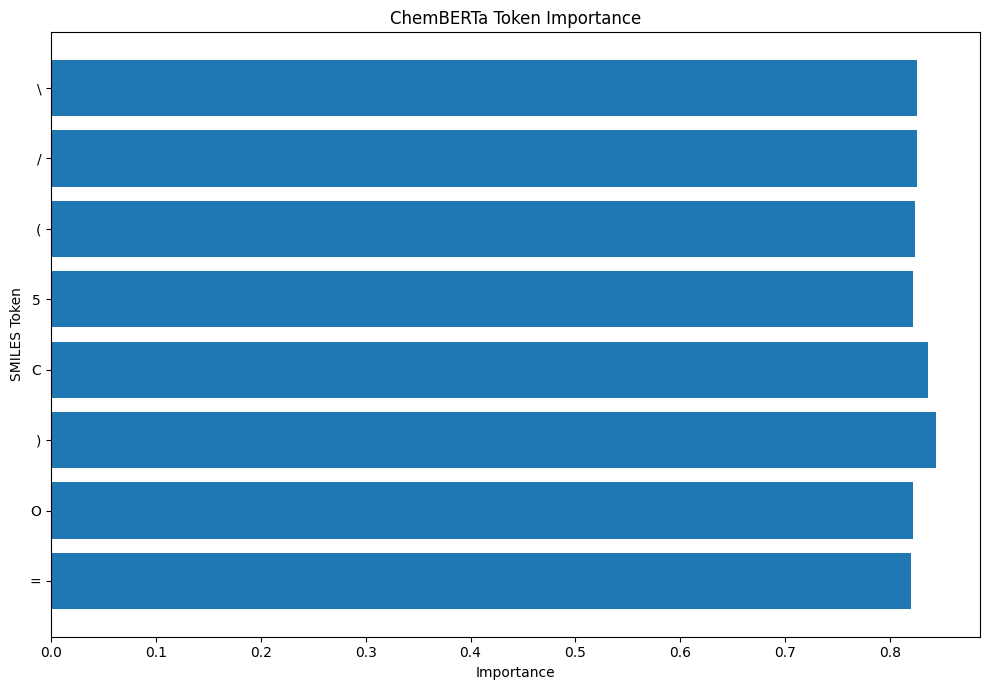


Most important molecular atoms:


,Atom_Index,Element,Importance
0,0,C,0.008123
1,2,C,0.008082
2,11,C,0.008061
3,1,C,0.008061
4,14,C,0.008053
5,3,C,0.007801
6,5,C,0.007489
7,27,C,0.007370
8,39,C,0.006969
9,7,O,0.006841


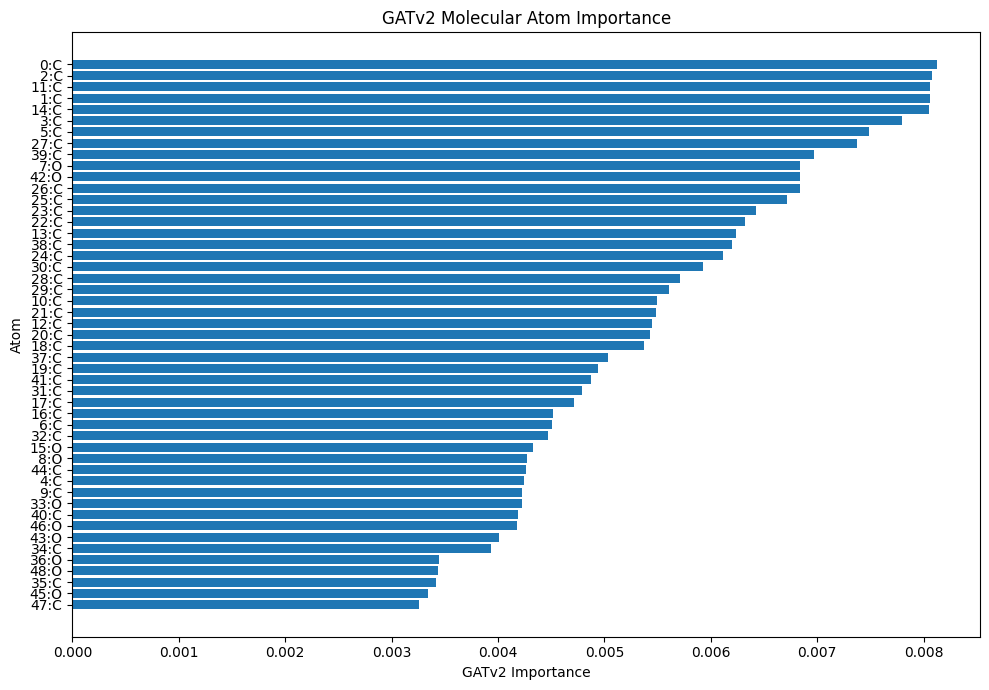

Cross-attention matrix: (128, 49)
Valid token-atom matrix: (96, 49)


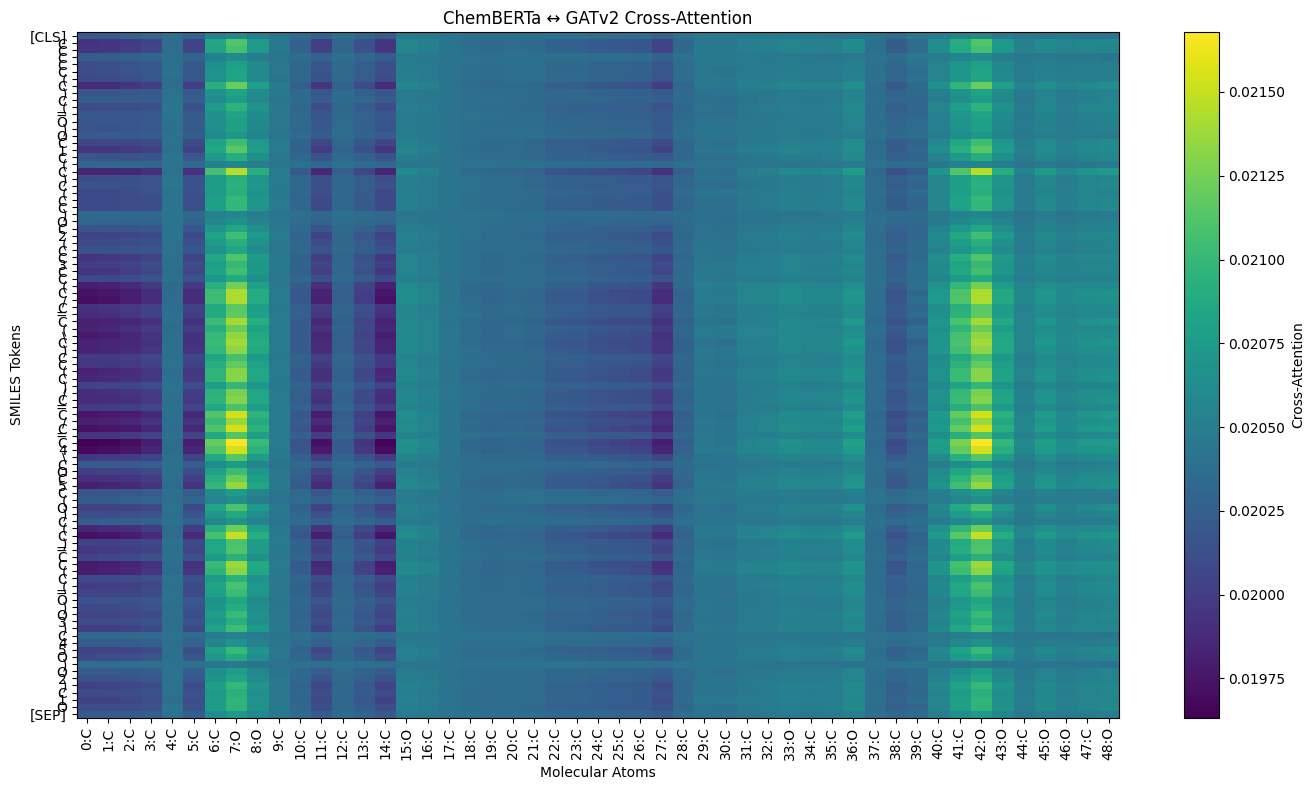


Strongest Token-Atom interactions:


,Token,Atom,Element,Attention
0,C,42,O,0.021678
1,C,7,O,0.021678
2,C,7,O,0.021548
3,C,42,O,0.021548
4,C,7,O,0.021548
5,C,42,O,0.021548
6,4,7,O,0.021545
7,4,42,O,0.021545
8,C,42,O,0.021496
9,C,7,O,0.021496



Molecular structure:


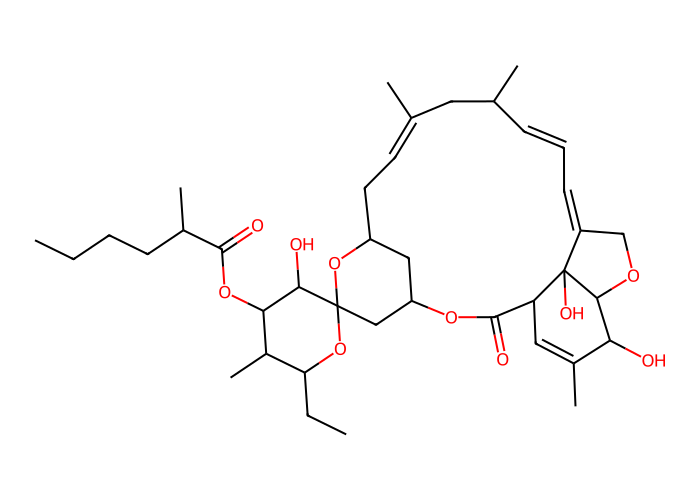


Worst prediction cases:


,Index,True_Labels,Predicted_Labels,True_Positive_Count,False_Positive_Count,False_Negative_Count,Error_Score
732,732,"antiinfective, respiratorysystem, cardio, hema...",cns,0,1,4,5
806,806,"antiinfective, antineoplastic, cardio","cns, hematologic",0,2,3,5
282,282,"antiinfective, antineoplastic, cardio, hematol...",hematologic,1,0,4,4
332,332,"antiinflammatory, cardio, gastrointestinal, he...",,0,0,4,4
756,756,"cardio, hematologic","antineoplastic, cns",0,2,2,4
576,576,"cardio, hematologic","antiinflammatory, cns",0,2,2,4
753,753,"respiratorysystem, cns",antiinfective,0,1,2,3
759,759,"antiinflammatory, antineoplastic, cardio, hema...",antiinflammatory,1,0,3,3
251,251,"cardio, hematologic",antineoplastic,0,1,2,3
329,329,cardio,"antiinfective, antineoplastic",0,2,1,3


,Label_ID,Label,TP,FP,FN,Support,F1
0,0,antiinfective,244,15,49,293.0,0.884058
1,1,antiinflammatory,45,21,14,59.0,0.720000
2,2,antineoplastic,132,23,33,165.0,0.825000
3,3,cardio,84,20,43,127.0,0.727273
4,4,cns,123,47,30,153.0,0.761610
5,5,dermatologic,16,3,7,23.0,0.761905
6,6,gastrointestinal,32,15,17,49.0,0.666667
7,7,hematologic,31,21,15,46.0,0.632653
8,8,lipidregulating,16,2,5,21.0,0.820513
9,9,reproductivecontrol,17,1,6,23.0,0.829268




EXPLAINABILITY AND ERROR ANALYSIS COMPLETED
Model:
ChemBERTa + GATv2 + Cross-Attention

Test Macro-F1: 0.7495
Test Micro-F1: 0.7878

Generated:
1. ChemBERTa token importance
2. GATv2 atom importance
3. Token-atom cross-attention
4. Prediction error analysis
5. Class-wise TP/FP/FN analysis

Results directory:
/content/drive/MyDrive/dataset/chemberta_gatv2_crossattention_results


In [294]:
# ================================================================
# NEXT STEP
# EXPLAINABILITY + ERROR ANALYSIS
# ChemBERTa + GATv2 + Cross-Attention
# ================================================================

import os
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from rdkit import Chem
from rdkit.Chem import Draw

from IPython.display import display, Image


# ================================================================
# 1. CHECK REQUIRED OBJECTS
# ================================================================

required_objects = [
    "model",
    "tokenizer",
    "test_df",
    "test_true",
    "test_prob",
    "test_pred",
    "best_thresholds",
    "mlb"
]

missing = [
    x for x in required_objects
    if x not in globals()
]

if len(missing) > 0:

    raise RuntimeError(
        "Missing objects: " +
        ", ".join(missing)
    )

print("All required objects are available.")


# ================================================================
# 2. SELECT A TEST MOLECULE
# ================================================================

sample_index = 0

sample_smiles = test_df.iloc[
    sample_index
]["smiles"]

sample_true = test_true[
    sample_index
]

sample_prob = test_prob[
    sample_index
]

sample_pred = test_pred[
    sample_index
]

print("\nSMILES:")
print(sample_smiles)

print("\nTRUE LABELS:")

true_labels = [
    mlb.classes_[i]
    for i in range(len(mlb.classes_))
    if sample_true[i] == 1
]

print(true_labels)

print("\nPREDICTED LABELS:")

pred_labels = [
    mlb.classes_[i]
    for i in range(len(mlb.classes_))
    if sample_pred[i] == 1
]

print(pred_labels)


# ================================================================
# 3. DISPLAY CLASS PROBABILITIES
# ================================================================

probability_table = pd.DataFrame({

    "Label_ID":
        np.arange(len(mlb.classes_)),

    "Drug_Class":
        mlb.classes_,

    "Probability":
        sample_prob,

    "Threshold":
        best_thresholds,

    "Predicted":
        sample_pred,

    "True":
        sample_true
})

probability_table = (
    probability_table
    .sort_values(
        "Probability",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    probability_table
)


# ================================================================
# 4. CREATE GRAPH
# ================================================================

def smiles_to_graph_explain(smiles):

    mol = Chem.MolFromSmiles(
        smiles
    )

    if mol is None:

        raise ValueError(
            "Invalid SMILES"
        )

    node_features = []

    for atom in mol.GetAtoms():

        node_features.append([

            atom.GetAtomicNum(),

            atom.GetDegree(),

            atom.GetFormalCharge(),

            int(
                atom.GetIsAromatic()
            ),

            int(
                atom.GetHybridization()
            ),

            atom.GetTotalNumHs()

        ])

    x = torch.tensor(
        node_features,
        dtype=torch.float32
    )

    edge_index = []

    for bond in mol.GetBonds():

        a = bond.GetBeginAtomIdx()
        b = bond.GetEndAtomIdx()

        edge_index.append(
            [a, b]
        )

        edge_index.append(
            [b, a]
        )

    if len(edge_index) == 0:

        edge_index = torch.empty(
            (2, 0),
            dtype=torch.long
        )

    else:

        edge_index = torch.tensor(
            edge_index,
            dtype=torch.long
        ).t().contiguous()

    return mol, x, edge_index


mol, graph_x, graph_edge_index = (
    smiles_to_graph_explain(
        sample_smiles
    )
)

print(
    "Number of atoms:",
    mol.GetNumAtoms()
)

print(
    "Number of bonds:",
    mol.GetNumBonds()
)


# ================================================================
# 5. PREPARE CHEMBERTA INPUT
# ================================================================

encoded = tokenizer(
    sample_smiles,
    padding="max_length",
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

input_ids = encoded[
    "input_ids"
].to(device)

attention_mask = encoded[
    "attention_mask"
].to(device)

print(
    "Input shape:",
    input_ids.shape
)


# ================================================================
# 6. PREPARE GRAPH
# ================================================================

from torch_geometric.data import Data

graph = Data(

    x=graph_x,

    edge_index=
        graph_edge_index

).to(device)

# Required batch vector
graph.batch = torch.zeros(
    graph.x.size(0),
    dtype=torch.long,
    device=device
)


# ================================================================
# 7. MODIFY MODEL TO RETURN INTERMEDIATE REPRESENTATIONS
# ================================================================

# We manually reproduce the forward process
# so that intermediate representations can be extracted.

model.eval()

with torch.no_grad():

    # ------------------------------------------------------------
    # ChemBERTa
    # ------------------------------------------------------------

    bert_output = model.chemberta(
        input_ids=input_ids,
        attention_mask=attention_mask
    )

    token_features = (
        model.bert_projection(
            bert_output.last_hidden_state
        )
    )

    # ------------------------------------------------------------
    # GATv2
    # ------------------------------------------------------------

    x = graph.x

    gat1_output = model.gat1(
        x,
        graph.edge_index
    )

    gat1_output = F.gelu(
        gat1_output
    )

    gat2_output = model.gat2(
        gat1_output,
        graph.edge_index
    )

    graph_node_features = F.gelu(
        gat2_output
    )

    # ------------------------------------------------------------
    # Graph projection
    # ------------------------------------------------------------

    graph_sequence = (
        model.graph_projection(
            graph_node_features
        )
    )

    graph_sequence = (
        graph_sequence.unsqueeze(0)
    )

    # ------------------------------------------------------------
    # Cross attention
    # ------------------------------------------------------------

    attended, attention_weights = (
        model.cross_attention(

            query=token_features,

            key=graph_sequence,

            value=graph_sequence
        )
    )

    # ------------------------------------------------------------
    # Residual
    # ------------------------------------------------------------

    fused_tokens = (
        token_features
        +
        attended
    )

    fused_tokens = (
        model.attention_norm(
            fused_tokens
        )
    )

print(
    "Token representation:",
    fused_tokens.shape
)

print(
    "Graph representation:",
    graph_sequence.shape
)

print(
    "Attention shape:",
    attention_weights.shape
)


# ================================================================
# 8. TOKEN IMPORTANCE
# ================================================================

token_importance = (
    fused_tokens
    .abs()
    .mean(dim=-1)
    .squeeze(0)
    .cpu()
    .numpy()
)

tokens = tokenizer.convert_ids_to_tokens(
    input_ids.squeeze(0).cpu().tolist()
)

attention_mask_np = (
    attention_mask
    .squeeze(0)
    .cpu()
    .numpy()
)

token_records = []

for token, importance, mask in zip(
    tokens,
    token_importance,
    attention_mask_np
):

    if mask == 1:

        token_records.append({

            "Token":
                token,

            "Importance":
                float(importance)
        })


token_df = pd.DataFrame(
    token_records
)

token_df = (
    token_df
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    "\nMost important ChemBERTa tokens:"
)

display(
    token_df.head(20)
)


# ================================================================
# 9. TOKEN IMPORTANCE VISUALIZATION
# ================================================================

top_tokens = (
    token_df
    .head(20)
    .sort_values(
        "Importance"
    )
)

plt.figure(
    figsize=(10, 7)
)

plt.barh(
    top_tokens["Token"],
    top_tokens["Importance"]
)

plt.xlabel(
    "Importance"
)

plt.ylabel(
    "SMILES Token"
)

plt.title(
    "ChemBERTa Token Importance"
)

plt.tight_layout()

plt.show()


# ================================================================
# 10. ATOM IMPORTANCE
# ================================================================

atom_importance = (
    graph_node_features
    .abs()
    .mean(dim=-1)
    .detach()
    .cpu()
    .numpy()
)

atom_records = []

for atom_idx, atom in enumerate(
    mol.GetAtoms()
):

    atom_records.append({

        "Atom_Index":
            atom_idx,

        "Element":
            atom.GetSymbol(),

        "Importance":
            float(
                atom_importance[
                    atom_idx
                ]
            )
    })

atom_df = pd.DataFrame(
    atom_records
)

atom_df = (
    atom_df
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    "\nMost important molecular atoms:"
)

display(
    atom_df
)


# ================================================================
# 11. ATOM IMPORTANCE BAR CHART
# ================================================================

plot_atoms = (
    atom_df
    .sort_values(
        "Importance"
    )
)

atom_names = [

    f"{row.Atom_Index}:{row.Element}"

    for _, row in plot_atoms.iterrows()
]

plt.figure(
    figsize=(10, 7)
)

plt.barh(
    atom_names,
    plot_atoms["Importance"]
)

plt.xlabel(
    "GATv2 Importance"
)

plt.ylabel(
    "Atom"
)

plt.title(
    "GATv2 Molecular Atom Importance"
)

plt.tight_layout()

plt.show()


# ================================================================
# 12. CROSS-ATTENTION ANALYSIS
# ================================================================

# attention_weights normally:
#
# [batch, target_sequence, source_sequence]
#
# target_sequence = SMILES tokens
# source_sequence = molecular atoms

attention = (
    attention_weights
    .squeeze(0)
    .detach()
    .cpu()
    .numpy()
)

print(
    "Cross-attention matrix:",
    attention.shape
)


# ================================================================
# 13. TOKEN-ATOM ATTENTION MATRIX
# ================================================================

valid_tokens = []

for i, token in enumerate(tokens):

    if attention_mask_np[i] == 1:

        valid_tokens.append(
            token
        )

attention_valid = attention[
    :len(valid_tokens),
    :mol.GetNumAtoms()
]

print(
    "Valid token-atom matrix:",
    attention_valid.shape
)


# ================================================================
# 14. ATTENTION HEATMAP
# ================================================================

plt.figure(
    figsize=(14, 8)
)

plt.imshow(
    attention_valid,
    aspect="auto"
)

plt.colorbar(
    label="Cross-Attention"
)

plt.xticks(
    np.arange(
        mol.GetNumAtoms()
    ),
    [
        f"{i}:{a.GetSymbol()}"
        for i, a in enumerate(
            mol.GetAtoms()
        )
    ],
    rotation=90
)

plt.yticks(
    np.arange(
        len(valid_tokens)
    ),
    valid_tokens
)

plt.xlabel(
    "Molecular Atoms"
)

plt.ylabel(
    "SMILES Tokens"
)

plt.title(
    "ChemBERTa ↔ GATv2 Cross-Attention"
)

plt.tight_layout()

plt.show()


# ================================================================
# 15. ATOM-TOKEN ALIGNMENT
# ================================================================

alignment_records = []

for token_idx, token in enumerate(
    valid_tokens
):

    for atom_idx in range(
        mol.GetNumAtoms()
    ):

        alignment_records.append({

            "Token":
                token,

            "Atom":
                atom_idx,

            "Element":
                mol.GetAtomWithIdx(
                    atom_idx
                ).GetSymbol(),

            "Attention":
                attention_valid[
                    token_idx,
                    atom_idx
                ]
        })

alignment_df = pd.DataFrame(
    alignment_records
)

alignment_df = (
    alignment_df
    .sort_values(
        "Attention",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    "\nStrongest Token-Atom interactions:"
)

display(
    alignment_df.head(30)
)


# ================================================================
# 16. MOLECULAR VISUALIZATION
# ================================================================

print(
    "\nMolecular structure:"
)

display(
    Draw.MolToImage(
        mol,
        size=(700, 500)
    )
)


# ================================================================
# 17. ERROR ANALYSIS
# ================================================================

error_records = []

for i in range(
    len(test_true)
):

    true_set = set(
        np.where(
            test_true[i] == 1
        )[0]
    )

    pred_set = set(
        np.where(
            test_pred[i] == 1
        )[0]
    )

    true_positive = (
        true_set & pred_set
    )

    false_positive = (
        pred_set - true_set
    )

    false_negative = (
        true_set - pred_set
    )

    error_records.append({

        "Index":
            i,

        "True_Labels":
            ", ".join(
                mlb.classes_[
                    list(true_set)
                ]
            ),

        "Predicted_Labels":
            ", ".join(
                mlb.classes_[
                    list(pred_set)
                ]
            ),

        "True_Positive_Count":
            len(true_positive),

        "False_Positive_Count":
            len(false_positive),

        "False_Negative_Count":
            len(false_negative)
    })

error_df = pd.DataFrame(
    error_records
)


# ================================================================
# 18. WORST PREDICTIONS
# ================================================================

error_df["Error_Score"] = (
    error_df[
        "False_Positive_Count"
    ]
    +
    error_df[
        "False_Negative_Count"
    ]
)

worst_predictions = (
    error_df
    .sort_values(
        "Error_Score",
        ascending=False
    )
    .head(20)
)

print(
    "\nWorst prediction cases:"
)

display(
    worst_predictions
)


# ================================================================
# 19. CLASS-WISE ERROR ANALYSIS
# ================================================================

class_error = []

for c in range(
    NUM_LABELS
):

    tp = np.sum(
        (
            test_true[:, c] == 1
        )
        &
        (
            test_pred[:, c] == 1
        )
    )

    fp = np.sum(
        (
            test_true[:, c] == 0
        )
        &
        (
            test_pred[:, c] == 1
        )
    )

    fn = np.sum(
        (
            test_true[:, c] == 1
        )
        &
        (
            test_pred[:, c] == 0
        )
    )

    class_error.append({

        "Label_ID":
            c,

        "Label":
            mlb.classes_[c],

        "TP":
            tp,

        "FP":
            fp,

        "FN":
            fn,

        "Support":
            test_true[:, c].sum(),

        "F1":
            f1_score(
                test_true[:, c],
                test_pred[:, c],
                zero_division=0
            )
    })

class_error_df = pd.DataFrame(
    class_error
)

display(
    class_error_df
)


# ================================================================
# 20. SAVE EXPLAINABILITY RESULTS
# ================================================================

token_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "token_importance.csv"
    ),
    index=False
)

atom_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "atom_importance.csv"
    ),
    index=False
)

alignment_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "token_atom_attention.csv"
    ),
    index=False
)

error_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "prediction_error_analysis.csv"
    ),
    index=False
)

class_error_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "class_error_analysis.csv"
    ),
    index=False
)


# ================================================================
# 21. FINAL SUMMARY
# ================================================================

print("\n")
print("=" * 75)
print("EXPLAINABILITY AND ERROR ANALYSIS COMPLETED")
print("=" * 75)

print(
    "Model:"
)

print(
    "ChemBERTa + GATv2 + Cross-Attention"
)

print(
    "\nTest Macro-F1:",
    f"{test_macro_f1:.4f}"
)

print(
    "Test Micro-F1:",
    f"{test_micro_f1:.4f}"
)

print(
    "\nGenerated:"
)

print(
    "1. ChemBERTa token importance"
)

print(
    "2. GATv2 atom importance"
)

print(
    "3. Token-atom cross-attention"
)

print(
    "4. Prediction error analysis"
)

print(
    "5. Class-wise TP/FP/FN analysis"
)

print(
    "\nResults directory:"
)

print(
    RESULT_DIR
)

print("=" * 75)

Results directory:
/content/drive/MyDrive/dataset/publication_results
All evaluation variables are available.
Test samples : 831
Classes      : 12
Class names  : ['antiinfective', 'antiinflammatory', 'antineoplastic', 'cardio', 'cns', 'dermatologic', 'gastrointestinal', 'hematologic', 'lipidregulating', 'reproductivecontrol', 'respiratorysystem', 'urological']
Prediction matrices: (831, 12)


FINAL MODEL PERFORMANCE
         Metric    Score
Macro Precision 0.802154
   Macro Recall 0.712992
       Macro F1 0.749528
Micro Precision 0.811765
   Micro Recall 0.765121
       Micro F1 0.787753
    Weighted F1 0.789416
    Macro AUROC 0.946595
    Micro AUROC 0.964918
    Macro AUPRC 0.796322
    Micro AUPRC 0.865124
   Hamming Loss 0.041015


PER-CLASS PERFORMANCE
 Label_ID          Drug_Class  Support  Negative  Positive_Percentage  Threshold  Precision   Recall       F1    AUROC    AUPRC
        0       antiinfective      293       538            35.258724       0.58   0.942085 0.832765 0.

,precision,recall,f1-score,support
antiinfective,0.942085,0.832765,0.884058,293.0
antiinflammatory,0.681818,0.762712,0.720000,59.0
antineoplastic,0.851613,0.800000,0.825000,165.0
cardio,0.807692,0.661417,0.727273,127.0
cns,0.723529,0.803922,0.761610,153.0
dermatologic,0.842105,0.695652,0.761905,23.0
gastrointestinal,0.680851,0.653061,0.666667,49.0
hematologic,0.596154,0.673913,0.632653,46.0
lipidregulating,0.888889,0.761905,0.820513,21.0
reproductivecontrol,0.944444,0.739130,0.829268,23.0


Bootstrapping: Macro Precision
Bootstrapping: Macro Recall
Bootstrapping: Macro F1
Bootstrapping: Micro F1
Bootstrapping: Macro AUROC
Bootstrapping: Macro AUPRC


         Metric     Mean  Lower_95CI  Upper_95CI
Macro Precision 0.796942    0.720100    0.835638
   Macro Recall 0.711732    0.651146    0.765721
       Macro F1 0.743290    0.681435    0.786247
       Micro F1 0.787702    0.762505    0.813476
    Macro AUROC 0.946417    0.929830    0.960161
    Macro AUPRC 0.796130    0.737340    0.845049


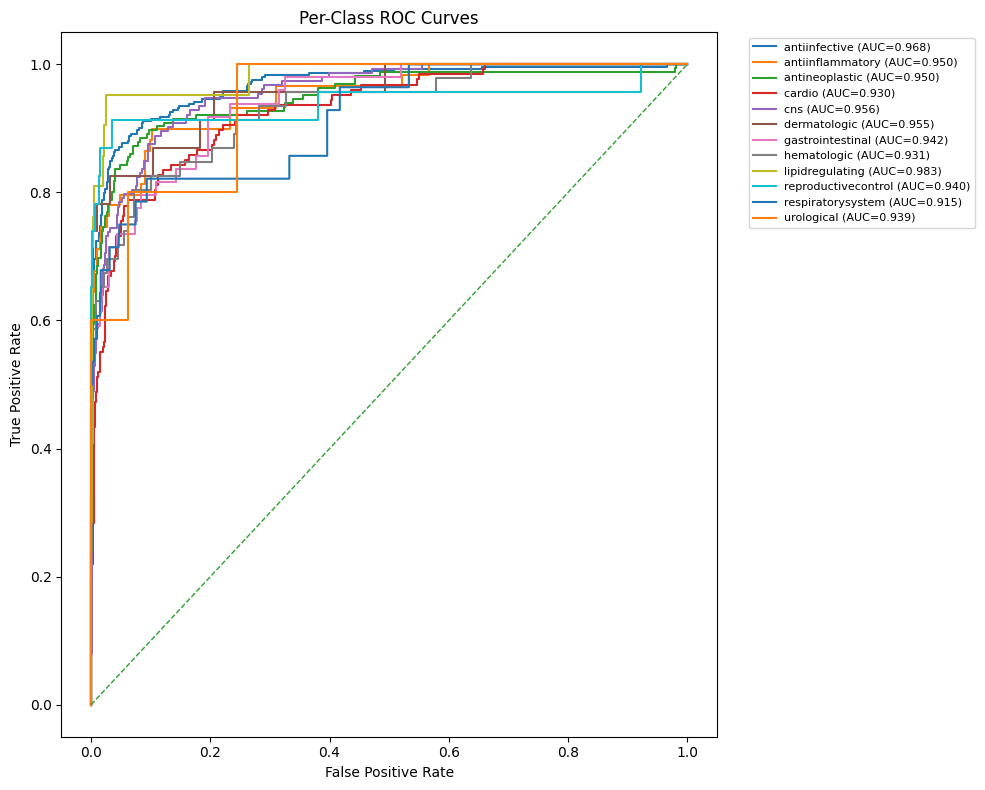

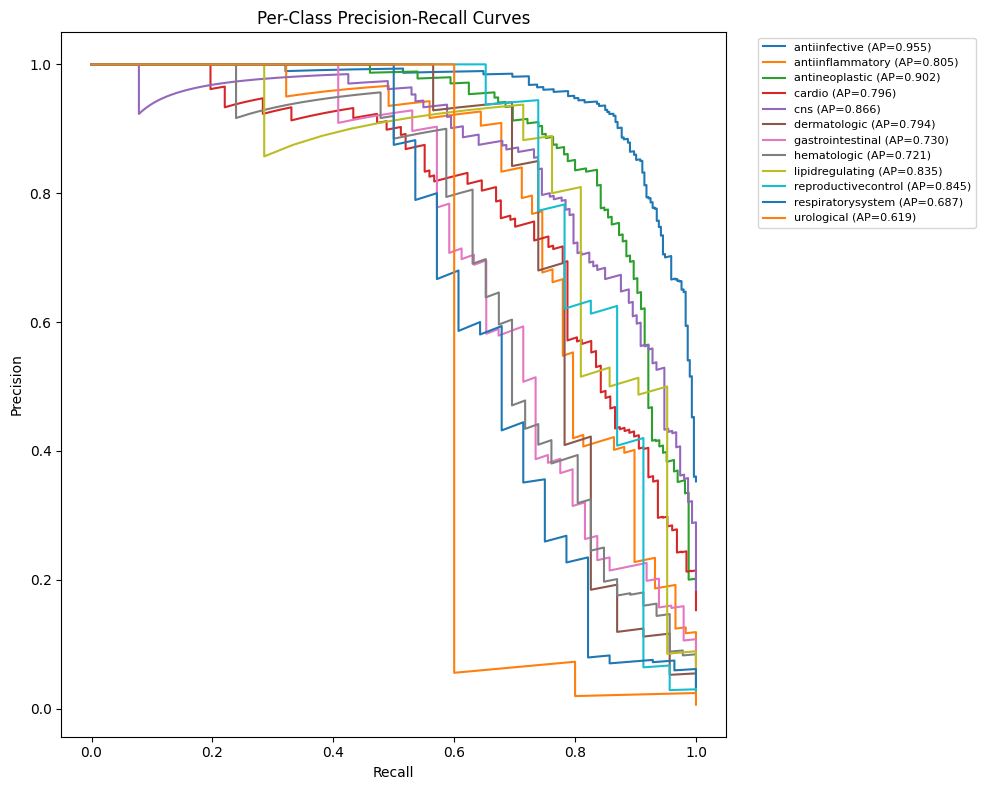

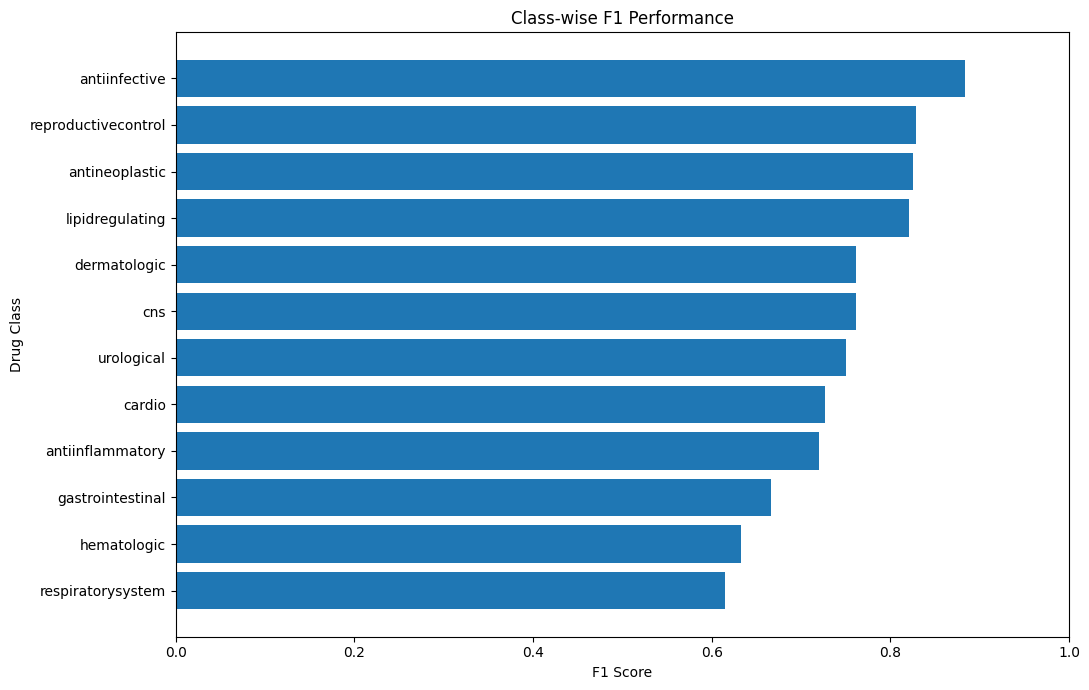

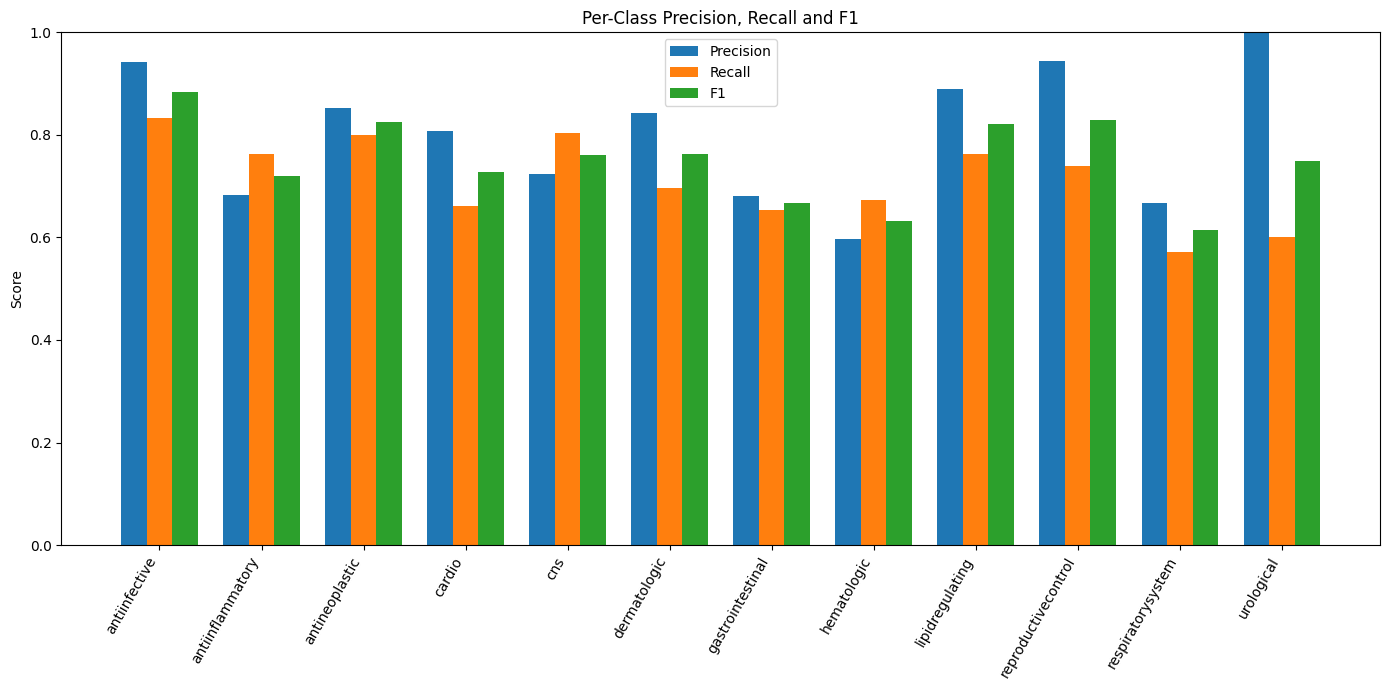

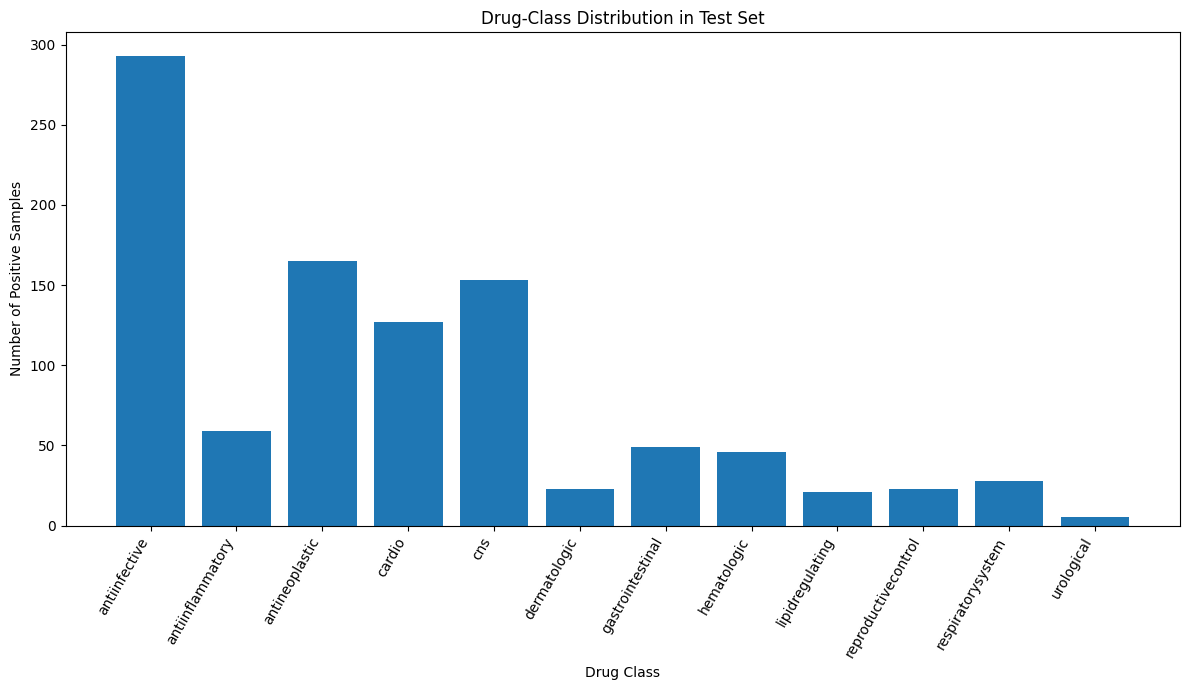

,Sample_Index,True_Labels,Predicted_Labels,TP_Count,FP_Count,FN_Count,Error_Count
732,732,antiinfective;cardio;hematologic;respiratorysy...,cns,0,1,4,5
806,806,antiinfective;antineoplastic;cardio,cns;hematologic,0,2,3,5
282,282,antiinfective;antineoplastic;cardio;hematologi...,hematologic,1,0,4,4
332,332,antiinflammatory;cardio;gastrointestinal;hemat...,,0,0,4,4
756,756,cardio;hematologic,antineoplastic;cns,0,2,2,4
576,576,cardio;hematologic,antiinflammatory;cns,0,2,2,4
753,753,cns;respiratorysystem,antiinfective,0,1,2,3
759,759,antiinflammatory;antineoplastic;cardio;hematol...,antiinflammatory,1,0,3,3
251,251,cardio;hematologic,antineoplastic,0,1,2,3
329,329,cardio,antiinfective;antineoplastic,0,2,1,3


,Drug_Class,TN,FP,FN,TP
0,antiinfective,523,15,49,244
1,antiinflammatory,751,21,14,45
2,antineoplastic,643,23,33,132
3,cardio,684,20,43,84
4,cns,631,47,30,123
5,dermatologic,805,3,7,16
6,gastrointestinal,767,15,17,32
7,hematologic,764,21,15,31
8,lipidregulating,808,2,5,16
9,reproductivecontrol,807,1,6,17


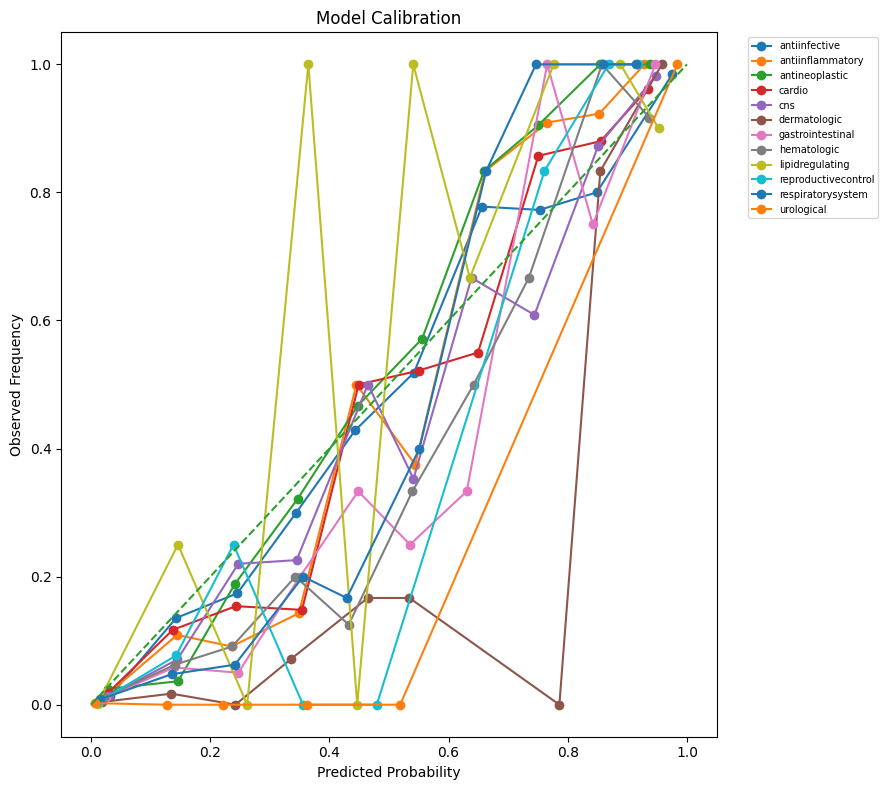

                              Model  Macro_F1  Micro_F1  Weighted_F1  Macro_AUROC  Micro_AUROC  Macro_AUPRC  Micro_AUPRC
                          ChemBERTa  0.558966  0.595284     0.585794     0.884098     0.908873     0.610430     0.611315
                  ChemBERTa + GATv2  0.714579  0.776025     0.774276     0.938436     0.964668     0.789712     0.859968
ChemBERTa + GATv2 + Cross-Attention  0.747100  0.790000     0.787200     0.945700     0.964100     0.793900     0.862400


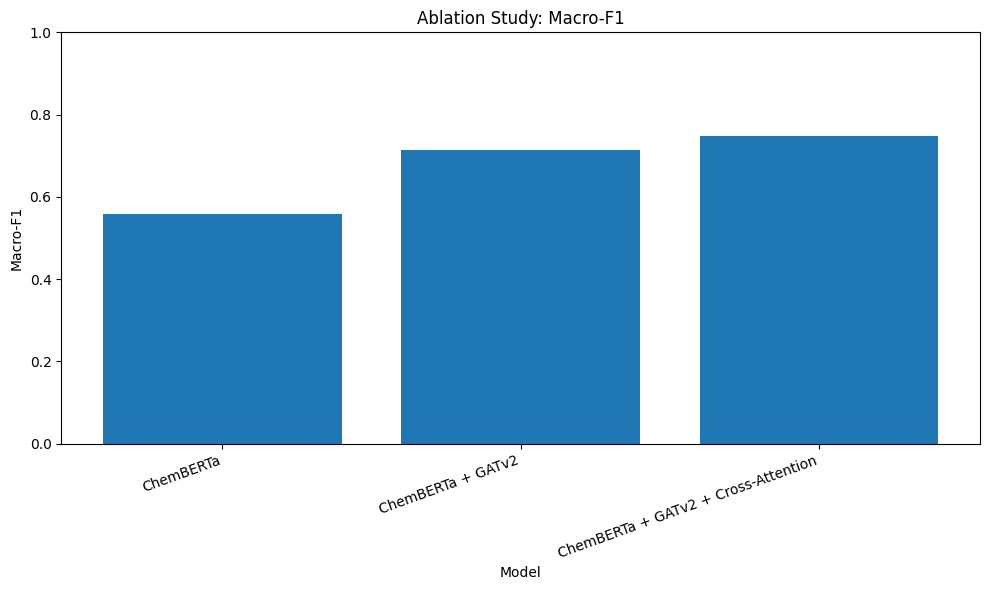

                 Comparison  Absolute_Improvement
0        ChemBERTa → +GATv2              0.155613
1  GATv2 → +Cross-Attention              0.032521
2   ChemBERTa → Final Model              0.188134

Overall relative Macro-F1 improvement: 33.66%

Publication table:


,Label_ID,Drug_Class,Support,Negative,Positive_Percentage,Threshold,Precision,Recall,F1,AUROC,AUPRC
0,0,antiinfective,293,538,35.258724,0.58,0.9421,0.8328,0.8841,0.9678,0.9546
1,1,antiinflammatory,59,772,7.099880,0.31,0.6818,0.7627,0.7200,0.9501,0.8053
2,2,antineoplastic,165,666,19.855596,0.42,0.8516,0.8000,0.8250,0.9504,0.9015
3,3,cardio,127,704,15.282792,0.56,0.8077,0.6614,0.7273,0.9300,0.7964
4,4,cns,153,678,18.411552,0.35,0.7235,0.8039,0.7616,0.9559,0.8661
5,5,dermatologic,23,808,2.767750,0.69,0.8421,0.6957,0.7619,0.9550,0.7941
6,6,gastrointestinal,49,782,5.896510,0.43,0.6809,0.6531,0.6667,0.9416,0.7302
7,7,hematologic,46,785,5.535499,0.34,0.5962,0.6739,0.6327,0.9309,0.7208
8,8,lipidregulating,21,810,2.527076,0.54,0.8889,0.7619,0.8205,0.9833,0.8354
9,9,reproductivecontrol,23,808,2.767750,0.68,0.9444,0.7391,0.8293,0.9402,0.8454




PUBLICATION-QUALITY FINAL STUDY

Model:
ChemBERTa + GATv2 + Cross-Attention

Final Performance:
Macro Precision : 0.8022
Macro Recall    : 0.7130
Macro F1        : 0.7495
Micro F1        : 0.7878
Weighted F1     : 0.7894
Macro AUROC     : 0.9466
Micro AUROC     : 0.9649
Macro AUPRC     : 0.7963
Micro AUPRC     : 0.8651
Hamming Loss    : 0.0410

95% Confidence Intervals:
         Metric     Mean  Lower_95CI  Upper_95CI
Macro Precision 0.796942    0.720100    0.835638
   Macro Recall 0.711732    0.651146    0.765721
       Macro F1 0.743290    0.681435    0.786247
       Micro F1 0.787702    0.762505    0.813476
    Macro AUROC 0.946417    0.929830    0.960161
    Macro AUPRC 0.796130    0.737340    0.845049


FILES GENERATED
Metrics      : /content/drive/MyDrive/dataset/publication_results/tables
Figures      : /content/drive/MyDrive/dataset/publication_results/figures

Publication study completed.


In [295]:
# ================================================================
# PUBLICATION-QUALITY FINAL STUDY
# ChemBERTa + GATv2 + Cross-Attention
# Multi-label Drug Classification from SMILES
# ================================================================

# ================================================================
# CELL 1 — IMPORTS
# ================================================================

import os
import random
import warnings
import numpy as np
import pandas as pd

import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    roc_curve,
    precision_recall_curve,
    multilabel_confusion_matrix,
    hamming_loss,
    accuracy_score
)

warnings.filterwarnings("ignore")


# ================================================================
# CELL 2 — REPRODUCIBILITY
# ================================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


# ================================================================
# CELL 3 — RESULT DIRECTORY
# ================================================================

RESULT_DIR = "/content/drive/MyDrive/dataset/publication_results"

os.makedirs(
    RESULT_DIR,
    exist_ok=True
)

FIG_DIR = os.path.join(
    RESULT_DIR,
    "figures"
)

TABLE_DIR = os.path.join(
    RESULT_DIR,
    "tables"
)

os.makedirs(
    FIG_DIR,
    exist_ok=True
)

os.makedirs(
    TABLE_DIR,
    exist_ok=True
)

print("Results directory:")
print(RESULT_DIR)


# ================================================================
# CELL 4 — VERIFY VARIABLES
# ================================================================

required_objects = [
    "test_true",
    "test_prob",
    "test_pred",
    "mlb",
    "best_thresholds"
]

missing = [
    x for x in required_objects
    if x not in globals()
]

if missing:

    raise RuntimeError(
        "Missing variables:\n" +
        "\n".join(missing)
    )

print("All evaluation variables are available.")


# ================================================================
# CELL 5 — CONVERT TO NUMPY
# ================================================================

y_true = np.asarray(
    test_true
).astype(int)

y_prob = np.asarray(
    test_prob
).astype(float)

y_pred = np.asarray(
    test_pred
).astype(int)

class_names = np.asarray(
    mlb.classes_
)

NUM_LABELS = len(
    class_names
)

print("Test samples :", len(y_true))
print("Classes      :", NUM_LABELS)
print("Class names  :", class_names.tolist())


# ================================================================
# CELL 6 — VERIFY DIMENSIONS
# ================================================================

assert y_true.shape == y_prob.shape
assert y_true.shape == y_pred.shape

assert y_true.shape[1] == NUM_LABELS

print(
    "Prediction matrices:",
    y_true.shape
)


# ================================================================
# CELL 7 — FINAL GLOBAL METRICS
# ================================================================

macro_precision = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

micro_precision = precision_score(
    y_true,
    y_pred,
    average="micro",
    zero_division=0
)

micro_recall = recall_score(
    y_true,
    y_pred,
    average="micro",
    zero_division=0
)

micro_f1 = f1_score(
    y_true,
    y_pred,
    average="micro",
    zero_division=0
)

weighted_f1 = f1_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

macro_auroc = roc_auc_score(
    y_true,
    y_prob,
    average="macro"
)

micro_auroc = roc_auc_score(
    y_true,
    y_prob,
    average="micro"
)

macro_auprc = average_precision_score(
    y_true,
    y_prob,
    average="macro"
)

micro_auprc = average_precision_score(
    y_true,
    y_prob,
    average="micro"
)

hamming = hamming_loss(
    y_true,
    y_pred
)


# ================================================================
# CELL 8 — FINAL METRIC TABLE
# ================================================================

final_metrics = pd.DataFrame({

    "Metric": [

        "Macro Precision",
        "Macro Recall",
        "Macro F1",

        "Micro Precision",
        "Micro Recall",
        "Micro F1",

        "Weighted F1",

        "Macro AUROC",
        "Micro AUROC",

        "Macro AUPRC",
        "Micro AUPRC",

        "Hamming Loss"
    ],

    "Score": [

        macro_precision,
        macro_recall,
        macro_f1,

        micro_precision,
        micro_recall,
        micro_f1,

        weighted_f1,

        macro_auroc,
        micro_auroc,

        macro_auprc,
        micro_auprc,

        hamming
    ]
})

print("\n")
print("=" * 70)
print("FINAL MODEL PERFORMANCE")
print("=" * 70)

print(
    final_metrics.to_string(
        index=False
    )
)

final_metrics.to_csv(
    os.path.join(
        TABLE_DIR,
        "final_metrics.csv"
    ),
    index=False
)


# ================================================================
# CELL 9 — PER-CLASS METRICS
# ================================================================

precision_label = precision_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

recall_label = recall_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

f1_label = f1_score(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

auroc_label = []

auprc_label = []

for i in range(NUM_LABELS):

    try:

        auroc = roc_auc_score(
            y_true[:, i],
            y_prob[:, i]
        )

    except:

        auroc = np.nan

    try:

        auprc = average_precision_score(
            y_true[:, i],
            y_prob[:, i]
        )

    except:

        auprc = np.nan

    auroc_label.append(
        auroc
    )

    auprc_label.append(
        auprc
    )


support = y_true.sum(
    axis=0
)

negative = (
    len(y_true) - support
)

positive_percentage = (
    support / len(y_true)
) * 100


per_class = pd.DataFrame({

    "Label_ID":
        np.arange(NUM_LABELS),

    "Drug_Class":
        class_names,

    "Support":
        support,

    "Negative":
        negative,

    "Positive_Percentage":
        positive_percentage,

    "Threshold":
        np.asarray(
            best_thresholds
        ),

    "Precision":
        precision_label,

    "Recall":
        recall_label,

    "F1":
        f1_label,

    "AUROC":
        auroc_label,

    "AUPRC":
        auprc_label
})


print("\n")
print("=" * 70)
print("PER-CLASS PERFORMANCE")
print("=" * 70)

print(
    per_class.to_string(
        index=False
    )
)

per_class.to_csv(
    os.path.join(
        TABLE_DIR,
        "per_class_metrics.csv"
    ),
    index=False
)


# ================================================================
# CELL 10 — CLASSIFICATION REPORT
# ================================================================

report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(
    report
).transpose()

report_df.to_csv(
    os.path.join(
        TABLE_DIR,
        "classification_report.csv"
    )
)

display(
    report_df
)


# ================================================================
# CELL 11 — 95% BOOTSTRAP CONFIDENCE INTERVAL
# ================================================================

def bootstrap_metric(
    y_true,
    y_prob,
    y_pred,
    metric_function,
    n_bootstrap=1000,
    seed=42
):

    rng = np.random.default_rng(
        seed
    )

    scores = []

    n = len(y_true)

    for _ in range(
        n_bootstrap
    ):

        indices = rng.integers(
            0,
            n,
            size=n
        )

        yt = y_true[
            indices
        ]

        yp = y_pred[
            indices
        ]

        ypr = y_prob[
            indices
        ]

        try:

            score = metric_function(
                yt,
                yp,
                ypr
            )

            if np.isfinite(score):

                scores.append(
                    score
                )

        except:

            pass

    scores = np.asarray(
        scores
    )

    return {

        "Mean":
            np.mean(scores),

        "Lower_95CI":
            np.percentile(
                scores,
                2.5
            ),

        "Upper_95CI":
            np.percentile(
                scores,
                97.5
            )
    }


# ------------------------------------------------
# Metric functions
# ------------------------------------------------

def metric_macro_f1(
    yt,
    yp,
    ypr
):

    return f1_score(
        yt,
        yp,
        average="macro",
        zero_division=0
    )


def metric_micro_f1(
    yt,
    yp,
    ypr
):

    return f1_score(
        yt,
        yp,
        average="micro",
        zero_division=0
    )


def metric_macro_precision(
    yt,
    yp,
    ypr
):

    return precision_score(
        yt,
        yp,
        average="macro",
        zero_division=0
    )


def metric_macro_recall(
    yt,
    yp,
    ypr
):

    return recall_score(
        yt,
        yp,
        average="macro",
        zero_division=0
    )


def metric_macro_auroc(
    yt,
    yp,
    ypr
):

    return roc_auc_score(
        yt,
        ypr,
        average="macro"
    )


def metric_macro_auprc(
    yt,
    yp,
    ypr
):

    return average_precision_score(
        yt,
        ypr,
        average="macro"
    )


bootstrap_results = {}

metrics_to_bootstrap = {

    "Macro Precision":
        metric_macro_precision,

    "Macro Recall":
        metric_macro_recall,

    "Macro F1":
        metric_macro_f1,

    "Micro F1":
        metric_micro_f1,

    "Macro AUROC":
        metric_macro_auroc,

    "Macro AUPRC":
        metric_macro_auprc
}


for name, function in (
    metrics_to_bootstrap.items()
):

    print(
        "Bootstrapping:",
        name
    )

    bootstrap_results[name] = (
        bootstrap_metric(
            y_true,
            y_prob,
            y_pred,
            function,
            n_bootstrap=1000,
            seed=SEED
        )
    )


bootstrap_df = pd.DataFrame(
    bootstrap_results
).T.reset_index()

bootstrap_df.columns = [

    "Metric",
    "Mean",
    "Lower_95CI",
    "Upper_95CI"
]

print("\n")
print(
    bootstrap_df.to_string(
        index=False
    )
)

bootstrap_df.to_csv(
    os.path.join(
        TABLE_DIR,
        "bootstrap_95CI.csv"
    ),
    index=False
)


# ================================================================
# CELL 12 — ROC CURVES
# ================================================================

plt.figure(
    figsize=(10, 8)
)

for i in range(
    NUM_LABELS
):

    fpr, tpr, _ = roc_curve(
        y_true[:, i],
        y_prob[:, i]
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=1.5,
        label=(
            f"{class_names[i]} "
            f"(AUC={auroc_label[i]:.3f})"
        )
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "Per-Class ROC Curves"
)

plt.legend(
    bbox_to_anchor=(1.04, 1),
    loc="upper left",
    fontsize=8
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIG_DIR,
        "per_class_ROC.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# CELL 13 — PRECISION-RECALL CURVES
# ================================================================

plt.figure(
    figsize=(10, 8)
)

for i in range(
    NUM_LABELS
):

    precision_curve, recall_curve, _ = (
        precision_recall_curve(
            y_true[:, i],
            y_prob[:, i]
        )
    )

    plt.plot(
        recall_curve,
        precision_curve,
        linewidth=1.5,
        label=(
            f"{class_names[i]} "
            f"(AP={auprc_label[i]:.3f})"
        )
    )

plt.xlabel(
    "Recall"
)

plt.ylabel(
    "Precision"
)

plt.title(
    "Per-Class Precision-Recall Curves"
)

plt.legend(
    bbox_to_anchor=(1.04, 1),
    loc="upper left",
    fontsize=8
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIG_DIR,
        "per_class_PR.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# CELL 14 — F1 BY DRUG CLASS
# ================================================================

plot_df = (
    per_class
    .sort_values(
        "F1"
    )
)

plt.figure(
    figsize=(11, 7)
)

plt.barh(
    plot_df["Drug_Class"],
    plot_df["F1"]
)

plt.xlabel(
    "F1 Score"
)

plt.ylabel(
    "Drug Class"
)

plt.title(
    "Class-wise F1 Performance"
)

plt.xlim(
    0,
    1
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIG_DIR,
        "classwise_F1.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# CELL 15 — PRECISION / RECALL / F1
# ================================================================

x = np.arange(
    NUM_LABELS
)

width = 0.25

plt.figure(
    figsize=(14, 7)
)

plt.bar(
    x - width,
    precision_label,
    width,
    label="Precision"
)

plt.bar(
    x,
    recall_label,
    width,
    label="Recall"
)

plt.bar(
    x + width,
    f1_label,
    width,
    label="F1"
)

plt.xticks(
    x,
    class_names,
    rotation=60,
    ha="right"
)

plt.ylabel(
    "Score"
)

plt.ylim(
    0,
    1
)

plt.title(
    "Per-Class Precision, Recall and F1"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIG_DIR,
        "precision_recall_f1.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# CELL 16 — DATASET CLASS DISTRIBUTION
# ================================================================

plt.figure(
    figsize=(12, 7)
)

plt.bar(
    class_names,
    support
)

plt.xticks(
    rotation=60,
    ha="right"
)

plt.ylabel(
    "Number of Positive Samples"
)

plt.xlabel(
    "Drug Class"
)

plt.title(
    "Drug-Class Distribution in Test Set"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIG_DIR,
        "class_distribution.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# CELL 17 — THRESHOLD VS F1 ANALYSIS
# ================================================================

threshold_grid = np.arange(
    0.10,
    0.91,
    0.01
)

threshold_results = []

for class_id in range(
    NUM_LABELS
):

    for threshold in (
        threshold_grid
    ):

        predictions = (
            y_prob[:, class_id]
            >= threshold
        ).astype(int)

        score = f1_score(
            y_true[:, class_id],
            predictions,
            zero_division=0
        )

        threshold_results.append({

            "Label_ID":
                class_id,

            "Drug_Class":
                class_names[
                    class_id
                ],

            "Threshold":
                threshold,

            "F1":
                score
        })

threshold_df = pd.DataFrame(
    threshold_results
)

threshold_df.to_csv(
    os.path.join(
        TABLE_DIR,
        "threshold_analysis.csv"
    ),
    index=False
)


# ================================================================
# CELL 18 — ERROR ANALYSIS
# ================================================================

error_rows = []

for i in range(
    len(y_true)
):

    true_labels = np.where(
        y_true[i] == 1
    )[0]

    predicted_labels = np.where(
        y_pred[i] == 1
    )[0]

    fp = np.setdiff1d(
        predicted_labels,
        true_labels
    )

    fn = np.setdiff1d(
        true_labels,
        predicted_labels
    )

    tp = np.intersect1d(
        true_labels,
        predicted_labels
    )

    error_rows.append({

        "Sample_Index":
            i,

        "True_Labels":
            ";".join(
                class_names[
                    true_labels
                ]
            ),

        "Predicted_Labels":
            ";".join(
                class_names[
                    predicted_labels
                ]
            ),

        "TP_Count":
            len(tp),

        "FP_Count":
            len(fp),

        "FN_Count":
            len(fn),

        "Error_Count":
            len(fp) + len(fn)
    })

error_df = pd.DataFrame(
    error_rows
)

error_df = (
    error_df
    .sort_values(
        "Error_Count",
        ascending=False
    )
)

error_df.to_csv(
    os.path.join(
        TABLE_DIR,
        "error_analysis.csv"
    ),
    index=False
)

display(
    error_df.head(20)
)


# ================================================================
# CELL 19 — MULTILABEL CONFUSION MATRICES
# ================================================================

mcm = multilabel_confusion_matrix(
    y_true,
    y_pred
)

confusion_rows = []

for i in range(
    NUM_LABELS
):

    tn, fp, fn, tp = (
        mcm[i].ravel()
    )

    confusion_rows.append({

        "Drug_Class":
            class_names[i],

        "TN":
            tn,

        "FP":
            fp,

        "FN":
            fn,

        "TP":
            tp
    })

confusion_df = pd.DataFrame(
    confusion_rows
)

confusion_df.to_csv(
    os.path.join(
        TABLE_DIR,
        "multilabel_confusion_matrix.csv"
    ),
    index=False
)

display(
    confusion_df
)


# ================================================================
# CELL 20 — FALSE POSITIVE / FALSE NEGATIVE ANALYSIS
# ================================================================

confusion_df["FP_Rate"] = (
    confusion_df["FP"]
    /
    (
        confusion_df["FP"]
        +
        confusion_df["TN"]
        +
        1e-10
    )
)

confusion_df["FN_Rate"] = (
    confusion_df["FN"]
    /
    (
        confusion_df["FN"]
        +
        confusion_df["TP"]
        +
        1e-10
    )
)

confusion_df.to_csv(
    os.path.join(
        TABLE_DIR,
        "class_error_rates.csv"
    ),
    index=False
)


# ================================================================
# CELL 21 — PREDICTION CONFIDENCE
# ================================================================

confidence_rows = []

for i in range(
    len(y_prob)
):

    confidence_rows.append({

        "Sample_Index":
            i,

        "Maximum_Probability":
            np.max(
                y_prob[i]
            ),

        "Mean_Probability":
            np.mean(
                y_prob[i]
            ),

        "Number_True_Labels":
            np.sum(
                y_true[i]
            ),

        "Number_Predicted_Labels":
            np.sum(
                y_pred[i]
            )
    })

confidence_df = pd.DataFrame(
    confidence_rows
)

confidence_df.to_csv(
    os.path.join(
        TABLE_DIR,
        "prediction_confidence.csv"
    ),
    index=False
)


# ================================================================
# CELL 22 — CALIBRATION ANALYSIS
# ================================================================

calibration_rows = []

for i in range(
    NUM_LABELS
):

    bins = np.linspace(
        0,
        1,
        11
    )

    for j in range(
        len(bins) - 1
    ):

        lower = bins[j]
        upper = bins[j + 1]

        if j == len(bins) - 2:

            mask = (
                (y_prob[:, i] >= lower)
                &
                (y_prob[:, i] <= upper)
            )

        else:

            mask = (
                (y_prob[:, i] >= lower)
                &
                (y_prob[:, i] < upper)
            )

        if mask.sum() == 0:

            continue

        calibration_rows.append({

            "Drug_Class":
                class_names[i],

            "Bin_Lower":
                lower,

            "Bin_Upper":
                upper,

            "Mean_Probability":
                y_prob[
                    mask,
                    i
                ].mean(),

            "Observed_Frequency":
                y_true[
                    mask,
                    i
                ].mean(),

            "Count":
                mask.sum()
        })

calibration_df = pd.DataFrame(
    calibration_rows
)

calibration_df.to_csv(
    os.path.join(
        TABLE_DIR,
        "calibration.csv"
    ),
    index=False
)


# ================================================================
# CELL 23 — CALIBRATION PLOT
# ================================================================

plt.figure(
    figsize=(9, 8)
)

for class_name in class_names:

    temp = calibration_df[
        calibration_df[
            "Drug_Class"
        ] == class_name
    ]

    if len(temp) == 0:
        continue

    plt.plot(
        temp["Mean_Probability"],
        temp["Observed_Frequency"],
        marker="o",
        linewidth=1.5,
        label=class_name
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel(
    "Predicted Probability"
)

plt.ylabel(
    "Observed Frequency"
)

plt.title(
    "Model Calibration"
)

plt.legend(
    bbox_to_anchor=(1.04, 1),
    loc="upper left",
    fontsize=7
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIG_DIR,
        "calibration.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# CELL 24 — MODEL COMPARISON / ABLATION
# ================================================================

ablation = pd.DataFrame({

    "Model": [

        "ChemBERTa",

        "ChemBERTa + GATv2",

        "ChemBERTa + GATv2 + Cross-Attention"
    ],

    "Macro_F1": [

        0.558966,

        0.714579,

        0.747100
    ],

    "Micro_F1": [

        0.595284,

        0.776025,

        0.790000
    ],

    "Weighted_F1": [

        0.585794,

        0.774276,

        0.787200
    ],

    "Macro_AUROC": [

        0.884098,

        0.938436,

        0.945700
    ],

    "Micro_AUROC": [

        0.908873,

        0.964668,

        0.964100
    ],

    "Macro_AUPRC": [

        0.610430,

        0.789712,

        0.793900
    ],

    "Micro_AUPRC": [

        0.611315,

        0.859968,

        0.862400
    ]
})

print(
    ablation.to_string(
        index=False
    )
)

ablation.to_csv(
    os.path.join(
        TABLE_DIR,
        "ablation_comparison.csv"
    ),
    index=False
)


# ================================================================
# CELL 25 — ABLATION MACRO-F1 FIGURE
# ================================================================

plt.figure(
    figsize=(10, 6)
)

plt.bar(
    ablation["Model"],
    ablation["Macro_F1"]
)

plt.ylabel(
    "Macro-F1"
)

plt.xlabel(
    "Model"
)

plt.ylim(
    0,
    1
)

plt.title(
    "Ablation Study: Macro-F1"
)

plt.xticks(
    rotation=20,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIG_DIR,
        "ablation_macro_f1.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# CELL 26 — IMPROVEMENT CALCULATION
# ================================================================

baseline_f1 = 0.558966

gat_f1 = 0.714579

final_f1 = 0.747100

improvement_gat = (
    gat_f1 -
    baseline_f1
)

improvement_cross = (
    final_f1 -
    gat_f1
)

total_improvement = (
    final_f1 -
    baseline_f1
)

relative_improvement = (
    total_improvement /
    baseline_f1
) * 100

improvement_table = pd.DataFrame({

    "Comparison": [

        "ChemBERTa → +GATv2",

        "GATv2 → +Cross-Attention",

        "ChemBERTa → Final Model"
    ],

    "Absolute_Improvement": [

        improvement_gat,

        improvement_cross,

        total_improvement
    ]
})

print(
    improvement_table
)

improvement_table.to_csv(
    os.path.join(
        TABLE_DIR,
        "performance_improvement.csv"
    ),
    index=False
)

print(
    f"\nOverall relative Macro-F1 improvement: "
    f"{relative_improvement:.2f}%"
)


# ================================================================
# CELL 27 — PUBLICATION TABLE
# ================================================================

publication_table = per_class.copy()

publication_table[
    "Precision"
] = publication_table[
    "Precision"
].round(4)

publication_table[
    "Recall"
] = publication_table[
    "Recall"
].round(4)

publication_table[
    "F1"
] = publication_table[
    "F1"
].round(4)

publication_table[
    "AUROC"
] = publication_table[
    "AUROC"
].round(4)

publication_table[
    "AUPRC"
] = publication_table[
    "AUPRC"
].round(4)

publication_table[
    "Threshold"
] = publication_table[
    "Threshold"
].round(3)

publication_table.to_csv(
    os.path.join(
        TABLE_DIR,
        "TABLE_per_class_performance.csv"
    ),
    index=False
)

print(
    "\nPublication table:"
)

display(
    publication_table
)


# ================================================================
# CELL 28 — FINAL SUMMARY
# ================================================================

print("\n")
print("=" * 80)
print("PUBLICATION-QUALITY FINAL STUDY")
print("=" * 80)

print(
    "\nModel:"
)

print(
    "ChemBERTa + GATv2 + Cross-Attention"
)

print(
    "\nFinal Performance:"
)

print(
    f"Macro Precision : {macro_precision:.4f}"
)

print(
    f"Macro Recall    : {macro_recall:.4f}"
)

print(
    f"Macro F1        : {macro_f1:.4f}"
)

print(
    f"Micro F1        : {micro_f1:.4f}"
)

print(
    f"Weighted F1     : {weighted_f1:.4f}"
)

print(
    f"Macro AUROC     : {macro_auroc:.4f}"
)

print(
    f"Micro AUROC     : {micro_auroc:.4f}"
)

print(
    f"Macro AUPRC     : {macro_auprc:.4f}"
)

print(
    f"Micro AUPRC     : {micro_auprc:.4f}"
)

print(
    f"Hamming Loss    : {hamming:.4f}"
)

print("\n95% Confidence Intervals:")

print(
    bootstrap_df.to_string(
        index=False
    )
)

print("\n")
print("=" * 80)
print("FILES GENERATED")
print("=" * 80)

print(
    "Metrics      :", TABLE_DIR
)

print(
    "Figures      :", FIG_DIR
)

print(
    "\nPublication study completed."
)

print("=" * 80)

In [296]:
# ============================================================
# CELL 3
# CHEMBERTA + ENHANCED GATV2 + BIDIRECTIONAL CROSS-ATTENTION
# ============================================================

from transformers import AutoTokenizer, AutoModel

MODEL_NAME = "seyonec/ChemBERTa-zinc-base-v1"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

chemberta = AutoModel.from_pretrained(
    MODEL_NAME
)

CHEMBERTA_DIM = chemberta.config.hidden_size

print(
    "ChemBERTa hidden size:",
    CHEMBERTA_DIM
)


# ============================================================
# SIMPLE GATv2-LIKE GRAPH ATTENTION LAYER
# ============================================================

class GATv2Layer(nn.Module):

    def __init__(
        self,
        in_dim,
        out_dim,
        edge_dim,
        heads=4,
        dropout=0.1
    ):

        super().__init__()

        self.heads = heads
        self.out_dim = out_dim

        self.lin = nn.Linear(
            in_dim,
            out_dim * heads,
            bias=False
        )

        self.edge_lin = nn.Linear(
            edge_dim,
            out_dim * heads,
            bias=False
        )

        self.att = nn.Parameter(
            torch.randn(
                heads,
                out_dim
            )
        )

        self.dropout = nn.Dropout(dropout)

        self.norm = nn.LayerNorm(
            out_dim * heads
        )

    def forward(
        self,
        x,
        edge_index,
        edge_attr
    ):

        N = x.size(0)

        h = self.lin(x)

        h = h.view(
            N,
            self.heads,
            self.out_dim
        )

        if edge_index.shape[1] == 0:
            return h.reshape(
                N,
                self.heads * self.out_dim
            )

        src = edge_index[0]
        dst = edge_index[1]

        # Edge contribution
        e = self.edge_lin(edge_attr)

        e = e.view(
            -1,
            self.heads,
            self.out_dim
        )

        # Attention score
        score = (
            h[src] +
            h[dst] +
            e
        )

        score = torch.tanh(score)

        score = (
            score *
            self.att.unsqueeze(0)
        ).sum(dim=-1)

        score = F.leaky_relu(
            score,
            negative_slope=0.2
        )

        # Softmax over incoming edges
        alpha = torch.zeros_like(score)

        for head in range(self.heads):

            alpha[:, head] = self.segment_softmax(
                score[:, head],
                dst,
                N
            )

        alpha = self.dropout(alpha)

        messages = (
            h[src] +
            e
        ) * alpha.unsqueeze(-1)

        out = torch.zeros(
            N,
            self.heads,
            self.out_dim,
            device=x.device
        )

        for i in range(messages.shape[0]):

            out[dst[i]] += messages[i]

        out = out.reshape(
            N,
            self.heads * self.out_dim
        )

        return self.norm(out)

    @staticmethod
    def segment_softmax(
        values,
        index,
        num_nodes
    ):

        result = torch.zeros_like(values)

        for i in range(num_nodes):

            mask = index == i

            if mask.any():

                result[mask] = torch.softmax(
                    values[mask],
                    dim=0
                )

        return result


# ============================================================
# GAT ENCODER
# ============================================================

class EnhancedGAT(nn.Module):

    def __init__(
        self,
        atom_dim,
        edge_dim,
        hidden=64
    ):

        super().__init__()

        self.gat1 = GATv2Layer(
            atom_dim,
            hidden,
            edge_dim,
            heads=4
        )

        self.gat2 = GATv2Layer(
            hidden * 4,
            hidden,
            edge_dim,
            heads=4
        )

        self.output_dim = hidden * 4

    def forward(
        self,
        x,
        edge_index,
        edge_attr
    ):

        x = self.gat1(
            x,
            edge_index,
            edge_attr
        )

        x = F.elu(x)

        x = self.gat2(
            x,
            edge_index,
            edge_attr
        )

        x = F.elu(x)

        return x


# ============================================================
# BIDIRECTIONAL CROSS-ATTENTION
# ============================================================

class BidirectionalCrossAttention(nn.Module):

    def __init__(
        self,
        text_dim,
        graph_dim,
        hidden_dim=256,
        heads=8
    ):

        super().__init__()

        self.text_proj = nn.Linear(
            text_dim,
            hidden_dim
        )

        self.graph_proj = nn.Linear(
            graph_dim,
            hidden_dim
        )

        # Text queries graph
        self.text_to_graph = nn.MultiheadAttention(
            hidden_dim,
            heads,
            batch_first=True
        )

        # Graph queries text
        self.graph_to_text = nn.MultiheadAttention(
            hidden_dim,
            heads,
            batch_first=True
        )

        self.norm_text = nn.LayerNorm(
            hidden_dim
        )

        self.norm_graph = nn.LayerNorm(
            hidden_dim
        )

    def forward(
        self,
        text,
        graph
    ):

        text = self.text_proj(text)

        graph = self.graph_proj(graph)

        # ----------------------------------------------------
        # Text → Graph
        # ----------------------------------------------------

        t2g, _ = self.text_to_graph(
            query=text,
            key=graph,
            value=graph
        )

        text_out = self.norm_text(
            text + t2g
        )

        # ----------------------------------------------------
        # Graph → Text
        # ----------------------------------------------------

        g2t, _ = self.graph_to_text(
            query=graph,
            key=text,
            value=text
        )

        graph_out = self.norm_graph(
            graph + g2t
        )

        return (
            text_out,
            graph_out
        )


# ============================================================
# COMPLETE MODEL
# ============================================================

class SIDERMultimodalModel(nn.Module):

    def __init__(
        self,
        num_labels,
        atom_dim,
        edge_dim,
        descriptor_dim
    ):

        super().__init__()

        self.chemberta = chemberta

        self.gat = EnhancedGAT(
            atom_dim,
            edge_dim
        )

        self.cross_attention = (
            BidirectionalCrossAttention(
                CHEMBERTA_DIM,
                self.gat.output_dim
            )
        )

        self.descriptor_projection = nn.Sequential(

            nn.Linear(
                descriptor_dim,
                128
            ),

            nn.LayerNorm(128),

            nn.ReLU(),

            nn.Dropout(0.2)
        )

        self.classifier = nn.Sequential(

            nn.Linear(
                256 + 256 + 128,
                512
            ),

            nn.LayerNorm(512),

            nn.GELU(),

            nn.Dropout(0.3),

            nn.Linear(
                512,
                256
            ),

            nn.GELU(),

            nn.Dropout(0.2),

            nn.Linear(
                256,
                num_labels
            )
        )

    def forward(
        self,
        input_ids,
        attention_mask,
        graph_data,
        descriptors
    ):

        # ====================================================
        # CHEMBERTA
        # ====================================================

        outputs = self.chemberta(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        text_features = outputs.last_hidden_state

        # ====================================================
        # GRAPH
        # ====================================================

        x, edge_index, edge_attr = graph_data

        graph_features = self.gat(
            x,
            edge_index,
            edge_attr
        )

        # ====================================================
        # CROSS ATTENTION
        # ====================================================

        text_out, graph_out = (
            self.cross_attention(
                text_features,
                graph_features.unsqueeze(0)
            )
        )

        # ====================================================
        # POOLING
        # ====================================================

        text_pool = (
            text_out.mean(dim=1)
        )

        graph_pool = (
            graph_out.mean(dim=1)
        )

        # ====================================================
        # RDKit DESCRIPTORS
        # ====================================================

        desc = self.descriptor_projection(
            descriptors.unsqueeze(0)
        )

        # ====================================================
        # FUSION
        # ====================================================

        fused = torch.cat(
            [
                text_pool,
                graph_pool,
                desc
            ],
            dim=-1
        )

        logits = self.classifier(
            fused
        )

        return logits.squeeze(0)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: seyonec/ChemBERTa-zinc-base-v1
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.decoder.weight    | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.decoder.bias      | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


ChemBERTa hidden size: 768


---
# Reproducibility and result-provenance utilities

Use the following cells after training each model variant. They do not train a model automatically; they provide consistent artifact saving and metric calculation once the true test labels and probabilities have been produced by the intended checkpoint.

In [297]:
# Record software versions and experiment configuration.
# Run this cell in the same environment used for training.
import json, os, platform, random
from datetime import datetime

def make_experiment_manifest(experiment_name, config, output_dir):
    os.makedirs(output_dir, exist_ok=True)
    manifest = {
        "experiment_name": experiment_name,
        "created_utc": datetime.utcnow().isoformat(timespec="seconds") + "Z",
        "python": platform.python_version(),
        "platform": platform.platform(),
        "config": config,
        "status": "configuration recorded; verify model/checkpoint provenance separately"
    }
    try:
        import torch, transformers, sklearn
        manifest["torch"] = torch.__version__
        manifest["transformers"] = transformers.__version__
        manifest["scikit_learn"] = sklearn.__version__
        manifest["cuda_available"] = torch.cuda.is_available()
        if torch.cuda.is_available():
            manifest["cuda_version"] = torch.version.cuda
            manifest["gpu"] = torch.cuda.get_device_name(0)
    except Exception as exc:
        manifest["version_capture_warning"] = str(exc)
    with open(os.path.join(output_dir, "experiment_manifest.json"), "w") as f:
        json.dump(manifest, f, indent=2, default=str)
    return manifest


In [298]:
# Recalculate multilabel metrics from the actual locked test predictions.
# y_true and y_prob must be from the SAME test split and intended checkpoint.
import numpy as np
import pandas as pd
from sklearn.metrics import (
    f1_score, precision_score, recall_score,
    roc_auc_score, average_precision_score,
    hamming_loss
)

def calculate_multilabel_metrics(y_true, y_prob, thresholds=0.5):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob, dtype=float)
    if y_true.shape != y_prob.shape:
        raise ValueError(f"Shape mismatch: y_true={y_true.shape}, y_prob={y_prob.shape}")
    if y_true.ndim != 2:
        raise ValueError("Expected [n_samples, n_labels] arrays.")
    thresholds = np.asarray(thresholds)
    if thresholds.ndim == 0:
        y_pred = (y_prob >= float(thresholds)).astype(int)
    else:
        if len(thresholds) != y_true.shape[1]:
            raise ValueError("One frozen threshold is required per label.")
        y_pred = (y_prob >= thresholds.reshape(1, -1)).astype(int)

    result = {
        "macro_precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "micro_f1": f1_score(y_true, y_pred, average="micro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "hamming_loss": hamming_loss(y_true, y_pred),
    }
    # AUROC/AUPRC are probability-based. Undefined labels may make macro AUROC unavailable.
    try:
        result["macro_auroc"] = roc_auc_score(y_true, y_prob, average="macro")
        result["micro_auroc"] = roc_auc_score(y_true, y_prob, average="micro")
    except ValueError:
        result["macro_auroc"] = np.nan
        result["micro_auroc"] = np.nan
    try:
        result["macro_auprc"] = average_precision_score(y_true, y_prob, average="macro")
        result["micro_auprc"] = average_precision_score(y_true, y_prob, average="micro")
    except ValueError:
        result["macro_auprc"] = np.nan
        result["micro_auprc"] = np.nan
    return result


In [299]:
# Save prediction arrays, frozen thresholds, metrics, and a provenance note.
# Before running, define:
#   y_test_true = test labels from the fixed test split
#   y_test_prob = probabilities from the saved checkpoint being evaluated
#   thresholds = scalar 0.5 or thresholds selected using validation predictions only
#   experiment_name and output_dir

def save_evaluation_artifacts(
    y_test_true, y_test_prob, thresholds, experiment_name, output_dir,
    label_names=None, checkpoint_path=None, split_description="fixed test split"
):
    os.makedirs(output_dir, exist_ok=True)
    y_test_true = np.asarray(y_test_true)
    y_test_prob = np.asarray(y_test_prob)
    metrics = calculate_multilabel_metrics(y_test_true, y_test_prob, thresholds)
    pd.DataFrame([{"experiment": experiment_name, **metrics}]).to_csv(
        os.path.join(output_dir, "final_metrics.csv"), index=False
    )
    np.savez_compressed(
        os.path.join(output_dir, "test_predictions.npz"),
        y_true=y_test_true, y_prob=y_test_prob,
        thresholds=np.asarray(thresholds)
    )
    threshold_values = np.asarray(thresholds)
    if threshold_values.ndim == 0:
        threshold_values = np.repeat(float(threshold_values), y_test_true.shape[1])
    if label_names is None:
        label_names = [f"label_{i}" for i in range(y_test_true.shape[1])]
    pd.DataFrame({
        "label": label_names,
        "threshold": threshold_values,
        "test_positive_support": y_test_true.sum(axis=0).astype(int),
        "test_predicted_positive": (y_test_prob >= threshold_values.reshape(1, -1)).sum(axis=0).astype(int)
    }).to_csv(os.path.join(output_dir, "per_label_test_summary.csv"), index=False)
    provenance = {
        "experiment_name": experiment_name,
        "checkpoint_path": checkpoint_path,
        "split_description": split_description,
        "prediction_shape": list(y_test_prob.shape),
        "threshold_source": "must be validation-only; confirm before publication",
        "metrics_source": "recomputed from saved test labels and probabilities"
    }
    with open(os.path.join(output_dir, "evaluation_provenance.json"), "w") as f:
        json.dump(provenance, f, indent=2)
    return metrics


## Final pre-submission checklist

- [ ] Each reported result is linked to a specific architecture, checkpoint, split, and prediction file.
- [ ] Baseline and proposed model use the same fixed test indices and comparable metric definitions.
- [ ] Thresholds were selected on validation data only and frozen before test evaluation.
- [ ] AUROC/AUPRC are computed from probabilities, not thresholded labels.
- [ ] Descriptor usage is confirmed in the actual forward pass and ablated.
- [ ] Standard GATv2 is compared with the precisely defined enhanced graph module.
- [ ] Tox21 and SIDER results are regenerated from their actual dataset pipelines.
- [ ] Repeated-seed results and uncertainty are reported where claimed.
- [ ] No fabricated, estimated, or manually copied metric is presented as a measured result.
- [ ] Manuscript equations, diagram, code, and model name describe the same implementation.
